# Do Coupons Create Sales, or Just Give Money Away?

**Estimating the causal effect of targeted coupon campaigns on household spending with dunnhumby's "The Complete Journey"**

Causal Modeling — final project · core analysis notebook

---

## One-page summary

**Question.** Over two years a supermarket chain sent 30 coupon campaigns to 1,584 of the 2,500 households in this data set. Did those coupons bring in new spending, or did they just discount purchases the households would have made anyway?

**Why it is hard.** Coupons were not sent at random. The retailer picked the households that shopped most often, so "households that got coupons spend more" tells us nothing.

**What we do.** We first work out how the retailer chose households, draw the causal graph of the problem, and use the backdoor criterion to decide what must be adjusted for (pre-campaign shopping history) and what must not (redemption). Then, for each group of households receiving a campaign for the first time, we find households that were just as active beforehand but had not been chosen yet, and use them as controls. We compare the change in spending of the two groups before and after the campaign (difference-in-differences), and we hold out the last 8 weeks before the campaign purely to check that the controls are comparable. Finally we answer the same question again with the course toolkit: ANCOVA, propensity scores, DoWhy, meta-learners, double machine learning, a doubly robust learner and a causal forest.

**Findings.**

1. **No detectable lift.** After a first campaign, weekly household spending changes by about +1%, with a 95% confidence interval from −8% to +11%. The interval includes zero.
2. **Simple comparisons mislead, in both directions.** A direct comparison says recipients spend more than 4 times as much as non-recipients. A plain difference-in-differences says coupons cut spending by 4% to 10%. Both are artifacts of how households were selected.
3. **The coupons mostly subsidized purchases that would have happened anyway.** 73% of recipient households never redeemed a coupon. 82% of redeemed items were in a product sub-category the household had bought in the previous six months. The share of recipients' spending going to promoted products did not change.
4. **This data set cannot detect small effects.** Reliably detecting a 1% lift would need about 72,000 households per group. What the retailer really needs is a randomly held-out control group each time it sends coupons.
5. **The course's own methods agree.** Every method that passes a placebo test (no "effect" in the weeks before the campaign) puts the campaign's effect within a few percent of zero. A Bayesian network learned from the data keeps no arrow from the campaign to spending.

---

## Contents

| Section | What it does | Course weeks |
|---|---|---|
| 1. Setup | Libraries, paths, plotting style | |
| 2. Data | Eight tables, time range, campaign timeline | |
| 3. Panel | Household × week tables | |
| 4. First impression and two traps | Raw gap, selection rule, regression to the mean, a Simpson's-paradox view | 1, 4 |
| 5. The causal graph | DAG, chains / forks / colliders, backdoor criterion, estimand, testing the graph with DoWhy | 4, 5, 6 |
| 6. Study design | Comparable controls, the check window, four estimators | 3, 7 |
| 7. Main result | Effect of a first campaign on spending | 7 |
| 8. The course toolkit | ANCOVA, propensity scores four ways, DoWhy, S/T/X-learners, double ML, doubly robust learner, causal forest | 1, 3, 5, 6, 7 |
| 9. Mechanism 1 | Who used the coupons, and on what | 6 |
| 10. Mechanism 2 | Did recipients buy more of the promoted products | |
| 11. Heterogeneity, and a tempting mistake | Subgroups, conditioning on a collider, causal-forest CATE | 4, 7 |
| 12. Robustness checks | Other estimators, samples, controls, windows | |
| 13. The experiment that would settle it | Sample size, ANCOVA, blocking, holdout design | 2, 3 |
| 14. Instruments and attribution | LATE with one-sided non-compliance, probability of necessity | 6, 8 |
| 15. Conclusions | Findings, lessons, limitations, recommendations, course map | |
| Appendix A | Bayesian network learned from the data | 9 |
| Appendix B | Repeated campaigns and the g-formula | 7 |
| Appendix C | Measurement error in the confounder | 8 |

> **How to read this notebook.** Every section starts with the question it answers and how, and ends with what the result means. The code is commented step by step. If you only want the conclusions, read the text at the start and end of each section.

## 1. Setup

Import libraries and set paths, the random seed and one plotting style for all figures.

Every number quoted in the report and the slides is stored in a dictionary called `RESULTS` and written to `outputs/results.json` at the end, so each quoted figure can be traced back to this notebook.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---------- paths ----------
# The notebook sits in the project root; the 8 raw CSV files go in data/raw/ (not in the git repo).
ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# ---------- global settings ----------
SEED = 20261119      # fixed seed so the bootstrap results are reproducible
BOOT = 1000          # bootstrap replications (for confidence intervals)
RESULTS = {}         # every number quoted outside this notebook is collected here

# ---------- plotting style ----------
# Colors keep one meaning throughout: blue = coupon recipients / main estimate,
# orange = control group / comparison, grey = background reference.
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
C_INK, C_INK2, C_MUTED = "#0b0b0b", "#52514e", "#898781"
C_GRID, C_AXIS, C_SURF = "#e1e0d9", "#c3c2b7", "#fcfcfb"

mpl.rcParams.update({
    "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.facecolor": C_SURF, "axes.facecolor": C_SURF, "savefig.facecolor": C_SURF,
    "axes.edgecolor": C_AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C_GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 14,
    "axes.labelsize": 10.5, "axes.labelcolor": C_INK2,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 10,
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})


def finish(fig, name, note=None):
    """Add a footnote, save the figure to outputs/figures/ and show it.

    A second copy for the slides goes to outputs/figures/slides/: no title or footnote,
    transparent background, and a smaller canvas so the text reads larger when projected.
    On a slide, the slide's own heading does the job of the title.
    """
    foot = fig.text(0.01, -0.02, note, ha="left", va="top", fontsize=9, color=C_MUTED) if note else None
    fig.savefig(FIG / f"{name}.png")

    titles = [(ax, ax.get_title(loc="left")) for ax in fig.axes]
    sup = fig._suptitle.get_text() if fig._suptitle is not None else None
    w, h = fig.get_size_inches()
    if len(fig.axes) == 1:                       # multi-panel figures keep their panel titles
        fig.axes[0].set_title("", loc="left")
    if sup is not None:
        fig._suptitle.set_text("")
    if foot is not None:
        foot.set_visible(False)
    fig.set_size_inches(w * 0.8, h * 0.8)
    (FIG / "slides").mkdir(exist_ok=True)
    fig.savefig(FIG / "slides" / f"{name}.png", transparent=True, dpi=220)

    fig.set_size_inches(w, h)                    # restore before showing
    for ax, t in titles:
        ax.set_title(t, loc="left")
    if sup is not None:
        fig._suptitle.set_text(sup)
    if foot is not None:
        foot.set_visible(True)
    plt.show()

## 2. Data

### 2.1 Eight tables

The data is dunnhumby's public "The Complete Journey": every purchase made by 2,500 households at a US supermarket chain over about two years, together with the 30 coupon campaigns run in that period.

| Table | One row is | How this project uses it |
|---|---|---|
| `transaction_data` | one product in one shopping trip of one household | Outcomes: weekly spending, number of trips |
| `campaign_table` | one household receiving one campaign | **Treatment**: who received coupons, and when |
| `campaign_desc` | one campaign with its type and start/end day | Campaign timing |
| `coupon` | which products a coupon of a campaign applies to | Defines the "promoted products" |
| `coupon_redempt` | one household redeeming one coupon on one day | Redemption analysis |
| `product` | one product with its category | Whether a purchase is in the same category |
| `hh_demographic` | demographics of one household (only 801 have them) | Not used in the main analysis |
| `causal_data` | whether a product was on display or in the mailer in a store-week | Not used |

> **The treatment is "received a campaign", not "redeemed a coupon".** Redemption is the household's own choice and is one of the outcomes of the campaign. Treating it as the treatment gives a wrong answer; Section 11 demonstrates this.

In [2]:
def read_raw(name):
    """Read one table from data/raw/ and lower-case the column names."""
    df = pd.read_csv(RAW / f"{name}.csv")
    df.columns = [c.lower() for c in df.columns]
    return df


tx = read_raw("transaction_data")     # transaction lines, about 2.6 million rows
prod = read_raw("product")
ctab = read_raw("campaign_table")
cdesc = read_raw("campaign_desc")
coup = read_raw("coupon")
red = read_raw("coupon_redempt")
demo = read_raw("hh_demographic")

overview = pd.DataFrame([
    ("transaction_data", len(tx), f"{tx.household_key.nunique():,} households, {tx.basket_id.nunique():,} trips, days {tx.day.min()}-{tx.day.max()}"),
    ("campaign_table", len(ctab), f"{ctab.household_key.nunique():,} households received at least one campaign"),
    ("campaign_desc", len(cdesc), "30 campaigns: 5 TypeA, 19 TypeB, 6 TypeC"),
    ("coupon", len(coup), f"{coup.coupon_upc.nunique():,} coupons covering {coup.product_id.nunique():,} products"),
    ("coupon_redempt", len(red), f"{red.household_key.nunique():,} households redeemed at least once"),
    ("product", len(prod), f"{prod.commodity_desc.nunique():,} product categories"),
    ("hh_demographic", len(demo), "only 801 households have demographics"),
], columns=["table", "rows", "notes"])
overview

,table,rows,notes
0,transaction_data,2595732,"2,500 households, 276,484 trips, days 1-711"
1,campaign_table,7208,"1,584 households received at least one campaign"
2,campaign_desc,30,"30 campaigns: 5 TypeA, 19 TypeB, 6 TypeC"
3,coupon,124548,"1,135 coupons covering 44,133 products"
4,coupon_redempt,2318,434 households redeemed at least once
5,product,92353,308 product categories
6,hh_demographic,801,only 801 households have demographics


### 2.2 Time range: the first 16 weeks are a ramp-up

Time is recorded as a day number (1–711) and a week number (1–102). There are no calendar dates.

First, how many households shop in each week? If the data were complete from week 1, this number would be stable from the start.

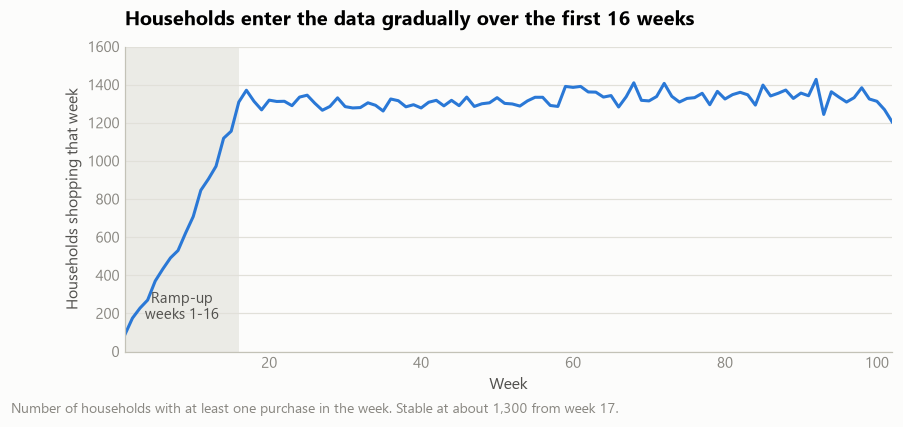

Active households in week 1: 88   in week 17: 1371
Week 102 has only 6 days


In [3]:
# Weeks in the data are cut like this: week 1 = days 1-5, then 7 days per week.
# As a formula: week = (day + 8) // 7. Check that it matches week_no exactly.
assert (tx.week_no == (tx.day + 8) // 7).all()
day_to_week = lambda d: (d + 8) // 7

weekly = tx.groupby("week_no").agg(active_households=("household_key", "nunique"),
                                   sales=("sales_value", "sum"))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(1, 16, color=C_GRID, alpha=0.6, lw=0)
ax.plot(weekly.index, weekly.active_households, color=C_BLUE)
ax.text(8.5, 150, "Ramp-up\nweeks 1-16", ha="center", va="bottom", fontsize=9.5, color=C_INK2)
ax.set_ylim(0, 1600)
ax.set_xlim(1, 102)
ax.set_xlabel("Week")
ax.set_ylabel("Households shopping that week")
ax.set_title("Households enter the data gradually over the first 16 weeks")
finish(fig, "01_ramp_up", "Number of households with at least one purchase in the week. Stable at about 1,300 from week 17.")

print("Active households in week 1:", weekly.active_households.iloc[0], "  in week 17:", weekly.active_households.loc[17])
print("Week 102 has only", tx[tx.week_no == 102].day.nunique(), "days")

**Reading the chart.** Only 88 households have a purchase in week 1; the count settles at about 1,300 only by week 17. Households did not suddenly start shopping. The data brings households into the record gradually over the first 16 weeks.

**What we do about it.**

- Outcomes use **week 17 onward** only.
- Week 102 has only 6 days and is dropped; the analysis runs to **week 101**.
- The main analysis keeps households that **already appear by week 16** (2,269 households). The other 231 have no early record, so their pre-campaign shopping habits cannot be assessed.

### 2.3 Campaign timeline

The 30 campaigns come in three types. According to dunnhumby's documentation, a TypeA campaign sends each household coupons picked from a large pool based on its purchase history; in TypeB and TypeC campaigns every participating household gets the same set of coupons.

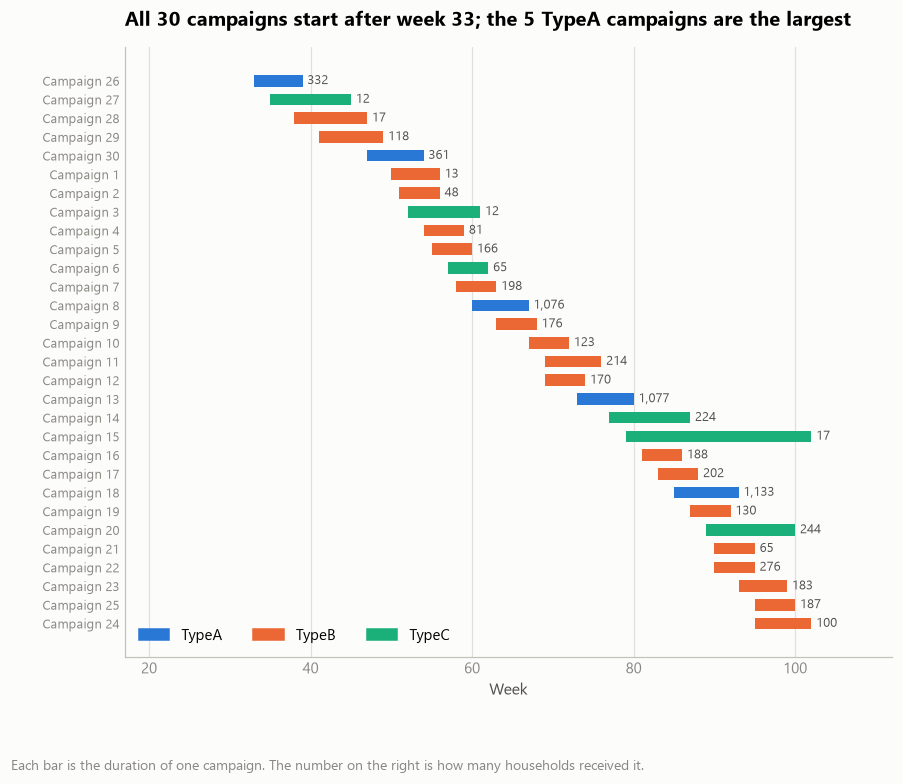

,campaigns,mailings,median_weeks,redemptions
description,,,,
TypeA,5,3979,7.000,1791
TypeB,19,2655,5.000,454
TypeC,6,574,10.000,73


In [4]:
# Convert campaign start/end days to weeks; attach household counts, products covered and redemptions
camp = cdesc.copy()
camp["start_week"] = day_to_week(camp.start_day)
camp["end_week"] = day_to_week(camp.end_day).clip(upper=101)
camp["n_weeks"] = camp.end_week - camp.start_week + 1
camp = camp.merge(ctab.groupby("campaign").household_key.nunique().rename("n_households"), on="campaign")
camp = camp.merge(coup.groupby("campaign").product_id.nunique().rename("n_products"), on="campaign", how="left")
camp = camp.merge(red.groupby("campaign").agg(n_redemptions=("coupon_upc", "size"),
                                              n_redeem_households=("household_key", "nunique")), on="campaign", how="left")
camp = camp.sort_values("start_day").reset_index(drop=True)
camp.to_csv(TAB / "campaigns.csv", index=False)

type_color = {"TypeA": C_BLUE, "TypeB": C_ORANGE, "TypeC": C_AQUA}
fig, ax = plt.subplots(figsize=(9, 7.2))
for i, r in camp.iterrows():
    ax.barh(i, r.n_weeks, left=r.start_week, height=0.62, color=type_color[r.description])
    ax.text(r.end_week + 1.6, i, f"{r.n_households:,}", va="center", fontsize=8.5, color=C_INK2)
ax.set_yticks(range(len(camp)))
ax.set_yticklabels([f"Campaign {c}" for c in camp.campaign], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(17, 112)
ax.grid(axis="x", color=C_GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Week")
ax.legend(handles=[mpl.patches.Patch(color=v, label=k) for k, v in type_color.items()], loc="lower left", ncol=3)
ax.set_title("All 30 campaigns start after week 33; the 5 TypeA campaigns are the largest")
finish(fig, "02_campaign_timeline", "Each bar is the duration of one campaign. The number on the right is how many households received it.")

camp.groupby("description").agg(campaigns=("campaign", "size"), mailings=("n_households", "sum"),
                                median_weeks=("n_weeks", "median"), redemptions=("n_redemptions", "sum"))

**Reading the chart.**

- The first campaign starts in **week 33**, so every household has at least 16 weeks (weeks 17–32) with no campaign at all.
- The 5 TypeA campaigns (26, 30, 8, 13, 18) are the largest; the last three reach about 1,100 households each. TypeA accounts for 55% of all mailings.
- Most campaigns last 5–8 weeks.

## 3. Building the household × week panel

The unit of the causal analysis is one household in one week. We collapse the 2.6 million transaction lines into three wide tables, with one row per household and one column per week (1–101):

- `SPEND`: dollars spent in the week. A week with no visit is 0.
- `TRIPS`: number of shopping trips in the week.
- `ACTIVE`: whether the household shopped that week (0/1).

Weeks with no visit are recorded as 0, not missing, because not coming in is itself part of the outcome.

In [5]:
tx = tx[tx.week_no <= 101]                      # drop the incomplete week 102
WEEKS = np.arange(1, 102)
ALL_HH = np.sort(tx.household_key.unique())


def to_wide(series):
    """Turn a (household, week) long series into a household x week table, filling gaps with 0."""
    return series.unstack("week_no").reindex(index=ALL_HH, columns=WEEKS).fillna(0.0)


g = tx.groupby(["household_key", "week_no"])
SPEND = to_wide(g.sales_value.sum())            # weekly spending
TRIPS = to_wide(g.basket_id.nunique())          # weekly trips
ACTIVE = (TRIPS > 0).astype(float)              # shopped that week?

# ---------- household table ----------
hh = pd.DataFrame(index=ALL_HH)
hh.index.name = "household_key"
hh["first_seen"] = tx.groupby("household_key").week_no.min()

# cohort = the week the household first received any campaign; 0 = never received one
first = (ctab.merge(camp[["campaign", "start_week", "start_day"]], on="campaign")
             .sort_values(["household_key", "start_day", "campaign"])
             .groupby("household_key").first())
hh["cohort"] = first.start_week.reindex(hh.index).fillna(0).astype(int)
hh["first_campaign"] = first.campaign.reindex(hh.index)
hh["first_type"] = first.description.reindex(hh.index)
hh["n_campaigns"] = ctab.groupby("household_key").campaign.nunique().reindex(hh.index).fillna(0).astype(int)
hh["ever_treated"] = (hh.n_campaigns > 0).astype(int)
hh["n_redemptions"] = red.groupby("household_key").size().reindex(hh.index).fillna(0).astype(int)
hh["ever_redeemed"] = (hh.n_redemptions > 0).astype(int)
hh["in_sample"] = (hh.first_seen <= 16).astype(int)        # already present before the ramp-up ends

print("All households:", len(hh), "  analysis sample:", hh.in_sample.sum())
print("In the analysis sample: ever received a campaign", hh[hh.in_sample == 1].ever_treated.sum(),
      "  never received one", (hh[hh.in_sample == 1].ever_treated == 0).sum())

# Everything below uses the analysis sample only
S = hh[hh.in_sample == 1].copy()
IDS = S.index
SPEND, TRIPS, ACTIVE = SPEND.loc[IDS], TRIPS.loc[IDS], ACTIVE.loc[IDS]
cohort = S.cohort

sizes = S[S.cohort > 0].groupby(["cohort", "first_campaign", "first_type"]).size().rename("households").reset_index()
sizes = sizes.sort_values("households", ascending=False).head(10)
sizes["first_campaign"] = sizes.first_campaign.astype(int)
sizes.rename(columns={"cohort": "first campaign week", "first_campaign": "first campaign", "first_type": "type"})

All households: 2500   analysis sample: 2269
In the analysis sample: ever received a campaign 1437   never received one 832


,first campaign week,first campaign,type,households
12,60,8,TypeA,420
0,33,26,TypeA,332
4,47,30,TypeA,113
21,85,18,TypeA,86
9,55,5,TypeB,84
17,73,13,TypeA,82
3,41,29,TypeB,72
11,58,7,TypeB,69
8,54,4,TypeB,43
13,63,9,TypeB,22


**A key idea: cohorts.** Households receive their first campaign at different times. We call the households whose first campaign starts in week g "cohort g". The five largest cohorts were all created by TypeA campaigns:

| Cohort | First campaign | Households |
|---|---|---|
| Week 33 | Campaign 26 | 332 |
| Week 47 | Campaign 30 | 113 |
| Week 60 | Campaign 8 | 420 |
| Week 73 | Campaign 13 | 82 |
| Week 85 | Campaign 18 | 86 |

Together these are **1,033 households**, the treatment group of the main analysis. Looking only at the *first* campaign guarantees that these households had never been touched by any campaign beforehand.

## 4. First impression and two traps

### 4.1 First impression: recipients spend several times more

The most direct approach is to compare two groups of households: those that ever received a campaign, and those that never did.

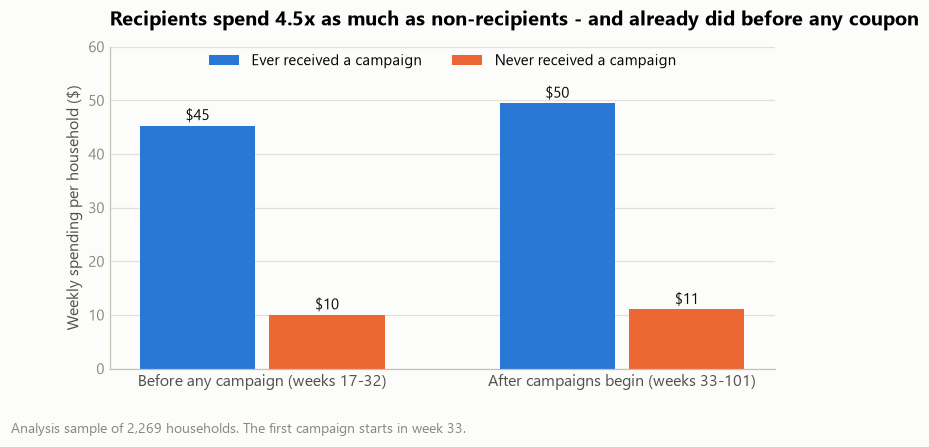

,Before any campaign (weeks 17-32),After campaigns begin (weeks 33-101)
Ever received a campaign,45.300,49.500
Never received a campaign,10.000,11.100


In [6]:
treated_ids = S.index[S.ever_treated == 1]
never_ids = S.index[S.ever_treated == 0]

naive = pd.DataFrame({
    "Before any campaign (weeks 17-32)": [SPEND.loc[treated_ids, 17:32].mean().mean(), SPEND.loc[never_ids, 17:32].mean().mean()],
    "After campaigns begin (weeks 33-101)": [SPEND.loc[treated_ids, 33:101].mean().mean(), SPEND.loc[never_ids, 33:101].mean().mean()],
}, index=["Ever received a campaign", "Never received a campaign"])
ratio_after = naive.iloc[0, 1] / naive.iloc[1, 1]
ratio_before = naive.iloc[0, 0] / naive.iloc[1, 0]

fig, ax = plt.subplots(figsize=(7.8, 3.8))
x = np.arange(2)
for j, (label, color) in enumerate([("Ever received a campaign", C_BLUE), ("Never received a campaign", C_ORANGE)]):
    vals = naive.loc[label].values
    bars = ax.bar(x + (j - 0.5) * 0.36, vals, width=0.32, color=color, label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f"${v:.0f}", ha="center", fontsize=10, color=C_INK)
ax.set_xticks(x)
ax.set_xticklabels(naive.columns, fontsize=10.5, color=C_INK2)
ax.set_ylabel("Weekly spending per household ($)")
ax.set_ylim(0, 60)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
ax.set_title(f"Recipients spend {ratio_after:.1f}x as much as non-recipients - and already did before any coupon", pad=26)
finish(fig, "03_naive_gap", "Analysis sample of 2,269 households. The first campaign starts in week 33.")

RESULTS["naive"] = dict(treated_before=naive.iloc[0, 0], never_before=naive.iloc[1, 0],
                        treated_after=naive.iloc[0, 1], never_after=naive.iloc[1, 1],
                        ratio_before=ratio_before, ratio_after=ratio_after,
                        n_treated=len(treated_ids), n_never=len(never_ids))
naive.round(1)

**Reading the chart.** Once campaigns are running, recipient households spend about \$50 a week and non-recipients about \$11, more than four times less. Credit that gap to the coupons and the conclusion is that coupons work spectacularly.

But look at the left pair of bars: before a single coupon had been sent, the two groups were already more than four times apart. **The gap was not caused by the coupons. It was caused by who the retailer chose.**

### 4.2 Trap one: the retailer picks households by how often they shop

How exactly does the retailer decide who gets a coupon? The data does not say, but it can be inferred.

Take campaign 8 (starts in week 60, 1,076 recipients). For every 9-week window before the campaign, we measure how well "the number of weeks the household shopped in this window" separates recipients from non-recipients. Separation is measured by the AUC: 0.5 is no better than a coin flip, 1 is perfect separation.

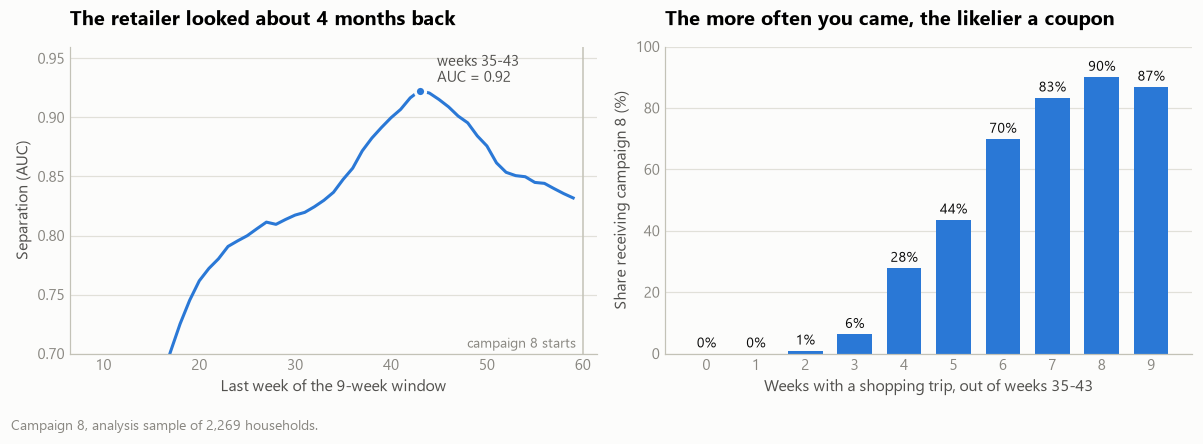

,campaign,start_week,recipients,best_window,auc,weeks_before_start
0,26,33,332,weeks 6-14,0.932,19
1,30,47,361,weeks 4-12,0.883,35
2,8,60,975,weeks 35-43,0.923,17
3,13,73,977,weeks 48-56,0.906,17
4,18,85,1030,weeks 61-69,0.915,16


In [7]:
members = {c: set(g.household_key) for c, g in ctab.groupby("campaign")}   # recipients of each campaign
TYPE_A = {26: 33, 30: 47, 8: 60, 13: 73, 18: 85}                           # TypeA campaign -> start week
WIN = 9                                                                    # window length in weeks

sel_rows, auc_curves = [], {}
for c, start in TYPE_A.items():
    got = SPEND.index.isin(members[c]).astype(int)
    ends = np.arange(WIN, start)                   # last week of the window; must be before the campaign
    aucs = np.array([roc_auc_score(got, ACTIVE.loc[:, e - WIN + 1:e].sum(axis=1)) for e in ends])
    auc_curves[c] = (ends, aucs)
    best = ends[aucs.argmax()]
    sel_rows.append(dict(campaign=c, start_week=start, recipients=int(got.sum()),
                         best_window=f"weeks {best - WIN + 1}-{best}", auc=aucs.max(),
                         weeks_before_start=start - best))
selection = pd.DataFrame(sel_rows)

# Campaign 8: within the best window, share of households that received it, by weeks shopped
ends8, aucs8 = auc_curves[8]
best8 = ends8[aucs8.argmax()]
act8 = ACTIVE.loc[:, best8 - WIN + 1:best8].sum(axis=1).astype(int)
got8 = pd.Series(SPEND.index.isin(members[8]).astype(int), index=SPEND.index)
p8 = got8.groupby(act8).agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(ends8, aucs8, color=C_BLUE)
ax.scatter([best8], [aucs8.max()], color=C_BLUE, s=45, zorder=3, edgecolor=C_SURF, linewidth=2)
ax.text(best8 + 1.8, aucs8.max() + 0.004, f"weeks {best8 - WIN + 1}-{best8}\nAUC = {aucs8.max():.2f}", fontsize=9.5, color=C_INK2, va="bottom")
ax.axvline(60, color=C_AXIS, lw=1)
ax.text(59.3, 0.705, "campaign 8 starts", ha="right", fontsize=9, color=C_MUTED)
ax.set_ylim(0.7, 0.96)
ax.set_xlabel("Last week of the 9-week window")
ax.set_ylabel("Separation (AUC)")
ax.set_title("The retailer looked about 4 months back")

ax = axes[1]
ax.bar(p8.index, p8["mean"] * 100, width=0.7, color=C_BLUE)
for k, v in p8["mean"].items():
    ax.text(k, v * 100 + 2, f"{v * 100:.0f}%", ha="center", fontsize=9, color=C_INK)
ax.set_xticks(p8.index)
ax.set_ylim(0, 100)
ax.set_xlabel(f"Weeks with a shopping trip, out of weeks {best8 - WIN + 1}-{best8}")
ax.set_ylabel("Share receiving campaign 8 (%)")
ax.set_title("The more often you came, the likelier a coupon")
fig.tight_layout()
finish(fig, "04_selection_rule", "Campaign 8, analysis sample of 2,269 households.")

RESULTS["selection"] = dict(table=selection.to_dict("records"),
                            campaign8=dict(window=[int(best8 - WIN + 1), int(best8)], auc=float(aucs8.max()),
                                           p_by_active_weeks={int(k): float(v) for k, v in p8["mean"].items()},
                                           n_by_active_weeks={int(k): int(v) for k, v in p8["size"].items()},
                                           auc_curve=dict(end_week=ends8.tolist(), auc=aucs8.tolist())))
selection

**Reading the chart.**

- **Left:** for campaign 8, shopping frequency in weeks 35–43 separates recipients from non-recipients best, with an AUC of 0.92. That window ends 17 weeks before the campaign starts. The retailer fixed its mailing list roughly four months ahead, based on the purchase records of that time.
- **Right:** of the households that did not shop once in those 9 weeks, none received the campaign. Of those that shopped in 7 or more of the 9 weeks, close to nine in ten did.
- **Table:** the other TypeA campaigns follow the same pattern, with AUCs around 0.9. The window usually ends 16–19 weeks before the campaign. Campaign 30 is the exception; it reuses an early window close to the one behind campaign 26.

**Two things follow.**

1. The selection rule can be reconstructed from the data we have. That is good news: if the controls were just as active in the same window, the two groups are comparable.
2. Selection depends on being unusually active in one particular period. That creates the second trap.

### 4.3 Trap two: households are picked at a high point (regression to the mean)

A household's shopping goes up and down from month to month. The retailer picks households that were especially active in weeks 35–43, and some of them simply happened to buy a lot in that period. Afterwards their spending drifts back down, coupon or no coupon.

Here is the spending path of the week-60 cohort (420 households) around the time they were selected:

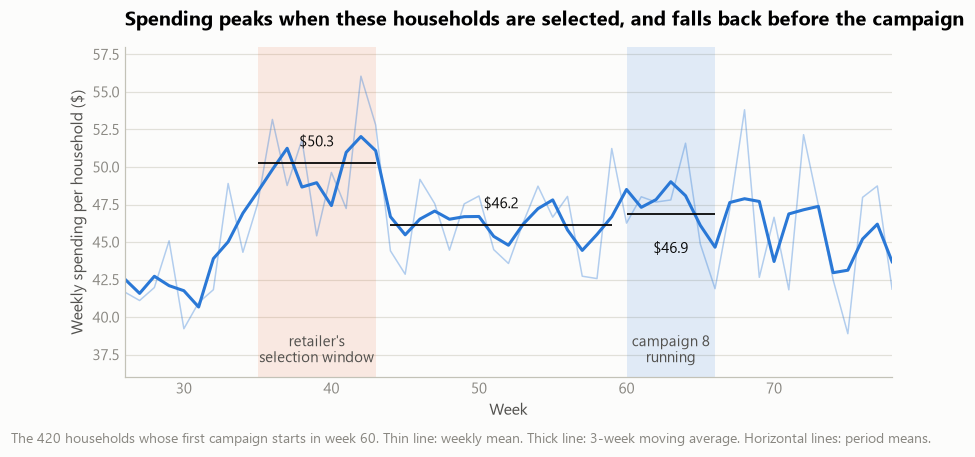

Selection window $50.3 -> before the campaign $46.2 (-8.2%) -> during the campaign $46.9


In [8]:
g60 = cohort.index[cohort == 60]
path = SPEND.loc[g60].mean()
smooth = path.rolling(3, center=True).mean()              # 3-week moving average to remove weekly jitter

lvl_sel = SPEND.loc[g60, 35:43].mean().mean()             # the selection window
lvl_gap = SPEND.loc[g60, 44:59].mean().mean()             # after selection, before the campaign
lvl_camp = SPEND.loc[g60, 60:66].mean().mean()            # during the campaign

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.axvspan(35, 43, color=C_ORANGE, alpha=0.13, lw=0)
ax.axvspan(60, 66, color=C_BLUE, alpha=0.13, lw=0)
ax.plot(path.loc[26:78].index, path.loc[26:78], color=C_BLUE, lw=1, alpha=0.35)
ax.plot(smooth.loc[26:78].index, smooth.loc[26:78], color=C_BLUE)
ax.text(39, 37.0, "retailer's\nselection window", ha="center", fontsize=9.5, color=C_INK2)
ax.text(63, 37.0, "campaign 8\nrunning", ha="center", fontsize=9.5, color=C_INK2)
for (a, b, v, dy) in [(35, 43, lvl_sel, 1.1), (44, 59, lvl_gap, 1.1), (60, 66, lvl_camp, -2.6)]:
    ax.hlines(v, a, b, color=C_INK, lw=1.2)
    ax.text((a + b) / 2, v + dy, f"${v:.1f}", ha="center", fontsize=10, color=C_INK)
ax.set_ylim(36, 58)
ax.set_xlim(26, 78)
ax.set_xlabel("Week")
ax.set_ylabel("Weekly spending per household ($)")
ax.set_title("Spending peaks when these households are selected, and falls back before the campaign")
finish(fig, "05_mean_reversion", "The 420 households whose first campaign starts in week 60. Thin line: weekly mean. Thick line: 3-week moving average. Horizontal lines: period means.")

RESULTS["mean_reversion"] = dict(n=len(g60), selection_window=float(lvl_sel), between=float(lvl_gap),
                                 campaign=float(lvl_camp), drop_pct=float(100 * (lvl_gap / lvl_sel - 1)),
                                 weeks=path.loc[26:78].index.tolist(), weekly=path.loc[26:78].tolist(),
                                 smooth=smooth.loc[26:78].tolist())
print(f"Selection window ${lvl_sel:.1f} -> before the campaign ${lvl_gap:.1f} ({100 * (lvl_gap / lvl_sel - 1):+.1f}%) -> during the campaign ${lvl_camp:.1f}")

**Reading the chart.** These households spent about \$50 a week during the retailer's selection window. Before the campaign began, with no coupon received yet, their spending had already dropped by about 8%.

This is **regression to the mean**: a group picked because it stood out in one period will drift back toward its usual level afterwards.

**Why it is a trap.** If we take the households that were not selected as the comparison group and do a before/after comparison, recipients' spending appears to fall relative to them, and we would conclude that coupons make people spend less. Section 7 shows that a plain, unadjusted difference-in-differences gives exactly this result.

**Summary: two traps, pointing in opposite directions.**

| Approach | What it concludes | What is wrong |
|---|---|---|
| Compare recipients with non-recipients | Coupons multiply spending several times | Recipients bought more to begin with (selection bias) |
| Before/after, with non-recipients as the reference | Coupons reduce spending | Recipients were picked at a high point (regression to the mean) |

### 4.4 The same gap, one stratum at a time (a Simpson's-paradox view)

The course's first warning about observational data is Simpson's paradox: a comparison made on the whole population can look very different once you compare like with like. Here the lurking variable is how active the household was before the campaign.

To look at this we build one table that the rest of the notebook reuses. It has **one row per household per cohort**: for each of the five first-campaign cohorts, the households first reached in that week (T = 1) and the households not yet reached 12 weeks later (T = 0), with their pre-campaign shopping measures and their spending in three windows:

| Column | Meaning |
|---|---|
| `T` | 1 if the household's first campaign starts in this cohort's week |
| `spend_b*`, `trips_b*`, `active_b*` | pre-campaign shopping history, in four periods ending 9 weeks before the campaign |
| `y_base` | mean weekly spending in the baseline window (weeks −16 to −9) |
| `y_check` | mean weekly spending in the check window (weeks −8 to −1), before any coupon |
| `y_during` | mean weekly spending during the campaign (weeks 0 to 6) |

7,159 rows: 1,033 treated, 6,126 control rows (2,194 distinct households; a control household can serve several cohorts)


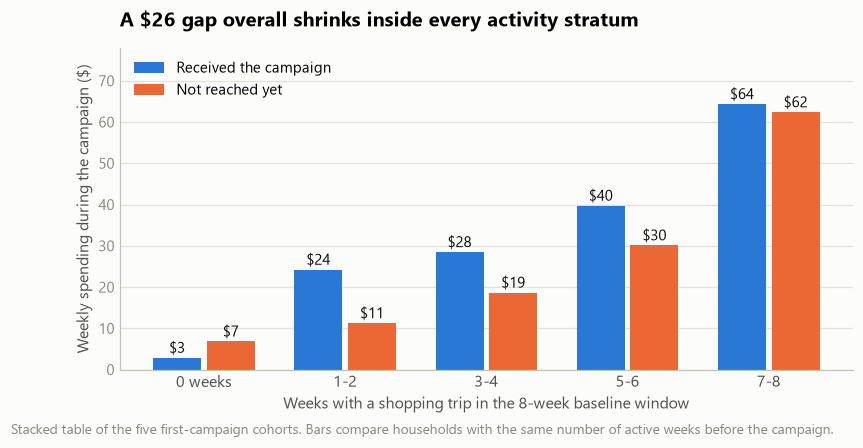

Gap in the whole table: $25.6 a week.  Adjustment formula over 50 cells: $3.2 a week.


,n_control,n_treated,spend_control,spend_treated,gap
activity,,,,,
0 weeks,1259,6,6.800,2.900,-4.000
1-2,1852,83,11.300,24.200,13.000
3-4,1343,191,18.700,28.500,9.800
5-6,916,312,30.100,39.700,9.600
7-8,756,441,62.400,64.300,2.000


In [9]:
COHORTS = [33, 47, 60, 73, 85]     # the five first-campaign cohorts (each created by a TypeA campaign)
FOLLOW = 12                         # controls must still be untreated 12 weeks after the cohort's campaign starts


def stack_cohorts():
    """One row per household per cohort: treatment flag, pre-campaign history, outcomes."""
    rows = []
    for g in COHORTS:
        treated = cohort == g
        control = (cohort == 0) | (cohort > g + FOLLOW)
        ids = IDS[(treated | control).values]
        c = g - 9                                     # last week of history used for adjustment
        blocks = [(c - 7, c), (c - 15, c - 8), (c - 23, c - 16)] + ([(1, c - 24)] if c - 24 >= 1 else [])
        d = pd.DataFrame({"household_key": ids, "cohort": g, "T": treated.loc[ids].astype(int).values})
        for j in range(4):
            if j < len(blocks):
                a, b = max(blocks[j][0], 1), blocks[j][1]
                d[f"spend_b{j}"] = SPEND.loc[ids, a:b].mean(axis=1).values
                d[f"trips_b{j}"] = TRIPS.loc[ids, a:b].mean(axis=1).values
                d[f"active_b{j}"] = ACTIVE.loc[ids, a:b].mean(axis=1).values
            else:                                     # the week-33 cohort has only three periods of history
                d[f"spend_b{j}"] = d[f"trips_b{j}"] = d[f"active_b{j}"] = 0.0
        d["y_base"] = SPEND.loc[ids, g - 16:g - 9].mean(axis=1).values
        d["y_check"] = SPEND.loc[ids, g - 8:g - 1].mean(axis=1).values
        d["y_during"] = SPEND.loc[ids, g:g + 6].mean(axis=1).values
        d["visit_during"] = ACTIVE.loc[ids, g:g + 6].mean(axis=1).values
        d["trips_base"] = TRIPS.loc[ids, g - 16:g - 9].mean(axis=1).values
        d["active_base_weeks"] = ACTIVE.loc[ids, g - 16:g - 9].sum(axis=1).values
        rows.append(d)
    return pd.concat(rows, ignore_index=True)


STK = stack_cohorts()
XCOLS = [f"{m}_b{j}" for j in range(4) for m in ("spend", "trips", "active")]      # the 12 pre-campaign measures
print(f"{len(STK):,} rows: {STK['T'].sum():,} treated, {(STK['T'] == 0).sum():,} control rows "
      f"({STK.household_key.nunique():,} distinct households; a control household can serve several cohorts)")

# Compare recipients and non-recipients inside strata of pre-campaign activity
STK["activity"] = pd.cut(STK.active_base_weeks, [-1, 0, 2, 4, 6, 8], labels=["0 weeks", "1-2", "3-4", "5-6", "7-8"])
strata = STK.groupby(["activity", "T"], observed=True).y_during.agg(["size", "mean"]).unstack()
strata.columns = ["n_control", "n_treated", "spend_control", "spend_treated"]
strata["gap"] = strata.spend_treated - strata.spend_control
overall_gap = STK[STK["T"] == 1].y_during.mean() - STK[STK["T"] == 0].y_during.mean()

# Adjustment formula by hand, for the treated (Week 6): E[Y | T=1] - sum_z E[Y | T=0, z] P(z | T=1),
# with z = activity stratum x decile of baseline spending (50 cells)
STK["z"] = STK.activity.astype(str) + " / " + pd.qcut(STK.y_base.rank(method="first"), 10, labels=False).astype(str)
cell = STK.groupby(["z", "T"]).y_during.agg(["mean", "size"]).unstack()
both = cell[("size", 0)].notna() & cell[("size", 1)].notna()
w_z = cell[("size", 1)][both] / cell[("size", 1)][both].sum()
adj_by_hand = float((w_z * (cell[("mean", 1)][both] - cell[("mean", 0)][both])).sum())

fig, ax = plt.subplots(figsize=(8.6, 3.8))
x = np.arange(len(strata))
for j, (col, color, lab) in enumerate([("spend_treated", C_BLUE, "Received the campaign"), ("spend_control", C_ORANGE, "Not reached yet")]):
    bars = ax.bar(x + (j - 0.5) * 0.38, strata[col], width=0.34, color=color, label=lab)
    for b_, v in zip(bars, strata[col]):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 1.2, f"${v:.0f}", ha="center", fontsize=9.5, color=C_INK)
ax.set_xticks(x)
ax.set_xticklabels(strata.index.astype(str), fontsize=10.5, color=C_INK2)
ax.set_xlabel("Weeks with a shopping trip in the 8-week baseline window")
ax.set_ylabel("Weekly spending during the campaign ($)")
ax.set_ylim(0, 78)
ax.legend(loc="upper left")
ax.set_title(f"A ${overall_gap:.0f} gap overall shrinks inside every activity stratum")
finish(fig, "03b_strata", "Stacked table of the five first-campaign cohorts. Bars compare households with the same number of active weeks before the campaign.")

RESULTS["strata"] = dict(overall_gap=float(overall_gap), adjustment_formula_50_cells=adj_by_hand,
                         table=strata.reset_index().astype({"activity": str}).to_dict("records"))
print(f"Gap in the whole table: ${overall_gap:.1f} a week.  Adjustment formula over 50 cells: ${adj_by_hand:.1f} a week.")
strata.round(1)

**Reading the chart.**

- Over the whole table, recipients spend about \$26 a week more than households not reached yet.
- Inside each activity stratum the gap is much smaller, between −\$4 and +\$13. In the most active stratum, which holds the largest number of recipients, it is \$2.
- Plugging 50 cells (activity stratum × decile of baseline spending) into the **adjustment formula** from Week 6, $E[Y \mid T{=}1] - \sum_z E[Y \mid T{=}0, z]\,P(z \mid T{=}1)$, leaves about \$3 a week.

So most of the raw gap is the lurking variable, not the coupon. But stratifying by hand is coarse: the cells are still wide enough to hide differences between recipients and non-recipients. To do it properly we need to say exactly what must be adjusted for, and why. That is what a causal graph is for.

## 5. The causal graph: what must be adjusted for, and what must not

This section puts the problem in the course's framework (Weeks 4–6): draw the structural causal model as a directed acyclic graph (DAG), read off which paths between treatment and outcome are causal and which are spurious, and use the backdoor criterion to decide the adjustment set.

### 5.1 The graph

| Node | What it is | Observed? |
|---|---|---|
| **H** | Pre-campaign shopping history (frequency, spending) | Yes |
| **T** | The household receives a coupon campaign | Yes |
| **R** | The household redeems a coupon | Yes |
| **Y** | Spending during the campaign | Yes |
| **U** | Household traits: income, family size, tastes, distance to the store | No |
| **V** | How much the household happens to shop in the campaign weeks | No |

The arrows, and the reason for each:

- **U → H, U → Y.** Stable traits drive how much a household shops, before and during the campaign.
- **H → T.** The retailer selects on past shopping (Section 4.2).
- **H → Y.** Habits persist.
- **T → R → Y.** A coupon can only be redeemed if it was received, and redeeming may change spending.
- **T → Y.** Receiving a mailing may bring someone in even if no coupon is used (a reminder effect).
- **V → R, V → Y.** A household that shops more in those weeks has more chances to redeem, and spends more.

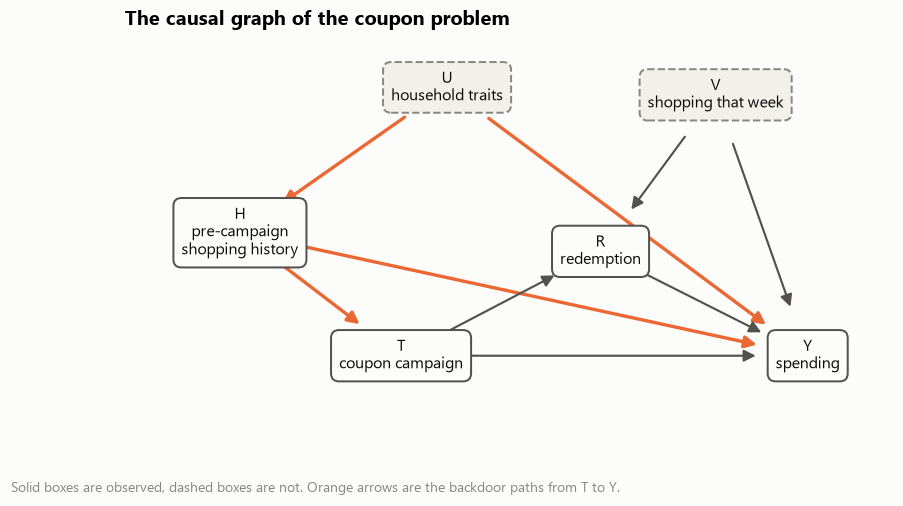

In [10]:
def draw_dag(nodes, edges, title, name, note=None, highlight=(), figsize=(9, 4.4)):
    """Draw a small DAG. nodes: {key: (x, y, label, observed)}; edges: [(from, to)]; highlight: edges drawn in orange."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 5)
    ax.axis("off")
    for a, b in edges:
        xa, ya = nodes[a][:2]
        xb, yb = nodes[b][:2]
        hot = (a, b) in highlight
        ax.annotate("", xy=(xb, yb), xytext=(xa, ya),
                    arrowprops=dict(arrowstyle="-|>", color=C_ORANGE if hot else C_INK2, lw=2.2 if hot else 1.4,
                                    shrinkA=34, shrinkB=34, mutation_scale=16))
    for k, (x, y, label, observed) in nodes.items():
        ax.text(x, y, label, ha="center", va="center", fontsize=10.5, color=C_INK,
                bbox=dict(boxstyle="round,pad=0.5", fc=C_SURF if observed else "#f1f0ea", ec=C_INK2 if observed else C_MUTED,
                          lw=1.3, ls="-" if observed else "--"))
    ax.set_title(title)
    finish(fig, name, note)


NODES = {                                              # positions chosen so that no arrow passes through a box
    "U": (4.2, 4.45, "U\nhousehold traits", False),
    "H": (1.5, 2.5, "H\npre-campaign\nshopping history", True),
    "T": (3.6, 0.85, "T\ncoupon campaign", True),
    "R": (6.2, 2.25, "R\nredemption", True),
    "V": (7.7, 4.35, "V\nshopping that week", False),
    "Y": (8.9, 0.85, "Y\nspending", True),
}
EDGES = [("U", "H"), ("U", "Y"), ("H", "T"), ("H", "Y"), ("T", "R"), ("R", "Y"), ("T", "Y"), ("V", "R"), ("V", "Y")]
draw_dag(NODES, EDGES, "The causal graph of the coupon problem", "04b_dag",
         "Solid boxes are observed, dashed boxes are not. Orange arrows are the backdoor paths from T to Y.",
         highlight=[("H", "T"), ("H", "Y"), ("U", "H"), ("U", "Y")])

### 5.2 Reading the graph: chains, forks, colliders and the backdoor criterion

The three building blocks from Week 4 all appear in this one graph:

| Block | Where | What it means here |
|---|---|---|
| **Fork** | T ← H → Y | Past shopping is a common cause of getting a coupon and of spending. This is the confounding that makes the raw gap \$26. |
| **Chain** | T → R → Y | Redemption is a mediator: part of whatever effect the campaign has flows through it. |
| **Collider** | T → R ← V | Redemption is caused both by receiving a coupon and by how much the household shops that week. |

**Paths from T to Y.**

| Path | Type | Status |
|---|---|---|
| T → Y | causal (reminder effect) | leave open |
| T → R → Y | causal (through redemption) | leave open |
| T ← H → Y | backdoor | must be blocked |
| T ← H ← U → Y | backdoor | must be blocked |

**Backdoor criterion.** A set Z identifies the effect of T on Y if it blocks every backdoor path and contains no descendant of T. Here Z = {H} works: H sits on both backdoor paths (as the middle of a fork on the first, and of a chain on the second), and it is measured before the campaign, so it cannot be a descendant of T. We never need to observe U.

**What not to condition on.** R is a descendant of T, and it is a collider. Splitting recipients into "redeemed" and "did not redeem" conditions on R, which opens the path T → R ← V → Y: redeemers are households that shopped more in those weeks. Section 11.2 shows what this mistake looks like in the data.

**The estimand.** We want the effect of the campaign on the households that received it, the **ATT** (Week 7; the course also calls it the effect of treatment on the treated, ETT, in Week 6):

$$\text{ATT} = E[Y_{1} - Y_{0} \mid T = 1] = E[Y \mid T{=}1] \;-\; \sum_h E[Y \mid T{=}0,\, H{=}h]\; P(h \mid T{=}1)$$

The second term is the counterfactual: what recipients would have spent without the campaign, built from non-recipients with the same history. We target the ATT and not the population-wide ATE because the retailer only ever sends coupons to active households. For the many inactive households there is almost nobody with a coupon to learn from (no overlap), so "what if everyone got coupons" cannot be answered from this data.

**Assumptions, in the course's words.**

1. **Conditional exchangeability** (the counterfactual version of the backdoor criterion): among households with the same pre-campaign history, who got the campaign is as good as random.
2. **Overlap (positivity):** for the kind of household that received a campaign, some similar households did not.
3. **Consistency:** a household's observed spending is its potential outcome under the treatment it actually received.

**Why not the front door or an instrument?** The front-door criterion would need all of the campaign's effect to pass through redemption, and it fails here because of the direct T → Y arrow; it also cannot be computed, since no household redeems without receiving a campaign. An instrumental-variable reading of the problem is discussed in Section 14.

### 5.3 Can the graph be tested?

A graph is only useful if it could be wrong. Section 4.2 suggested a very simple selection story: the retailer looks at how often a household shopped in one 9-week window and nothing else. Written as a graph for the week-60 cohort:

> Early activity → Window activity → Recent activity, with **only Window activity → Coupon**

That graph has a testable implication (a d-separation): **given Window activity, Coupon is independent of Early and Recent activity.** We test it two ways: with a likelihood-ratio test in a logistic regression, and with DoWhy's graph falsification test, the tool shown in class in Weeks 5 and 6.

In [11]:
import logging
import networkx as nx
import statsmodels.api as sm
from scipy import stats
from dowhy.gcm.falsify import falsify_graph

logging.getLogger("dowhy").setLevel(logging.ERROR)

# Households not yet treated when the week-60 campaign starts; Coupon = 1 if campaign 8 is their first
pool60 = cohort.index[(cohort == 0) | (cohort >= 60)]
G60 = pd.DataFrame({
    "Early": ACTIVE.loc[pool60, 17:34].mean(axis=1),       # share of weeks 17-34 with a trip
    "Window": ACTIVE.loc[pool60, 35:43].mean(axis=1),      # the retailer's selection window
    "Recent": ACTIVE.loc[pool60, 44:51].mean(axis=1),      # after the window, before our 8-week check window
    "RecentSpend": np.log1p(SPEND.loc[pool60, 44:51].mean(axis=1)),
    "Coupon": (cohort.loc[pool60] == 60).astype(float),
    "Spend": SPEND.loc[pool60, 60:66].mean(axis=1),
}).reset_index(drop=True)

# (a) Likelihood-ratio test: once Window activity is in the model, do the other periods still predict the coupon?
small = sm.Logit(G60.Coupon, sm.add_constant(G60[["Window"]])).fit(disp=0)
big = sm.Logit(G60.Coupon, sm.add_constant(G60[["Window", "Early", "Recent", "RecentSpend"]])).fit(disp=0)
lr = 2 * (big.llf - small.llf)
p_lr = float(stats.chi2.sf(lr, 3))
print(f"Logistic regression of Coupon on Window activity: pseudo-R2 = {small.prsquared:.3f}")
print(f"Adding Early, Recent and RecentSpend:              pseudo-R2 = {big.prsquared:.3f}")
print(f"Likelihood-ratio test that they add nothing: chi2 = {lr:.1f}, df = 3, p = {p_lr:.4f}\n")
print(big.summary2().tables[1].round(3).to_string())

# (b) DoWhy: does the data contradict the conditional independences the simple graph implies?
simple_graph = nx.DiGraph([("Early", "Window"), ("Window", "Recent"), ("Early", "Recent"), ("Window", "Coupon"),
                           ("Early", "Spend"), ("Window", "Spend"), ("Recent", "Spend"), ("Coupon", "Spend")])
np.random.seed(SEED)
falsification = falsify_graph(simple_graph, G60[["Early", "Window", "Recent", "Coupon", "Spend"]], n_permutations=20,
                              show_progress_bar=False, plot_histogram=False, suggestions=False)
print("\nDoWhy graph falsification of the simple graph:")
print(falsification)

RESULTS["graph_test"] = dict(pseudo_r2_window=float(small.prsquared), pseudo_r2_all=float(big.prsquared),
                             lr_chi2=float(lr), lr_p=p_lr, dowhy_summary=str(falsification),
                             dowhy_falsified=bool(getattr(falsification, "falsified", False)))

Logistic regression of Coupon on Window activity: pseudo-R2 = 0.462
Adding Early, Recent and RecentSpend:              pseudo-R2 = 0.480
Likelihood-ratio test that they add nothing: chi2 = 31.6, df = 3, p = 0.0000

             Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
const       -5.662     0.311 -18.210  0.000  -6.271  -5.053
Window       6.812     0.517  13.185  0.000   5.799   7.825
Early        0.194     0.400   0.484  0.629  -0.591   0.978
Recent      -1.358     0.504  -2.691  0.007  -2.346  -0.369
RecentSpend  0.619     0.116   5.331  0.000   0.391   0.846



DoWhy graph falsification of the simple graph:
+-------------------------------------------------------------------------------------------------------+
|                                         Falsification Summary                                         |
+-------------------------------------------------------------------------------------------------------+
| The given DAG is informative because 0 / 20 of the permutations lie in the Markov                     |
| equivalence class of the given DAG (p-value: 0.00).                                                   |
| The given DAG violates 2/3 LMCs and is better than 90.0% of the permuted DAGs (p-value: 0.10).        |
| Based on the provided significance level (0.05) and because the DAG is informative,                   |
| we reject the DAG.                                                                                    |
+-------------------------------------------------------------------------------------------------------

In [12]:
# (c) A harder question for our own design: does activity in the 8-week check window still predict who gets
#     the campaign, after the 12 measures we adjust for? If the retailer used information that recent, the answer is yes.
cohort_dummies = pd.get_dummies(STK.cohort, prefix="cohort", drop_first=True).astype(float)
X_adj = sm.add_constant(pd.concat([STK[XCOLS], cohort_dummies], axis=1))
m_adj = sm.Logit(STK["T"], X_adj).fit(disp=0)
X_plus = X_adj.copy()
X_plus["check_spend"] = np.log1p(STK.y_check)
m_plus = sm.Logit(STK["T"], X_plus).fit(disp=0)
lr_check = 2 * (m_plus.llf - m_adj.llf)
p_check = float(stats.chi2.sf(lr_check, 1))
print(f"Selection model with the 12 adjustment measures: pseudo-R2 = {m_adj.prsquared:.3f}")
print(f"Adding spending in the check window:             pseudo-R2 = {m_plus.prsquared:.3f}")
print(f"Likelihood-ratio test: chi2 = {lr_check:.1f}, df = 1, p = {p_check:.4f}; coefficient {m_plus.params['check_spend']:+.2f}")
RESULTS["graph_test"].update(check_pseudo_r2=float(m_adj.prsquared), check_pseudo_r2_plus=float(m_plus.prsquared),
                             check_lr=float(lr_check), check_p=p_check, check_coef=float(m_plus.params["check_spend"]))

Selection model with the 12 adjustment measures: pseudo-R2 = 0.439
Adding spending in the check window:             pseudo-R2 = 0.445
Likelihood-ratio test: chi2 = 35.3, df = 1, p = 0.0000; coefficient +0.31


**Reading the results.**

- **The one-window story is too simple.** Window activity alone explains most of who gets the campaign, and adding the other periods raises the pseudo-R² only slightly. But the likelihood-ratio test rejects "the other periods add nothing", and DoWhy's test reaches the same verdict: the data violate conditional independences that the simple graph implies. In the words of the Week 5 slides, the hypothesized DAG is incomplete and the causal assumptions need revisiting.
- **The revision.** We let the *whole* pre-campaign history point into T, not one window. That is the graph of Section 5.1, where H stands for all pre-campaign shopping measures, and it is why the analysis adjusts for twelve measures over four periods, not one. The price is that this graph no longer makes a testable prediction about selection, so it cannot be falsified the same way. We need another check.
- **That other check is the 8-week check window** (Section 6.2). It asks a different question: after adjustment, do the two groups behave alike in weeks the adjustment never saw?
- **An honest caveat about that window.** Cell (c) shows that spending in the check window still predicts who gets the campaign, even after the twelve measures. The gain in pseudo-R² is tiny, but the test is clearly significant, and the coefficient is positive: recipients were spending a little more in those weeks than their history predicts. So the retailer's information reaches closer to the campaign than our adjustment does, and a small part of the confounding is left in. Its direction is known: it pushes our estimates *up*. Section 12 reruns the main estimate with no check window at all, adjusting on every week before the campaign.

## 6. Study design: comparable controls and a check window

Section 5 said *what* has to be adjusted for: the household's pre-campaign shopping history. This section says *how* the comparison is built.

### 6.1 The idea

What we want to know is: **for the same household, how much would it have spent in these weeks had it not received the coupons?** That "what if" can never be observed. We can only stand in other households for it, and how good the stand-ins are decides how credible the conclusion is.

Section 4 tells us what a good stand-in looks like: **a household that was just as active as the recipients in the period the retailer looked at, but had not been chosen yet.** Then the two groups share the same usual level and the same high point at selection, so their natural drift afterwards should be the same too.

The design, for each cohort (households whose first campaign starts in week $g$):

| Element | Definition |
|---|---|
| **Treatment group** | Households whose first campaign starts in week $g$ |
| **Control group** | Households that have not received any campaign by week $g+12$ |
| **Information used for adjustment** | Purchase records from week 1 to week $g-9$, split into 4 periods; for each period: mean weekly spending, mean weekly trips, share of weeks with a trip |
| **Baseline window** | Weeks $g-16$ to $g-9$ (8 weeks) |
| **Check window** | Weeks $g-8$ to $g-1$ (8 weeks). **Not used for adjustment** |
| **Campaign window** | Weeks $g$ to $g+6$ |
| **After-campaign window** | Weeks $g+7$ to $g+12$ |

The effect compares the *change from baseline* in the two groups (a difference-in-differences). In the language of Section 5 this is backdoor adjustment on pre-campaign history, with each household's own baseline level subtracted first so that stable differences between households drop out:

$$\text{effect}_k = \underbrace{\big(\bar Y^{\text{treated}}_{g+k} - \bar Y^{\text{treated}}_{\text{baseline}}\big)}_{\text{change in the treatment group}} - \underbrace{\big(\bar Y^{\text{control}}_{g+k} - \bar Y^{\text{control}}_{\text{baseline}}\big)}_{\text{change in the adjusted control group}}$$

where $k$ is the week relative to the campaign start. The five cohorts are estimated separately and then averaged, weighted by their number of households.

### 6.2 The check window: the most important part of the design

Comparing changes rests on **parallel trends**: without the coupons, spending in the two groups would have changed in the same way. It is the conditional exchangeability of Section 5.2, stated for changes. This cannot be verified directly, because the treatment group without coupons does not exist.

Our answer is to **leave the last 8 weeks before the campaign unused**. The adjustment only uses data up to week $g-9$; then we look at how the two groups move in weeks $g-8$ to $g-1$. Nobody has received a coupon in those 8 weeks, so the difference between the groups should be zero. If it is not, the controls are not comparable and the later results cannot be trusted.

The retailer's selection window ends about 16 weeks before the campaign starts, so it falls entirely inside the period we use for adjustment. Holding out the last 8 weeks does not lose any of the selection information.

### 6.3 Four estimators

There are several ways to make the controls comparable. We implement four and compare them side by side:

| Name | What it does | What it assumes |
|---|---|---|
| `did` plain DiD | No adjustment; compare directly | Unconditional parallel trends |
| `ra` regression adjustment | Fit "pre-campaign records → later change in spending" on the controls, then predict what the treated would have done without coupons | That relationship is the same in both groups and roughly linear |
| `eb` entropy balancing | Give each control household a weight so that the weighted controls match the treated on the means of 12 pre-campaign measures | Households with the same pre-campaign records have the same trend afterwards |
| `dr` doubly robust | Entropy balancing, then regression adjustment | Either of the two assumptions above is enough |

**The main estimator is `dr`.** Confidence intervals come from a household-level bootstrap: resample households with replacement 1,000 times, redo the weighting and regression each time, and take the 2.5th and 97.5th percentiles of the estimates.

In [13]:
HOLDOUT = 8      # check window: the last 8 pre-campaign weeks are not used for adjustment
BASE_LEN = 8     # length of the baseline window
PRE_SHOW = 16    # event-study plots start 16 weeks before the campaign
H = 12           # follow households for 12 weeks after the campaign starts


def features(cutoff):
    """Build 12 pre-campaign measures per household from the records of weeks 1..cutoff.

    Four periods: the latest 8 weeks, the 8 before that, the 8 before that, and everything earlier.
    Three measures per period: mean weekly spending, mean weekly trips, share of weeks with a trip.
    """
    blocks = [(cutoff - 7, cutoff), (cutoff - 15, cutoff - 8), (cutoff - 23, cutoff - 16)]
    if cutoff - 24 >= 1:
        blocks.append((1, cutoff - 24))
    out = {}
    for a, b in blocks:
        a = max(a, 1)
        out[f"spend_w{a}-{b}"] = SPEND.loc[:, a:b].mean(axis=1)
        out[f"trips_w{a}-{b}"] = TRIPS.loc[:, a:b].mean(axis=1)
        out[f"active_w{a}-{b}"] = ACTIVE.loc[:, a:b].mean(axis=1)
    return pd.DataFrame(out)


def entropy_balance(Xc, target, q, ridge=0.02):
    """Entropy balancing: find control weights whose weighted mean is as close as possible to `target`.

    The weights have the form w_i ∝ q_i · exp(x_i'λ); λ minimizes a convex function.
    q are the starting weights (in the bootstrap, how many times each household was drawn).
    ridge > 0 allows a tiny remaining imbalance in exchange for more stable weights: when the
    treated mean sits at the edge of the range of the controls, exact balance would put
    almost all the weight on one or two households.
    """
    Z = Xc - target

    def dual(lam):
        s = Z @ lam
        m = s.max()
        ew = q * np.exp(s - m)
        tot = ew.sum()
        return m + np.log(tot) + 0.5 * ridge * lam @ lam, (ew @ Z) / tot + ridge * lam

    r = minimize(dual, np.zeros(Z.shape[1]), jac=True, method="L-BFGS-B", options=dict(maxiter=300))
    s = Z @ r.x
    wts = q * np.exp(s - s.max())
    return wts / wts.sum()


def prepare(Y, cohort, gs, treated_subset=None, control_subset=None, H=H):
    """Assemble the sample for each cohort g: treated, controls, adjustment measures, outcome.

    Y is one wide table (same outcome for every cohort) or a {g: wide table} dictionary.
    """
    setups = []
    coh = cohort.reindex(IDS).values
    for g in gs:
        treated = coh == g
        control = (coh == 0) | (coh > g + H)          # no campaign received by week g+H
        if treated_subset is not None:
            treated &= IDS.isin(treated_subset)
        if control_subset is not None:
            control &= IDS.isin(control_subset)
        keep = treated | control
        Yg = Y[g] if isinstance(Y, dict) else Y
        X = features(g - HOLDOUT - 1)
        setups.append(dict(g=g, ids=IDS[keep], X=X.values[keep], names=list(X.columns),
                           d=treated[keep].astype(int), Y=Yg.loc[IDS[keep]].values))
    return setups


def one_cohort(s, sw, ks, method):
    """Estimate the effect in each event week k for one cohort. sw = bootstrap weight per household."""
    g, X, d, Y = s["g"], s["X"], s["d"], s["Y"]
    pos = sw > 0
    X, d, Y, sw = X[pos], d[pos], Y[pos], sw[pos]
    t, c = d == 1, d == 0

    # Each household's change relative to its baseline window (weeks g-16..g-9). Column 0 of Y is week 1.
    base = Y[:, g - HOLDOUT - BASE_LEN - 1: g - HOLDOUT - 1].mean(axis=1)
    dY = Y[:, g + ks - 1] - base[:, None]

    wt = sw[t] / sw[t].sum()                                      # treated weights
    Xs = (X - X[c].mean(0)) / (X[c].std(0) + 1e-9)                # standardize the measures

    ess = np.nan
    if method in ("eb", "dr"):
        wc = entropy_balance(Xs[c], wt @ Xs[t], sw[c])            # control weights: entropy balancing
        ess = 1.0 / (wc ** 2).sum()                               # effective sample size
    else:
        wc = sw[c] / sw[c].sum()                                  # control weights: no adjustment

    if method in ("ra", "dr"):
        # Fit "measures -> change in spending" on the controls, then see how far each
        # household's actual change is from the prediction
        A = np.column_stack([np.ones(c.sum()), Xs[c]])
        W = (sw[c] if method == "ra" else wc)[:, None]
        beta = np.linalg.lstsq(A * np.sqrt(W), dY[c] * np.sqrt(W), rcond=None)[0]
        resid = dY - np.column_stack([np.ones(len(d)), Xs]) @ beta
        att = wt @ resid[t] - (wc @ resid[c] if method == "dr" else 0.0)
    else:
        att = wt @ dY[t] - wc @ dY[c]
    return att, sw[t].sum(), ess


def estimate(setups, method="dr", boot=0, seed=SEED, H=H):
    """Pool the cohort event studies. boot > 0 runs a household-level bootstrap."""
    ks = np.arange(-PRE_SHOW, H + 1)

    def run(counts=None):
        atts, ns, info = [], [], []
        for s in setups:
            sw = np.ones(len(s["ids"])) if counts is None else counts.reindex(s["ids"]).values.astype(float)
            att, n_t, ess = one_cohort(s, sw, ks, method)
            atts.append(att)
            ns.append(n_t)
            info.append(dict(cohort=s["g"], treated=int(s["d"].sum()), controls=int((1 - s["d"]).sum()), control_ess=ess))
        atts, ns = np.array(atts), np.array(ns)
        return (ns[:, None] * atts).sum(0) / ns.sum(), atts, info      # weight cohorts by treated households

    att, by_g, info = run()
    res = dict(ks=ks, att=att, by_g=by_g, info=pd.DataFrame(info), method=method)
    if boot:
        rng = np.random.default_rng(seed)
        pool = pd.Index(sorted(set().union(*[set(s["ids"]) for s in setups])))
        n = len(pool)
        draws = np.empty((boot, len(ks)))
        for b in range(boot):
            counts = pd.Series(rng.multinomial(n, np.ones(n) / n), index=pool)     # times each household is drawn
            draws[b] = run(counts)[0]
        res.update(draws=draws, se=draws.std(0, ddof=1),
                   lo=np.percentile(draws, 2.5, axis=0), hi=np.percentile(draws, 97.5, axis=0))
    return res


def window_effect(res, k0, k1):
    """Average effect over event weeks k0..k1 with its 95% confidence interval."""
    m = (res["ks"] >= k0) & (res["ks"] <= k1)
    out = dict(est=float(res["att"][m].mean()))
    if "draws" in res:
        dr = res["draws"][:, m].mean(axis=1)
        out.update(se=float(dr.std(ddof=1)), lo=float(np.percentile(dr, 2.5)), hi=float(np.percentile(dr, 97.5)))
    return out


def base_level(setups):
    """Mean outcome of the treated in the baseline window; used to express effects in percent."""
    return float(np.average([s["Y"][s["d"] == 1][:, s["g"] - 17: s["g"] - 9].mean() for s in setups],
                            weights=[s["d"].sum() for s in setups]))


WINDOWS = {"holdout": (-8, -1), "during": (0, 6), "after": (7, 12)}
WINDOW_LABEL = {"holdout": "Check window (8 weeks before)", "during": "During campaign (weeks 0-6)", "after": "After campaign (weeks 7-12)"}
COHORTS = [33, 47, 60, 73, 85]          # the five cohorts of the main analysis (first campaign is TypeA)
print("Estimation functions defined. Main cohorts:", COHORTS)

Estimation functions defined. Main cohorts: [33, 47, 60, 73, 85]


## 7. Main result

### 7.1 How similar are the two groups before the campaign, before and after adjustment

First check that entropy balancing did its job. We use the **standardized mean difference** (difference in means divided by the standard deviation); an absolute value below 0.1 is usually taken as balanced.

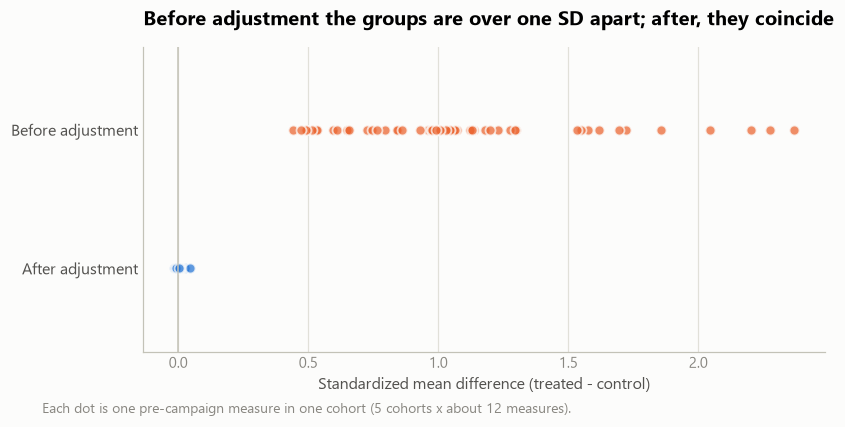

Absolute standardized mean difference: before adjustment mean 1.08, max 2.37; after adjustment mean 0.007, max 0.046


,cohort,treated,controls,control_ess
0,33,332,1862,84.004
1,47,113,1522,206.161
2,60,420,1051,92.225
3,73,82,859,32.136
4,85,86,832,60.070


In [14]:
main_setups = prepare(SPEND, cohort, COHORTS)

bal_rows = []
for s in main_setups:
    X, d = s["X"], s["d"]
    t, c = d == 1, d == 0
    Xs = (X - X[c].mean(0)) / (X[c].std(0) + 1e-9)
    wc = entropy_balance(Xs[c], Xs[t].mean(0), np.ones(c.sum()))
    pooled_sd = np.sqrt((X[t].var(0) + X[c].var(0)) / 2)
    for j, nm in enumerate(s["names"]):
        bal_rows.append(dict(cohort=s["g"], measure=nm, treated=X[t][:, j].mean(), control_raw=X[c][:, j].mean(),
                             control_adjusted=wc @ X[c][:, j],
                             smd_raw=(X[t][:, j].mean() - X[c][:, j].mean()) / pooled_sd[j],
                             smd_adjusted=(X[t][:, j].mean() - wc @ X[c][:, j]) / pooled_sd[j]))
balance = pd.DataFrame(bal_rows)
balance.to_csv(TAB / "balance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(balance.smd_raw, np.zeros(len(balance)) + 1, color=C_ORANGE, s=42, alpha=0.75, edgecolor=C_SURF, linewidth=1.2)
ax.scatter(balance.smd_adjusted, np.zeros(len(balance)), color=C_BLUE, s=42, alpha=0.75, edgecolor=C_SURF, linewidth=1.2)
ax.axvline(0, color=C_AXIS, lw=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["After adjustment", "Before adjustment"], fontsize=10.5, color=C_INK2)
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Standardized mean difference (treated - control)")
ax.grid(axis="x", color=C_GRID)
ax.grid(axis="y", visible=False)
ax.set_title("Before adjustment the groups are over one SD apart; after, they coincide")
finish(fig, "06_balance", "Each dot is one pre-campaign measure in one cohort (5 cohorts x about 12 measures).")

info = estimate(main_setups, "dr")["info"]
RESULTS["balance"] = dict(smd_raw_mean=float(balance.smd_raw.abs().mean()), smd_raw_max=float(balance.smd_raw.abs().max()),
                          smd_adj_mean=float(balance.smd_adjusted.abs().mean()), smd_adj_max=float(balance.smd_adjusted.abs().max()),
                          cohorts=info.to_dict("records"),
                          points=balance[["cohort", "measure", "smd_raw", "smd_adjusted"]].to_dict("records"))
print(f"Absolute standardized mean difference: before adjustment mean {balance.smd_raw.abs().mean():.2f}, max {balance.smd_raw.abs().max():.2f}; "
      f"after adjustment mean {balance.smd_adjusted.abs().mean():.3f}, max {balance.smd_adjusted.abs().max():.3f}")
info

**Reading the chart and table.**

- Before adjustment, the treated are on average more than one standard deviation above the controls on the pre-campaign measures. After adjustment every difference is below 0.05.
- **The price is effective sample size.** Each cohort nominally has 800–1,900 controls, but few of them are as active as the treated, so after weighting the effective sample size is only 30–200 households. That widens the confidence intervals, and it is a hard limit of this data: by the time a campaign starts, most heavy shoppers have already been selected.

### 7.2 Two lines: recipients and comparable controls

Align the cohorts on the week relative to the campaign start, average them, and plot the weekly spending of the two groups.

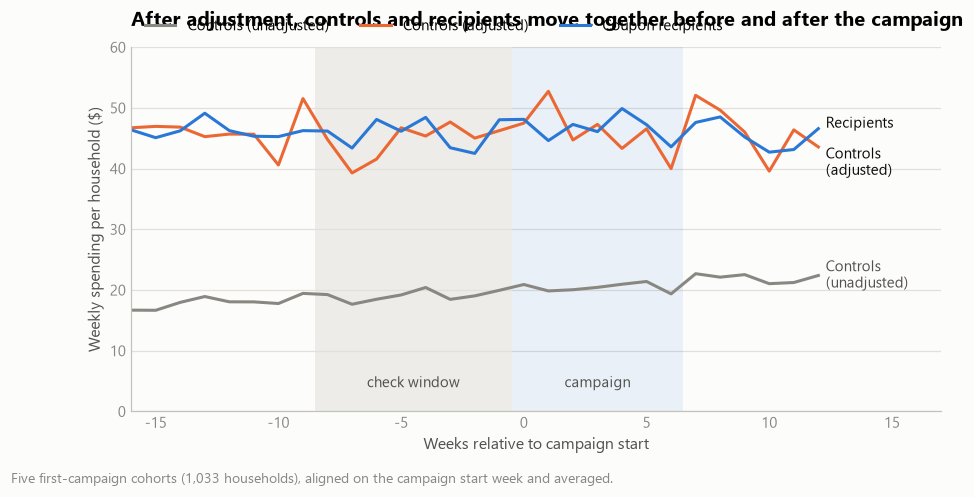

In [15]:
def group_levels(setups, balanced):
    """Mean spending of treated and controls in each event week (levels, no differencing)."""
    ks = np.arange(-PRE_SHOW, H + 1)
    T, C, N = [], [], []
    for s in setups:
        X, d, Y, g = s["X"], s["d"], s["Y"], s["g"]
        t, c = d == 1, d == 0
        if balanced:
            Xs = (X - X[c].mean(0)) / (X[c].std(0) + 1e-9)
            wc = entropy_balance(Xs[c], Xs[t].mean(0), np.ones(c.sum()))
        else:
            wc = np.ones(c.sum()) / c.sum()
        T.append(Y[t][:, g + ks - 1].mean(0))
        C.append(wc @ Y[c][:, g + ks - 1])
        N.append(t.sum())
    N = np.array(N)
    return ks, (N[:, None] * np.array(T)).sum(0) / N.sum(), (N[:, None] * np.array(C)).sum(0) / N.sum()


ks, lvl_t, lvl_c_raw = group_levels(main_setups, balanced=False)
_, _, lvl_c_bal = group_levels(main_setups, balanced=True)

fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.axvspan(-8.5, -0.5, color=C_GRID, alpha=0.55, lw=0)
ax.axvspan(-0.5, 6.5, color=C_BLUE, alpha=0.09, lw=0)
ax.plot(ks, lvl_c_raw, color=C_MUTED, label="Controls (unadjusted)")
ax.plot(ks, lvl_c_bal, color=C_ORANGE, label="Controls (adjusted)")
ax.plot(ks, lvl_t, color=C_BLUE, label="Coupon recipients")
ax.text(12.3, lvl_t[-1] + 0.8, "Recipients", color=C_INK, fontsize=10, va="center")
ax.text(12.3, lvl_c_bal[-1] - 2.6, "Controls\n(adjusted)", color=C_INK, fontsize=10, va="center")
ax.text(12.3, lvl_c_raw[-1], "Controls\n(unadjusted)", color=C_INK2, fontsize=10, va="center")
ax.text(-4.5, 4, "check window", ha="center", fontsize=9.5, color=C_INK2)
ax.text(3, 4, "campaign", ha="center", fontsize=9.5, color=C_INK2)
ax.set_xlim(-16, 17)
ax.set_ylim(0, 60)
ax.set_xlabel("Weeks relative to campaign start")
ax.set_ylabel("Weekly spending per household ($)")
ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0))
ax.set_title("After adjustment, controls and recipients move together before and after the campaign", pad=30)
finish(fig, "07_two_lines", "Five first-campaign cohorts (1,033 households), aligned on the campaign start week and averaged.")

RESULTS["levels"] = dict(ks=ks.tolist(), treated=lvl_t.tolist(), control_raw=lvl_c_raw.tolist(), control_balanced=lvl_c_bal.tolist())

**Reading the chart.**

- The **grey line** is the unadjusted control group. It spends under \$20 a week, nowhere near the recipients (blue, about \$46).
- The **orange line** is the adjusted control group. It sits at the same level as the blue line before the campaign, which is what the weighting was built to do. What matters is what follows: through the check window and the campaign, orange and blue stay tangled together, and the blue line does not lift off once the campaign begins.
- The orange line is jumpier than the blue one because its effective sample size is small.

### 7.3 Event study: the effect in each week

Subtract one line from the other (and take out the baseline difference) to get the estimated effect in each week with its 95% confidence interval. The plain, unadjusted DiD is drawn alongside for comparison.

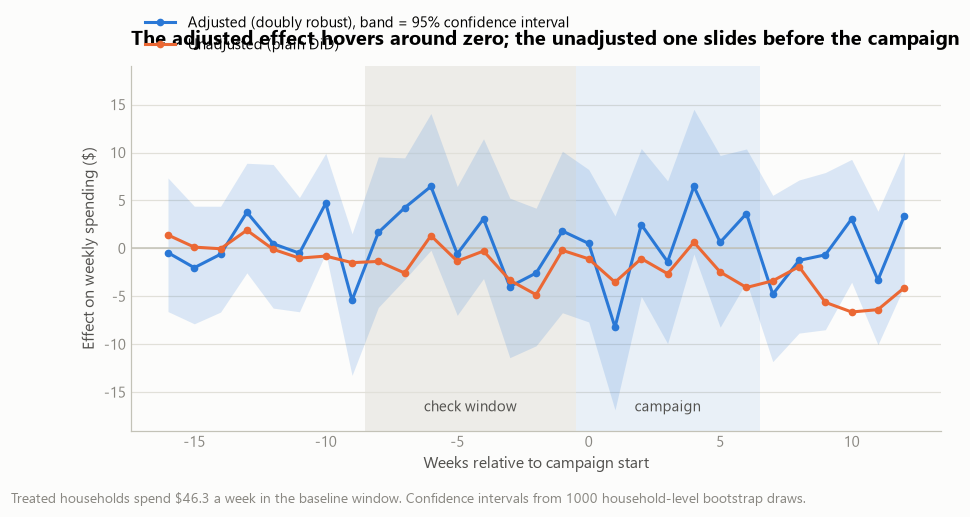

In [16]:
res = {m: estimate(main_setups, m, boot=BOOT) for m in ["did", "ra", "eb", "dr"]}
BASE = base_level(main_setups)

fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.axvspan(-8.5, -0.5, color=C_GRID, alpha=0.55, lw=0)
ax.axvspan(-0.5, 6.5, color=C_BLUE, alpha=0.09, lw=0)
ax.axhline(0, color=C_AXIS, lw=1)
r = res["dr"]
ax.fill_between(r["ks"], r["lo"], r["hi"], color=C_BLUE, alpha=0.16, lw=0)
ax.plot(r["ks"], r["att"], color=C_BLUE, marker="o", ms=4, label="Adjusted (doubly robust), band = 95% confidence interval")
ax.plot(res["did"]["ks"], res["did"]["att"], color=C_ORANGE, marker="o", ms=4, label="Unadjusted (plain DiD)")
ax.text(-4.5, -17, "check window", ha="center", fontsize=9.5, color=C_INK2)
ax.text(3, -17, "campaign", ha="center", fontsize=9.5, color=C_INK2)
ax.set_ylim(-19, 19)
ax.set_xlabel("Weeks relative to campaign start")
ax.set_ylabel("Effect on weekly spending ($)")
ax.legend(loc="lower left", ncol=1, bbox_to_anchor=(0, 1.0))
ax.set_title("The adjusted effect hovers around zero; the unadjusted one slides before the campaign", pad=44)
finish(fig, "08_event_study", f"Treated households spend ${BASE:.1f} a week in the baseline window. Confidence intervals from {BOOT} household-level bootstrap draws.")

**Reading the chart.**

- **Blue (adjusted):** hovers around zero in the check window and keeps hovering around zero once the campaign starts. There is no lift. The confidence interval includes zero in every week.
- **Orange (unadjusted):** starts sliding during the check window and keeps sliding afterwards. It shows a "negative effect" at a time when nobody had received a coupon, which is the regression to the mean from Section 4.3. Plain DiD cannot be trusted here.

### 7.4 Turning it into numbers

Average the weekly effects over each window and express them as a percentage of baseline spending. Besides dollars spent, we also look at the number of trips and at whether the household shopped at all in a week.

In [17]:
METHOD_NAME = {"did": "Plain DiD (no adjustment)", "ra": "Regression adjustment", "eb": "Entropy balancing", "dr": "Doubly robust (main)"}
rows = []
for m, r in res.items():
    for wn, (a, b) in WINDOWS.items():
        e = window_effect(r, a, b)
        rows.append(dict(estimator=METHOD_NAME[m], window=WINDOW_LABEL[wn], effect_usd=e["est"], lo_usd=e["lo"], hi_usd=e["hi"],
                         effect_pct=100 * e["est"] / BASE, lo_pct=100 * e["lo"] / BASE, hi_pct=100 * e["hi"] / BASE))
main_table = pd.DataFrame(rows)
main_table.to_csv(TAB / "main_effects.csv", index=False)

# Other outcomes: number of trips, and whether the household shopped that week
other_rows = []
for name, Yw in [("Trips per week", TRIPS), ("Shopped that week (0/1)", ACTIVE)]:
    st = prepare(Yw, cohort, COHORTS)
    b0 = base_level(st)
    for m in ["dr", "did"]:
        rr = estimate(st, m, boot=BOOT)
        for wn, (a, b) in WINDOWS.items():
            e = window_effect(rr, a, b)
            other_rows.append(dict(outcome=name, estimator=METHOD_NAME[m], window=WINDOW_LABEL[wn], window_key=wn, baseline=b0,
                                   effect=e["est"], lo=e["lo"], hi=e["hi"], effect_pct=100 * e["est"] / b0,
                                   lo_pct=100 * e["lo"] / b0, hi_pct=100 * e["hi"] / b0))
other_table = pd.DataFrame(other_rows)
other_table.to_csv(TAB / "main_effects_other_outcomes.csv", index=False)

RESULTS["main"] = dict(
    base_level=BASE, n_treated=int(sum(s["d"].sum() for s in main_setups)), boot=BOOT,
    event=dict(ks=res["dr"]["ks"].tolist(),
               **{m: dict(att=res[m]["att"].tolist(), lo=res[m]["lo"].tolist(), hi=res[m]["hi"].tolist()) for m in res}),
    windows={m: {wn: window_effect(res[m], a, b) for wn, (a, b) in WINDOWS.items()} for m in res},
    other_outcomes=other_table.to_dict("records"),
)

print(f"{RESULTS['main']['n_treated']} treated households; baseline weekly spending ${BASE:.2f}\n")
print("Effect as a percentage of baseline spending:")
main_table.pivot(index="estimator", columns="window", values="effect_pct").reindex(METHOD_NAME.values())[list(WINDOW_LABEL.values())].round(1)

1033 treated households; baseline weekly spending $46.26

Effect as a percentage of baseline spending:


window,Check window (8 weeks before),During campaign (weeks 0-6),After campaign (weeks 7-12)
estimator,,,
Plain DiD (no adjustment),-3.400,-4.400,-10.100
Regression adjustment,1.000,1.800,-2.300
Entropy balancing,2.400,1.300,-1.400
Doubly robust (main),2.700,1.300,-1.300


In [18]:
# Full results for the main estimator: dollars and percent, with 95% confidence intervals
show = main_table[main_table.estimator == METHOD_NAME["dr"]].set_index("window")
for wn, r_ in show.iterrows():
    print(f"{wn}: {r_.effect_usd:+.2f} $/week [{r_.lo_usd:+.2f}, {r_.hi_usd:+.2f}]   "
          f"= {r_.effect_pct:+.1f}% [{r_.lo_pct:+.1f}%, {r_.hi_pct:+.1f}%]")
print()
other_table[other_table.estimator == METHOD_NAME["dr"]].set_index(["outcome", "window"])[["baseline", "effect", "lo", "hi", "effect_pct"]].round(3)

Check window (8 weeks before): +1.27 $/week [-2.10, +5.40]   = +2.7% [-4.5%, +11.7%]
During campaign (weeks 0-6): +0.59 $/week [-3.50, +5.21]   = +1.3% [-7.6%, +11.3%]
After campaign (weeks 7-12): -0.59 $/week [-4.74, +4.08]   = -1.3% [-10.2%, +8.8%]



baseline  effect     lo    hi  effect_pct
outcome                 window                                                                  
Trips per week          Check window (8 weeks before)     1.660   0.017 -0.088 0.153       1.009
                        During campaign (weeks 0-6)       1.660   0.043 -0.087 0.192       2.616
                        After campaign (weeks 7-12)       1.660   0.066 -0.086 0.192       3.971
Shopped that week (0/1) Check window (8 weeks before)     0.711   0.023  0.001 0.049       3.201
                        During campaign (weeks 0-6)       0.711   0.022 -0.011 0.057       3.063
                        After campaign (weeks 7-12)       0.711   0.007 -0.025 0.039       1.036

**Reading the table.**

1. **Main estimate (doubly robust): during the campaign, weekly spending changes by about +\$0.6, or +1%, with a 95% confidence interval of roughly −8% to +11%.** Statistically that is indistinguishable from zero. The same holds after the campaign ends.
2. **The check window passes.** In the 8 weeks before the campaign the two groups differ by about +\$1, with a confidence interval that includes zero. The controls track the treated over 8 weeks that were not used for the adjustment, and that is the main reason to trust the result.
3. **The three adjustment methods agree.** Regression adjustment, entropy balancing and the doubly robust estimator give almost the same numbers, so the conclusion does not hinge on one particular way of adjusting.
4. **Plain DiD cannot be trusted.** It reports a "significant negative effect" of −4% during the campaign and −10% afterwards, but it is already at −3% in the check window. It fails the check.
5. **Trips and store visits do not rise.** The difference in trips is small with a confidence interval that includes zero. The share of weeks with a visit is already about 2 percentage points higher in the check window (the lower end of its interval sits right at zero), and the difference during the campaign is the same size. It does not widen.

**How to read this result.** The accurate statement is: "**no effect was detected, and a lift larger than about 11% can be ruled out.**" That is not the same as proving the effect is zero. The confidence interval still leaves room for a positive or negative effect of a few percent. To go further we need evidence that sits closer to the mechanism, which is what Sections 9 and 10 provide.

## 8. The same question with the course toolkit

Section 7 answered the question with one estimator built for this data. This section answers it again with the methods taught in the course, all applied to the stacked table from Section 4.4 (one row per household per cohort), and all adjusting for the backdoor set from Section 5: the twelve pre-campaign measures plus the cohort.

| Course week | Method |
|---|---|
| 1, 3 | OLS with a treatment dummy, then with covariates (ANCOVA); partial correlation |
| 3, 5 | Propensity scores, used four ways: matching, stratification, inverse probability weighting, covariate adjustment |
| 5, 6 | DoWhy: model, identify, estimate, refute |
| 7 | Meta-learners (S, T, X); double machine learning; doubly robust learner; causal forest |

**One rule for judging every method: the placebo test.** Each method is run twice with exactly the same adjustment. Once with the real outcome, spending during the campaign. And once with a **placebo outcome**: spending in the 8-week check window, when no household had a coupon yet. The true effect on the placebo outcome is zero, so whatever a method reports there is its bias. A method that reports a large "effect" before the campaign cannot be trusted during it.

### 8.1 The OLS view (Weeks 1 and 3)

Start where the course started: regress the outcome on a treatment dummy, then add the covariates.

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xdf = pd.concat([STK[XCOLS], cohort_dummies], axis=1)            # backdoor set: 12 measures + cohort
Tv = STK["T"].values
groups = STK.household_key.values
BASE_STK = STK.loc[Tv == 1, "y_base"].mean()                      # treated households' baseline spending, for percentages

# 1. Dummy-variable regression: outcome on treatment (and cohort) only. Standard errors clustered by household,
#    because a control household can appear in several cohorts.
dummy_reg = sm.OLS(STK.y_during, sm.add_constant(pd.concat([STK[["T"]], cohort_dummies], axis=1))).fit(
    cov_type="cluster", cov_kwds={"groups": groups})
# 2. ANCOVA: add the pre-campaign covariates
ancova = sm.OLS(STK.y_during, sm.add_constant(pd.concat([STK[["T"]], Xdf], axis=1))).fit(cov_type="cluster", cov_kwds={"groups": groups})
ancova_placebo = sm.OLS(STK.y_check, sm.add_constant(pd.concat([STK[["T"]], Xdf], axis=1))).fit(cov_type="cluster", cov_kwds={"groups": groups})

# 3. Partial correlation (Week 1): correlate what is left of T and of Y after removing the covariates.
#    The slope of residual on residual equals the ANCOVA coefficient (the idea double ML builds on in Week 7).
res_T = sm.OLS(STK["T"], sm.add_constant(Xdf)).fit().resid
res_Y = sm.OLS(STK.y_during, sm.add_constant(Xdf)).fit().resid
raw_corr = np.corrcoef(Tv, STK.y_during)[0, 1]
partial_corr = np.corrcoef(res_T, res_Y)[0, 1]
fwl_slope = float(np.polyfit(res_T, res_Y, 1)[0])

# 4. Multicollinearity among the covariates (Week 1): variance inflation factors
Xv_ = sm.add_constant(STK[XCOLS])
vif = pd.Series([variance_inflation_factor(Xv_.values, i) for i in range(1, Xv_.shape[1])], index=XCOLS)

# 5. ANCOVA's key assumption (Week 3): no treatment x covariate interaction. F-test of the 12 interactions.
Xint = sm.add_constant(pd.concat([STK[["T"]], Xdf], axis=1))
for c in XCOLS:
    Xint["T_x_" + c] = STK["T"] * (STK[c] - STK[c].mean())
f_int, p_int, df_int = sm.OLS(STK.y_during, Xint).fit().compare_f_test(sm.OLS(STK.y_during, sm.add_constant(pd.concat([STK[["T"]], Xdf], axis=1))).fit())

ols_view = pd.DataFrame({
    "coefficient on T ($/week)": [dummy_reg.params["T"], ancova.params["T"], ancova_placebo.params["T"]],
    "95% CI low": [dummy_reg.conf_int().loc["T", 0], ancova.conf_int().loc["T", 0], ancova_placebo.conf_int().loc["T", 0]],
    "95% CI high": [dummy_reg.conf_int().loc["T", 1], ancova.conf_int().loc["T", 1], ancova_placebo.conf_int().loc["T", 1]],
    "R-squared": [dummy_reg.rsquared, ancova.rsquared, ancova_placebo.rsquared],
}, index=["Dummy regression (no covariates)", "ANCOVA (12 covariates)", "ANCOVA on the placebo outcome"])

print(f"Correlation of T and spending: {raw_corr:.3f}.  Partial correlation given the covariates: {partial_corr:.3f}.")
print(f"Residual-on-residual slope: {fwl_slope:.2f} (identical to the ANCOVA coefficient {ancova.params['T']:.2f}).")
print(f"Variance inflation factors of the covariates: {vif.min():.1f} to {vif.max():.1f}.")
print(f"F-test of treatment x covariate interactions: F = {f_int:.1f}, df = {int(df_int)}, p = {p_int:.4f}.")
RESULTS["ols_view"] = dict(dummy=float(dummy_reg.params["T"]), ancova=float(ancova.params["T"]),
                           ancova_lo=float(ancova.conf_int().loc["T", 0]), ancova_hi=float(ancova.conf_int().loc["T", 1]),
                           ancova_placebo=float(ancova_placebo.params["T"]), r2_dummy=float(dummy_reg.rsquared), r2_ancova=float(ancova.rsquared),
                           raw_corr=float(raw_corr), partial_corr=float(partial_corr), vif_min=float(vif.min()), vif_max=float(vif.max()),
                           f_interaction=float(f_int), p_interaction=float(p_int), base=float(BASE_STK))
ols_view.round(2)

Correlation of T and spending: 0.244.  Partial correlation given the covariates: 0.011.
Residual-on-residual slope: 0.90 (identical to the ANCOVA coefficient 0.90).
Variance inflation factors of the covariates: 3.8 to 8.1.
F-test of treatment x covariate interactions: F = 8.4, df = 12, p = 0.0000.


,coefficient on T ($/week),95% CI low,95% CI high,R-squared
Dummy regression (no covariates),25.750,23.080,28.420,0.090
ANCOVA (12 covariates),0.900,-1.580,3.380,0.620
ANCOVA on the placebo outcome,0.210,-1.710,2.130,0.720


**Reading the table.**

- **The dummy regression** repeats the raw gap: about +\$26 a week. With no covariates the treatment dummy soaks up everything that differs between the groups.
- **ANCOVA** adds the twelve pre-campaign covariates and the coefficient on T collapses to under \$1, with a confidence interval that includes zero. The same regression on the placebo outcome gives a number close to zero, as it should.
- **Partial correlation.** T and spending are clearly correlated in the raw data; once the covariates are taken out of both, the correlation is essentially nil. The residual-on-residual slope equals the ANCOVA coefficient exactly. Week 7's double machine learning is the same idea with flexible models in place of OLS.
- **Multicollinearity.** The covariates are strongly related to one another (variance inflation factors of roughly 4 to 8). That blurs the individual covariate coefficients, which we do not interpret, and does no harm to the coefficient on T.
- **The ANCOVA assumption fails.** ANCOVA assumes the treatment does not interact with the covariates. The F-test rejects that. So one common coefficient is a simplification: the effect may differ across kinds of household. This is the motivation for the T-learner and causal forest below, which let it vary.

### 8.2 Propensity scores, four ways (Weeks 3 to 5)

The propensity score is the probability of receiving the campaign given the pre-campaign history, $p_i = P(T{=}1 \mid H_i)$. We estimate it with a logistic regression and then use it in the four ways taught in Week 3.

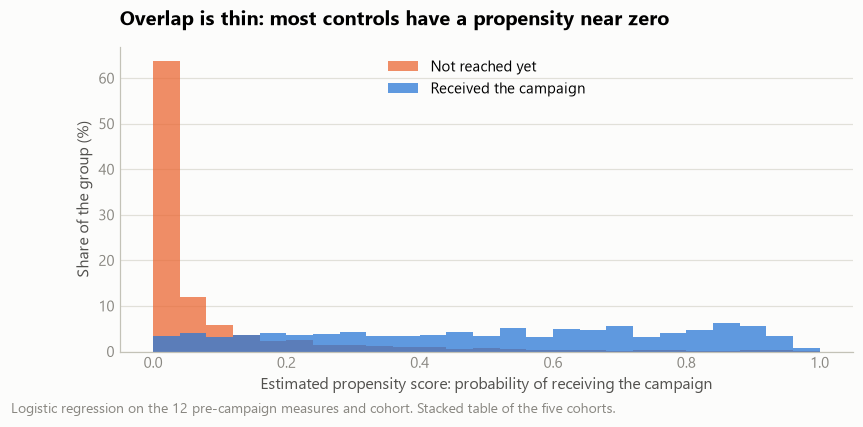

Median propensity: treated 0.54, controls 0.02.
Controls with a propensity above 0.2: 779 of 6,126.
Effective sample size of the controls under ATT weights: 191.


In [20]:
from sklearn.linear_model import LogisticRegression, LinearRegression, LassoCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

COHORT_V = STK.cohort.values


def propensity(X, T):
    """Propensity score from a logistic regression on standardized covariates."""
    Xs = StandardScaler().fit_transform(X)
    return LogisticRegression(C=1.0, max_iter=5000).fit(Xs, T).predict_proba(Xs)[:, 1]


def ps_matching(y, T, ps, coh, caliper=0.2):
    """1-nearest-neighbour matching on the logit of the PS, within cohort, with replacement.
    Caliper = 0.2 standard deviations of the logit (the Week 3 guideline); unmatched treated rows are dropped."""
    lg = np.log(ps / (1 - ps))
    cal = caliper * lg.std()
    diffs = []
    for c in np.unique(coh):
        it = np.where((T == 1) & (coh == c))[0]
        ic = np.where((T == 0) & (coh == c))[0]
        if len(it) == 0 or len(ic) < 2:
            continue
        order = np.argsort(lg[ic])
        lc = lg[ic][order]
        pos = np.searchsorted(lc, lg[it]).clip(1, len(lc) - 1)
        pick = np.where(np.abs(lg[it] - lc[pos - 1]) <= np.abs(lc[pos] - lg[it]), pos - 1, pos)
        ok = np.abs(lc[pick] - lg[it]) <= cal
        diffs.append(y[it][ok] - y[ic][order][pick][ok])
    d = np.concatenate(diffs)
    return d.mean(), len(d)


def ps_stratification(y, T, ps, k=5):
    """Split on quintiles of the treated households' PS; average the within-stratum gaps, weighted by treated counts (ATT)."""
    cuts = np.quantile(ps[T == 1], np.linspace(0, 1, k + 1))[1:-1]
    s = np.digitize(ps, cuts)
    tot = n = 0.0
    for j in range(k):
        m = s == j
        nt, nc = (T[m] == 1).sum(), (T[m] == 0).sum()
        if nt and nc:
            tot += nt * (y[m][T[m] == 1].mean() - y[m][T[m] == 0].mean())
            n += nt
    return tot / n


def iptw_att(y, T, ps):
    """Inverse probability weighting for the ATT: treated weight 1, control weight p/(1-p)."""
    w = ps / (1 - ps)
    return y[T == 1].mean() - np.average(y[T == 0], weights=w[T == 0])


def iptw_ate(y, T, ps):
    """The textbook version for the ATE: weights 1/p and 1/(1-p), with the PS clipped to [0.01, 0.99]."""
    p = ps.clip(0.01, 0.99)
    return np.average(y, weights=T / p) - np.average(y, weights=(1 - T) / (1 - p))


def ps_covariate(y, T, ps, dummies):
    """Regress the outcome on the treatment dummy and the PS (plus cohort)."""
    A = np.column_stack([np.ones(len(y)), T, ps, dummies])
    return np.linalg.lstsq(A, y, rcond=None)[0][1]


def ols_coef(y, T, X):
    A = np.column_stack([np.ones(len(y)), T, X])
    return np.linalg.lstsq(A, y, rcond=None)[0][1]


PS = propensity(Xdf.values, Tv)
w_att = np.where(Tv == 1, 1.0, PS / (1 - PS))
ess_iptw = w_att[Tv == 0].sum() ** 2 / (w_att[Tv == 0] ** 2).sum()

fig, ax = plt.subplots(figsize=(8.6, 3.6))
bins = np.linspace(0, 1, 26)
ax.hist(PS[Tv == 0], bins=bins, weights=np.full((Tv == 0).sum(), 100 / (Tv == 0).sum()), color=C_ORANGE, alpha=0.75, label="Not reached yet")
ax.hist(PS[Tv == 1], bins=bins, weights=np.full((Tv == 1).sum(), 100 / (Tv == 1).sum()), color=C_BLUE, alpha=0.75, label="Received the campaign")
ax.set_xlabel("Estimated propensity score: probability of receiving the campaign")
ax.set_ylabel("Share of the group (%)")
ax.legend(loc="upper center")
ax.set_title("Overlap is thin: most controls have a propensity near zero")
finish(fig, "08b_overlap", "Logistic regression on the 12 pre-campaign measures and cohort. Stacked table of the five cohorts.")

print(f"Median propensity: treated {np.median(PS[Tv == 1]):.2f}, controls {np.median(PS[Tv == 0]):.2f}.")
print(f"Controls with a propensity above 0.2: {(PS[Tv == 0] > 0.2).sum():,} of {(Tv == 0).sum():,}.")
print(f"Effective sample size of the controls under ATT weights: {ess_iptw:.0f}.")
RESULTS["propensity"] = dict(median_treated=float(np.median(PS[Tv == 1])), median_control=float(np.median(PS[Tv == 0])),
                             controls_above_02=int((PS[Tv == 0] > 0.2).sum()), n_controls=int((Tv == 0).sum()), ess_iptw=float(ess_iptw),
                             hist_bins=bins.tolist(),
                             hist_treated=(np.histogram(PS[Tv == 1], bins)[0] / (Tv == 1).sum()).tolist(),
                             hist_control=(np.histogram(PS[Tv == 0], bins)[0] / (Tv == 0).sum()).tolist())

**Reading the chart.** The two groups barely share the same range of propensity scores. Most control rows have a score close to zero: they are light shoppers the retailer would never have picked. Fewer than 800 of about 6,100 control rows have a score above 0.2, and under the weights needed to make the controls resemble the recipients they carry the information of only about 190 households. Any weighting scheme has to lean on those few rows heavily, which is the drawback of inverse probability weighting flagged in Weeks 3 and 7 (extreme scores get extreme weights).

### 8.3 DoWhy: model, identify, estimate, refute (Weeks 5 and 6)

DoWhy makes the four steps explicit. We give it the treatment, the outcome and the common causes (the backdoor set); it returns the estimand, estimates it, and then tries to break the estimate with refutation tests.

In [21]:
from dowhy import CausalModel

dw = pd.concat([STK[["y_during", "y_check"]], Xdf], axis=1)
dw["T"] = STK["T"].astype(bool)
common_causes = list(Xdf.columns)

model = CausalModel(data=dw, treatment="T", outcome="y_during", common_causes=common_causes)          # 1. model
estimand = model.identify_effect(proceed_when_unidentifiable=True)                                    # 2. identify
print("Identified estimand:", estimand.estimands["backdoor"]["estimand"] if hasattr(estimand, "estimands") else "backdoor")

dowhy_est = {}
for label, method, kw in [("DoWhy: linear regression", "backdoor.linear_regression", {}),
                          ("DoWhy: PS stratification", "backdoor.propensity_score_stratification", {"target_units": "att"}),
                          ("DoWhy: PS matching", "backdoor.propensity_score_matching", {"target_units": "att"}),
                          ("DoWhy: PS weighting", "backdoor.propensity_score_weighting", {"target_units": "att"})]:
    dowhy_est[label] = float(model.estimate_effect(estimand, method_name=method, **kw).value)        # 3. estimate
model_placebo = CausalModel(data=dw, treatment="T", outcome="y_check", common_causes=common_causes)
estimand_placebo = model_placebo.identify_effect(proceed_when_unidentifiable=True)
dowhy_placebo = {label: float(model_placebo.estimate_effect(estimand_placebo, method_name=method, **kw).value)
                 for label, method, kw in [("DoWhy: linear regression", "backdoor.linear_regression", {}),
                                           ("DoWhy: PS stratification", "backdoor.propensity_score_stratification", {"target_units": "att"}),
                                           ("DoWhy: PS matching", "backdoor.propensity_score_matching", {"target_units": "att"}),
                                           ("DoWhy: PS weighting", "backdoor.propensity_score_weighting", {"target_units": "att"})]}

# 4. refute: three attempts to break the linear-regression estimate
np.random.seed(SEED)
main_est = model.estimate_effect(estimand, method_name="backdoor.linear_regression")
refutations = []
for label, method, kw in [("Placebo treatment (shuffle who was treated)", "placebo_treatment_refuter", dict(placebo_type="permute", num_simulations=50)),
                          ("Add a random common cause", "random_common_cause", dict(num_simulations=50)),
                          ("Re-estimate on random 80% subsets", "data_subset_refuter", dict(subset_fraction=0.8, num_simulations=50))]:
    r_ = model.refute_estimate(estimand, main_est, method_name=method, **kw)
    refutations.append(dict(refuter=label, original_estimate=float(main_est.value), new_estimate=float(r_.new_effect),
                            p_value=float(r_.refutation_result["p_value"]) if r_.refutation_result else np.nan))
refutations = pd.DataFrame(refutations)
RESULTS["dowhy"] = dict(estimates=dowhy_est, placebo=dowhy_placebo, refutations=refutations.to_dict("records"))
print(pd.DataFrame({"campaign ($/week)": dowhy_est, "placebo ($/week)": dowhy_placebo}).round(2).to_string(), "\n")
refutations.round(3)

Identified estimand: Derivative(Expectation(y_during|active_b0,spend_b1,trips_b0,spend_b2,trips_b3,cohort_60,active_b1,spend_b0,trips_b1,active_b3,cohort_47,cohort_85,cohort_73,active_b2,spend_b3,trips_b2), [T])


                          campaign ($/week)  placebo ($/week)
DoWhy: linear regression              0.900             0.210
DoWhy: PS stratification             -7.090            -6.170
DoWhy: PS matching                   -6.030            -6.200
DoWhy: PS weighting                  -4.910            -5.420 



,refuter,original_estimate,new_estimate,p_value
0,Placebo treatment (shuffle who was treated),0.903,-0.139,0.428
1,Add a random common cause,0.903,0.903,0.476
2,Re-estimate on random 80% subsets,0.903,0.944,0.473


**Reading the output.**

- **Identify.** DoWhy returns the backdoor estimand: the effect of T on spending, conditioning on the twelve measures and cohort. It lists unconfoundedness as the assumption the estimate rests on, which is the conditional exchangeability of Section 5.2.
- **Estimate.** DoWhy's linear-regression estimate matches the ANCOVA coefficient of Section 8.1. Its propensity-score estimators give clearly negative numbers, for the campaign and for the placebo outcome alike. We come back to that in Section 8.5.
- **Refute.** Shuffling who was treated drives the estimate to about zero, as it should. Adding a random common cause, or re-estimating on random subsets, leaves it essentially where it was. The estimate survives all three.

One caution: these refuters test stability, not truth. None of them can detect a confounder we failed to measure. The placebo *outcome* test used throughout this section is more demanding, because it checks the estimate against a case where the true answer is known.

### 8.4 Machine-learning estimators (Week 7)

Now the Week 7 toolkit, from EconML:

| Learner | How it works |
|---|---|
| **S-learner** | One model of spending on covariates and treatment together; the effect is the difference in its predictions with T switched on and off |
| **T-learner** | Two models, one fitted on treated rows and one on controls; the effect is the difference in their predictions |
| **X-learner** | Builds on the T-learner: imputes each row's individual effect, models those, and blends the two models with the propensity score |
| **Double ML** | Residualize spending and treatment on the covariates with ML models (cross-fitted), then regress residual on residual |
| **Doubly robust learner** | Combines an outcome model and a propensity model; consistent if either one is right |
| **Causal forest** | A forest that splits to find groups with different treatment effects; gives an effect for each household |

All effects are averaged over the treated rows, so every number is an ATT and comparable with Section 7.

In [22]:
from econml.metalearners import SLearner, TLearner, XLearner
from econml.dml import LinearDML, CausalForestDML
from econml.dr import LinearDRLearner

Xs_all = StandardScaler().fit_transform(Xdf.values)
gb = lambda: GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0)
logit = lambda: LogisticRegression(max_iter=5000)
on_treated = lambda est: float(est.effect(Xs_all[Tv == 1]).mean())          # ATT: average the household effects over treated rows

ML = {
    "S-learner (linear)": lambda y: (on_treated(SLearner(overall_model=LinearRegression()).fit(y, Tv, X=Xs_all)), None),
    "S-learner (gradient boosting)": lambda y: (on_treated(SLearner(overall_model=gb()).fit(y, Tv, X=Xs_all)), None),
    "T-learner (linear)": lambda y: (on_treated(TLearner(models=LinearRegression()).fit(y, Tv, X=Xs_all)), None),
    "T-learner (gradient boosting)": lambda y: (on_treated(TLearner(models=gb()).fit(y, Tv, X=Xs_all)), None),
    "X-learner (gradient boosting)": lambda y: (on_treated(XLearner(models=gb(), propensity_model=logit()).fit(y, Tv, X=Xs_all)), None),
}


def fit_dml(y):
    est = LinearDML(model_y=gb(), model_t=logit(), discrete_treatment=True, cv=5, random_state=0).fit(y, Tv, X=None, W=Xs_all)
    lo, hi = est.effect_interval()
    return float(est.effect()[0]), (float(lo[0]), float(hi[0]))


def fit_dml_lasso(y):
    est = LinearDML(model_y=LassoCV(), model_t=logit(), discrete_treatment=True, cv=5, random_state=0).fit(y, Tv, X=None, W=Xs_all)
    lo, hi = est.effect_interval()
    return float(est.effect()[0]), (float(lo[0]), float(hi[0]))


def fit_dr(y):
    est = LinearDRLearner(model_regression=gb(), model_propensity=logit(), cv=5, min_propensity=0.01, random_state=0).fit(y, Tv, X=Xs_all)
    lo, hi = est.ate_interval(Xs_all[Tv == 1])
    return float(est.ate(Xs_all[Tv == 1])), (float(lo), float(hi))


CF_MODELS = {}


def fit_forest(y, key=None):
    est = CausalForestDML(model_y=gb(), model_t=logit(), discrete_treatment=True, cv=5, n_estimators=400, min_samples_leaf=20,
                          random_state=0).fit(y, Tv, X=Xs_all)
    if key:
        CF_MODELS[key] = est                     # keep the fitted forest: Section 11 uses its household-level effects
    lo, hi = est.ate_interval(Xs_all[Tv == 1])
    return float(est.ate(Xs_all[Tv == 1])), (float(lo), float(hi))


ML.update({"Double ML (gradient boosting)": fit_dml, "Double ML (lasso)": fit_dml_lasso, "Doubly robust learner": fit_dr})

ml_rows = {}
for name, f in ML.items():
    (pl, pl_ci), (ca, ca_ci) = f(STK.y_check.values), f(STK.y_during.values)
    ml_rows[name] = dict(placebo=pl, campaign=ca, lo=ca_ci[0] if ca_ci else np.nan, hi=ca_ci[1] if ca_ci else np.nan)
(pl, _), (ca, ca_ci) = fit_forest(STK.y_check.values), fit_forest(STK.y_during.values, key="y_during")
ml_rows["Causal forest"] = dict(placebo=pl, campaign=ca, lo=ca_ci[0], hi=ca_ci[1])
pd.DataFrame(ml_rows).T.round(2)

,placebo,campaign,lo,hi
S-learner (linear),0.210,0.900,NaN,NaN
S-learner (gradient boosting),0.280,1.290,NaN,NaN
T-learner (linear),0.170,0.540,NaN,NaN
T-learner (gradient boosting),1.910,2.390,NaN,NaN
X-learner (gradient boosting),2.030,2.710,NaN,NaN
Double ML (gradient boosting),0.980,0.870,-1.920,3.660
Double ML (lasso),-0.180,0.210,-2.420,2.850
Doubly robust learner,-0.560,-0.150,-6.720,6.420
Causal forest,0.850,0.660,-7.000,8.330


### 8.5 All methods side by side

The table below puts every method in one place, in dollars per week and as a share of the treated households' baseline spending. Confidence intervals for the regression and propensity-score methods come from a household-level bootstrap (300 draws, re-estimating the propensity score each time). For double ML, the doubly robust learner and the causal forest they are the intervals EconML reports, which treat rows as independent and are therefore somewhat too narrow here.

In [23]:
def simple_estimators(D):
    """The fast estimators on one (possibly resampled) stacked table. Returns {method: {outcome: estimate}}."""
    T = D["T"].values
    dm = pd.get_dummies(D.cohort, prefix="cohort", drop_first=True).astype(float).values
    X = np.column_stack([D[XCOLS].values, dm])
    Xs = StandardScaler().fit_transform(X)
    ps = propensity(X, T)
    out = {}
    for oc in ("y_check", "y_during"):
        y = D[oc].values
        out.setdefault("Raw difference in means", {})[oc] = y[T == 1].mean() - y[T == 0].mean()
        out.setdefault("ANCOVA (OLS with covariates)", {})[oc] = ols_coef(y, T, Xs)
        out.setdefault("PS matching (caliper 0.2 SD)", {})[oc] = ps_matching(y, T, ps, D.cohort.values)[0]
        out.setdefault("PS stratification (quintiles)", {})[oc] = ps_stratification(y, T, ps)
        out.setdefault("Inverse probability weighting (ATT)", {})[oc] = iptw_att(y, T, ps)
        out.setdefault("Covariate adjustment with the PS", {})[oc] = ps_covariate(y, T, ps, dm)
    return out


point = simple_estimators(STK)
n_matched = ps_matching(STK.y_during.values, Tv, PS, COHORT_V)[1]

# Household-level bootstrap for the fast estimators
rng = np.random.default_rng(SEED)
hh_ids = STK.household_key.unique()
rows_of = STK.groupby("household_key").indices
draws = {m: {"y_check": [], "y_during": []} for m in point}
for b in range(300):
    pick = rng.choice(hh_ids, len(hh_ids))
    Db = STK.iloc[np.concatenate([rows_of[h] for h in pick])]
    for m, v in simple_estimators(Db).items():
        for oc in v:
            draws[m][oc].append(v[oc])

FAMILY = {"Raw difference in means": "No adjustment", "ANCOVA (OLS with covariates)": "Regression (Weeks 1, 3)",
          "PS matching (caliper 0.2 SD)": "Propensity score (Weeks 3-5)", "PS stratification (quintiles)": "Propensity score (Weeks 3-5)",
          "Inverse probability weighting (ATT)": "Propensity score (Weeks 3-5)", "Covariate adjustment with the PS": "Propensity score (Weeks 3-5)"}
rows = []
for m, v in point.items():
    d_ca, d_pl = np.array(draws[m]["y_during"]), np.array(draws[m]["y_check"])
    rows.append(dict(method=m, family=FAMILY[m], placebo=v["y_check"], placebo_lo=np.percentile(d_pl, 2.5), placebo_hi=np.percentile(d_pl, 97.5),
                     campaign=v["y_during"], lo=np.percentile(d_ca, 2.5), hi=np.percentile(d_ca, 97.5), ci="household bootstrap"))
for m, v in ml_rows.items():
    fam = "Meta-learner (Week 7)" if "learner (" in m and m[0] in "STX" else "Orthogonal / doubly robust ML (Week 7)"
    rows.append(dict(method=m, family=fam, placebo=v["placebo"], placebo_lo=np.nan, placebo_hi=np.nan, campaign=v["campaign"], lo=v["lo"], hi=v["hi"],
                     ci="EconML (rows treated as independent)" if not np.isnan(v["lo"]) else "none"))
main_dr = RESULTS["main"]["windows"]["dr"]
rows.append(dict(method="Balancing weights + regression (Section 7)", family="This project's main estimator",
                 placebo=main_dr["holdout"]["est"], placebo_lo=main_dr["holdout"]["lo"], placebo_hi=main_dr["holdout"]["hi"],
                 campaign=main_dr["during"]["est"], lo=main_dr["during"]["lo"], hi=main_dr["during"]["hi"], ci="household bootstrap"))
toolkit = pd.DataFrame(rows)
toolkit["campaign_pct"] = 100 * toolkit.campaign / BASE_STK
toolkit["placebo_pct"] = 100 * toolkit.placebo / BASE_STK
toolkit["campaign_minus_placebo"] = toolkit.campaign - toolkit.placebo
toolkit["placebo_size"] = pd.cut(toolkit.placebo.abs(), [-1, 1, 2, 1e9], labels=["within $1", "$1 to $2", "more than $2"]).astype(str)
toolkit.to_csv(TAB / "course_toolkit.csv", index=False)
RESULTS["toolkit"] = dict(base=float(BASE_STK), n_rows=int(len(STK)), n_treated=int(Tv.sum()), n_matched=int(n_matched), table=toolkit.to_dict("records"))

show = toolkit[["method", "family", "placebo", "placebo_size", "campaign", "lo", "hi", "campaign_pct", "campaign_minus_placebo"]]
show.round(2)

,method,family,placebo,placebo_size,campaign,lo,hi,campaign_pct,campaign_minus_placebo
0,Raw difference in means,No adjustment,25.930,more than $2,25.600,22.890,28.280,55.350,-0.330
1,ANCOVA (OLS with covariates),"Regression (Weeks 1, 3)",0.210,within $1,0.900,-1.690,3.230,1.950,0.700
2,PS matching (caliper 0.2 SD),Propensity score (Weeks 3-5),-1.440,$1 to $2,-3.650,-10.030,6.310,-7.890,-2.210
3,PS stratification (quintiles),Propensity score (Weeks 3-5),-1.660,$1 to $2,-1.920,-5.050,3.330,-4.160,-0.270
4,Inverse probability weighting (ATT),Propensity score (Weeks 3-5),-7.970,more than $2,-6.990,-20.010,-0.380,-15.110,0.990
5,Covariate adjustment with the PS,Propensity score (Weeks 3-5),0.260,within $1,0.650,-1.830,3.280,1.400,0.380
6,S-learner (linear),Meta-learner (Week 7),0.210,within $1,0.900,NaN,NaN,1.950,0.700
7,S-learner (gradient boosting),Meta-learner (Week 7),0.280,within $1,1.290,NaN,NaN,2.790,1.010
8,T-learner (linear),Meta-learner (Week 7),0.170,within $1,0.540,NaN,NaN,1.170,0.370
9,T-learner (gradient boosting),Meta-learner (Week 7),1.910,$1 to $2,2.390,NaN,NaN,5.170,0.480


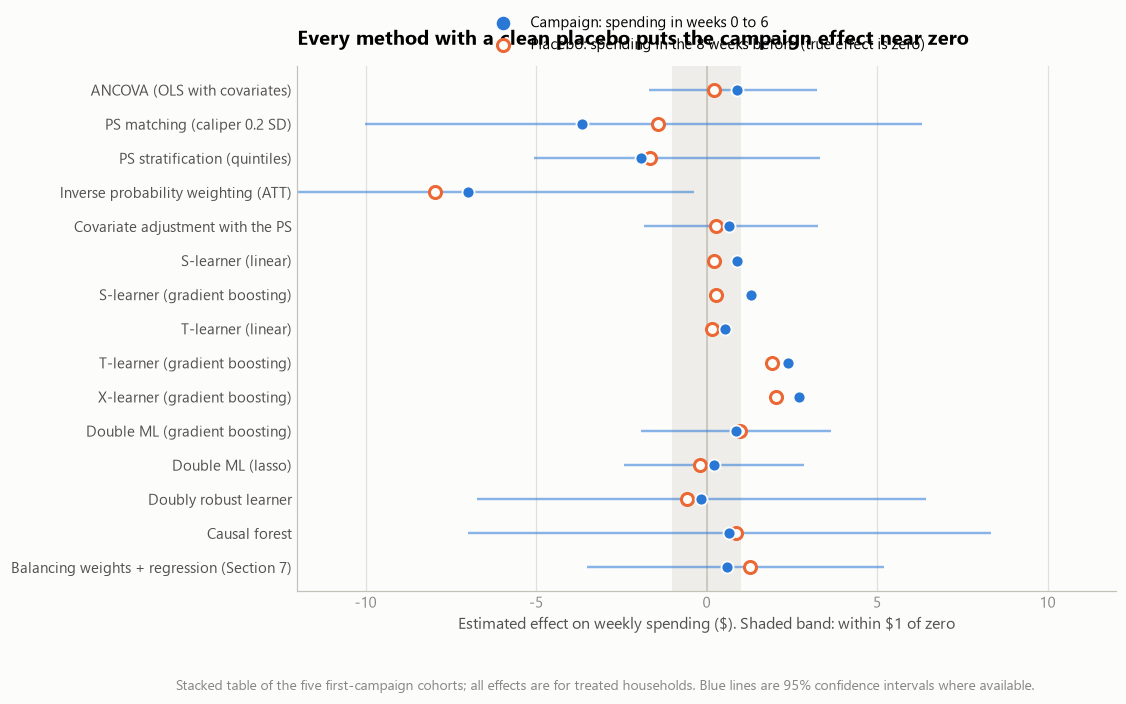

9 methods have a placebo estimate within $1 of zero. Their campaign estimates run from -0.15 to +1.29 $/week (-0.3% to +2.8% of baseline).
4 have a placebo between $1 and $2: PS matching (caliper 0.2 SD) (placebo -1.4, campaign -3.6); PS stratification (quintiles) (placebo -1.7, campaign -1.9); T-learner (gradient boosting) (placebo +1.9, campaign +2.4); Balancing weights + regression (Section 7) (placebo +1.3, campaign +0.6)
2 miss by more than $2: Inverse probability weighting (ATT) (placebo -8.0, campaign -7.0); X-learner (gradient boosting) (placebo +2.0, campaign +2.7)
Campaign minus placebo, all 15 adjusted methods: -2.21 to +1.01 $/week.


In [24]:
# Dot plot: placebo (hollow) and campaign (filled) estimate for each method. The raw difference is off the scale and is noted in the title.
plot = toolkit[toolkit.method != "Raw difference in means"].reset_index(drop=True)
raw = toolkit[toolkit.method == "Raw difference in means"].iloc[0]

fig, ax = plt.subplots(figsize=(9.6, 6.2))
y = np.arange(len(plot))
ax.axvspan(-1, 1, color=C_GRID, alpha=0.5, lw=0)
ax.axvline(0, color=C_AXIS, lw=1)
for i, r_ in plot.iterrows():
    if not np.isnan(r_.lo):
        ax.hlines(i, r_.lo, r_.hi, color=C_BLUE, lw=1.6, alpha=0.55)
    ax.scatter(r_.placebo, i, s=62, facecolor=C_SURF, edgecolor=C_ORANGE, linewidth=2, zorder=3)
    ax.scatter(r_.campaign, i, s=62, color=C_BLUE, zorder=4, edgecolor=C_SURF, linewidth=1.2)
ax.scatter([], [], s=62, color=C_BLUE, label="Campaign: spending in weeks 0 to 6")
ax.scatter([], [], s=62, facecolor=C_SURF, edgecolor=C_ORANGE, linewidth=2, label="Placebo: spending in the 8 weeks before (true effect is zero)")
ax.set_yticks(y)
ax.set_yticklabels(plot.method, fontsize=10, color=C_INK2)
ax.invert_yaxis()
ax.set_xlim(-12, 12)
ax.set_xlabel(r"Estimated effect on weekly spending (\$). Shaded band: within \$1 of zero")
ax.grid(axis="x", color=C_GRID)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1)
ax.set_title("Every method with a clean placebo puts the campaign effect near zero", pad=52)
finish(fig, "08c_toolkit", "Stacked table of the five first-campaign cohorts; all effects are for treated households. Blue lines are 95% confidence intervals where available.")

adjusted = toolkit[toolkit.method != "Raw difference in means"]
clean = adjusted[adjusted.placebo_size == "within $1"]
middle = adjusted[adjusted.placebo_size == "$1 to $2"]
large = adjusted[adjusted.placebo_size == "more than $2"]
print(f"{len(clean)} methods have a placebo estimate within $1 of zero. Their campaign estimates run from "
      f"{clean.campaign.min():+.2f} to {clean.campaign.max():+.2f} $/week ({100 * clean.campaign.min() / BASE_STK:+.1f}% to {100 * clean.campaign.max() / BASE_STK:+.1f}% of baseline).")
print(f"{len(middle)} have a placebo between $1 and $2: " + "; ".join(f"{m} (placebo {p:+.1f}, campaign {c:+.1f})" for m, p, c in zip(middle.method, middle.placebo, middle.campaign)))
print(f"{len(large)} miss by more than $2: " + "; ".join(f"{m} (placebo {p:+.1f}, campaign {c:+.1f})" for m, p, c in zip(large.method, large.placebo, large.campaign)))
print(f"Campaign minus placebo, all {len(adjusted)} adjusted methods: {adjusted.campaign_minus_placebo.min():+.2f} to {adjusted.campaign_minus_placebo.max():+.2f} $/week.")
RESULTS["toolkit"].update(clean=clean.method.tolist(), middle=middle.method.tolist(), large=large.method.tolist(),
                          clean_min=float(clean.campaign.min()), clean_max=float(clean.campaign.max()),
                          diff_min=float(adjusted.campaign_minus_placebo.min()), diff_max=float(adjusted.campaign_minus_placebo.max()))

**Reading the chart.** Each row is a method. The hollow orange dot is what the method reports for the 8 weeks *before* the campaign, where the true effect is zero. The blue dot is what it reports for the campaign.

- **The raw difference** is about +\$26 for the campaign and about the same for the placebo. It measures who was selected, nothing else. (It is off the scale of the chart.)
- **Nine methods have a clean placebo, within \$1 of zero:** ANCOVA, covariate adjustment with the propensity score, both S-learners, the linear T-learner, both double-ML fits, the doubly robust learner and the causal forest. They agree with each other and with Section 7: the campaign effect is between about −\$0.2 and +\$1.3 a week, which is −0.3% to +2.8% of baseline spending.
- **Inverse probability weighting fails badly.** It reports about −\$8 in weeks when nobody had a coupon. DoWhy's three propensity-score estimators in Section 8.3 miss by \$5 to \$8 in the same direction. The reason is the thin overlap of Section 8.2: the weights are extreme, and making the propensity score similar in the two groups is not enough to make their baseline spending similar.
- **Matching and stratification on the propensity score are in between.** Their placebo estimates are −\$1.4 and −\$1.7. Matching is also very noisy here (its interval runs from about −\$10 to +\$6), because the same few control households are reused as matches again and again.
- **The boosted T-learner and X-learner** land about \$2 above zero on both outcomes. Fitting a separate flexible model to only about a thousand treated rows is the data-sparsity weakness of the T-learner noted in Week 7.
- **Whatever a method's placebo bias, it carries over to its campaign estimate almost one for one.** Campaign minus placebo lies within about \$1 of zero for every method except matching (−\$2.2).

**What this adds to Section 7.**

1. The conclusion does not depend on the estimator we built. The course's own methods, where they pass the placebo test, give the same answer.
2. It shows why Section 7 compares *changes from baseline* and balances the covariates directly: subtracting the pre-campaign level removes exactly the bias that the placebo column exposes.
3. It is a reminder that propensity scores are only as good as the overlap behind them.

**ATE or ATT?** Everything above is an ATT. The textbook inverse-probability estimator for the ATE (weights $1/p$ and $1/(1-p)$) would ask what happens if *every* household, including the many that barely shop, were sent coupons. With almost no treated households of that kind, a treated row with a 1% propensity has to stand in for 100 households, and the answer is not credible: the next cell shows that it reports +\$12 a week for the campaign and the same +\$12 for the placebo.

In [25]:
ate_iptw = iptw_ate(STK.y_during.values, Tv, PS)
ate_iptw_placebo = iptw_ate(STK.y_check.values, Tv, PS)
w_ate_treated = 1 / PS.clip(0.01, 0.99)[Tv == 1]
print(f"IPTW for the ATE: campaign {ate_iptw:+.1f} $/week, placebo {ate_iptw_placebo:+.1f} $/week.")
print(f"Largest weight on a treated row: {w_ate_treated.max():.0f}; the 10 largest weights carry {np.sort(w_ate_treated)[-10:].sum() / w_ate_treated.sum():.0%} of the treated total.")
RESULTS["toolkit"].update(ate_iptw=float(ate_iptw), ate_iptw_placebo=float(ate_iptw_placebo), max_ate_weight=float(w_ate_treated.max()))

IPTW for the ATE: campaign +11.8 $/week, placebo +11.7 $/week.
Largest weight on a treated row: 100; the 10 largest weights carry 18% of the treated total.


## 9. Mechanism 1: who used the coupons, and on what

The estimate for total spending is noisy and can only rule out large effects. So we look from another angle: for coupons to create new sales, somebody has to use them first, and use them on things they would not otherwise have bought. The redemption records speak to both points directly.

This section is descriptive and uses all 2,500 households.

### 9.1 How many people used a coupon

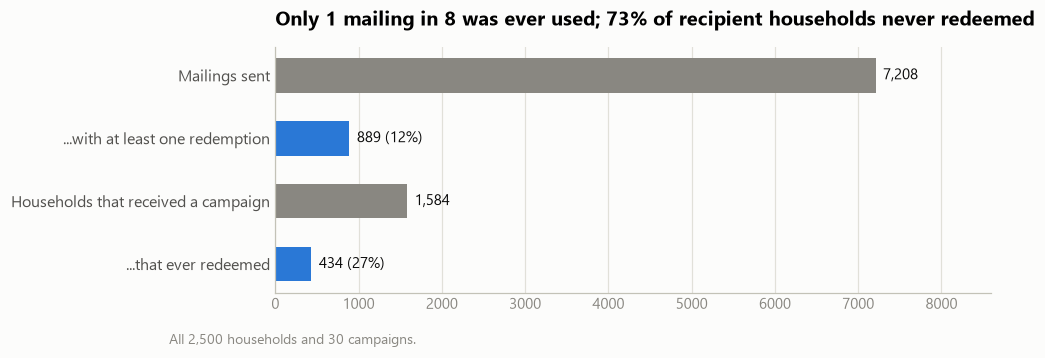

Households accounting for half of all redemptions: 70, i.e. 4.4% of recipient households


,mailings,mailings_redeemed,redemptions,mailing_redemption_rate
description,,,,
TypeA,3979,635,"1,791.000",0.160
TypeB,2655,210,454.000,0.079
TypeC,574,44,73.000,0.077


In [26]:
# One mailing = one household receiving one campaign. Did the mailing lead to at least one redemption?
mail = ctab.merge(camp[["campaign", "start_day", "end_day"]], on="campaign")
per_mail = red.groupby(["household_key", "campaign"]).size().rename("n_red").reset_index()
mail = mail.merge(per_mail, on=["household_key", "campaign"], how="left").fillna({"n_red": 0})

n_mail = len(mail)
n_mail_red = int((mail.n_red > 0).sum())
n_recipients = mail.household_key.nunique()
n_redeemers = red.household_key.nunique()

funnel_type = mail.groupby("description").agg(mailings=("campaign", "size"), mailings_redeemed=("n_red", lambda s: int((s > 0).sum())),
                                              redemptions=("n_red", "sum"))
funnel_type["mailing_redemption_rate"] = funnel_type.mailings_redeemed / funnel_type.mailings

# How concentrated are redemptions?
per_hh = red.groupby("household_key").size().sort_values(ascending=False)
cum_share = per_hh.cumsum() / per_hh.sum()
n_half = int((cum_share < 0.5).sum() + 1)          # households accounting for half of all redemptions

fig, ax = plt.subplots(figsize=(8.4, 2.9))
labels = ["Mailings sent", "...with at least one redemption", "Households that received a campaign", "...that ever redeemed"]
vals = [n_mail, n_mail_red, n_recipients, n_redeemers]
colors = [C_MUTED, C_BLUE, C_MUTED, C_BLUE]
bars = ax.barh(labels, vals, color=colors, height=0.55)
ax.invert_yaxis()
for b, v, extra in zip(bars, vals, ["", f"({n_mail_red / n_mail:.0%})", "", f"({n_redeemers / n_recipients:.0%})"]):
    ax.text(v + 90, b.get_y() + b.get_height() / 2, f"{v:,} {extra}", va="center", fontsize=10, color=C_INK)
ax.set_xlim(0, 8600)
ax.grid(axis="x", color=C_GRID)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=10.5, labelcolor=C_INK2)
ax.set_title(f"Only 1 mailing in 8 was ever used; {1 - n_redeemers / n_recipients:.0%} of recipient households never redeemed")
finish(fig, "09_funnel", "All 2,500 households and 30 campaigns.")

RESULTS["funnel"] = dict(mailings=n_mail, mailings_redeemed=n_mail_red, mailing_rate=n_mail_red / n_mail,
                         recipients=int(n_recipients), redeemers=int(n_redeemers),
                         share_never_redeemed=1 - n_redeemers / n_recipients, redemptions=int(len(red)),
                         n_half=n_half, n_half_share=n_half / n_recipients,
                         top10pct_share=float(cum_share.iloc[int(np.ceil(0.1 * len(per_hh))) - 1]),
                         by_type=funnel_type.reset_index().to_dict("records"))
print(f"Households accounting for half of all redemptions: {n_half}, i.e. {n_half / n_recipients:.1%} of recipient households")
funnel_type

**Reading the chart.**

- 7,208 mailings went out over two years. Only 889 of them (12%) led to at least one redemption.
- Of the 1,584 recipient households, 1,150 (73%) never redeemed a single campaign coupon.
- Redemption is highly concentrated: 70 households (4% of recipients) account for half of all redemptions.

### 9.2 Who uses the coupons

Split recipient households into five groups by their spending before any campaign (weeks 17–32) and look at redemption in each group.

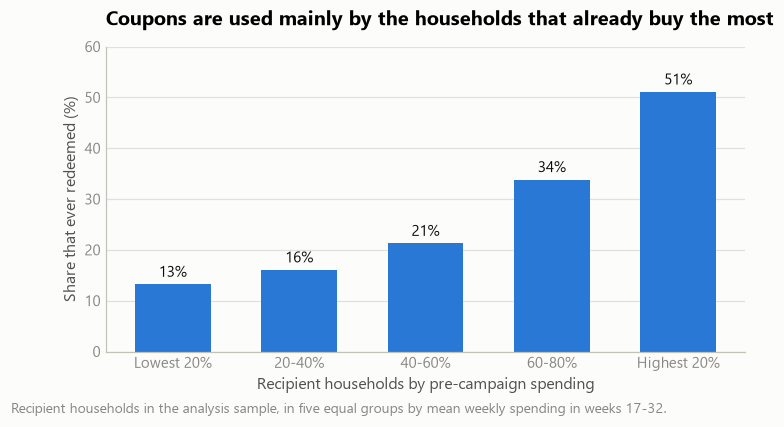

,households,pre_campaign_weekly_spend,campaigns_received
Never received a campaign,832,10.000,0.000
Received and redeemed,389,65.300,6.500
"Received, never redeemed",1048,37.900,3.900


In [27]:
pre_spend = SPEND.loc[:, 17:32].mean(axis=1)                 # weekly spending before any campaign (analysis sample)
rec = S[S.ever_treated == 1].copy()
rec["pre_spend"] = pre_spend.reindex(rec.index)
rec["quintile"] = pd.qcut(rec.pre_spend, 5, labels=["Lowest 20%", "20-40%", "40-60%", "60-80%", "Highest 20%"])
by_q = rec.groupby("quintile", observed=True).agg(households=("pre_spend", "size"), pre_spend=("pre_spend", "mean"),
                                                  redeem_share=("ever_redeemed", "mean"),
                                                  redemptions_per_household=("n_redemptions", "mean"))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.bar(by_q.index.astype(str), by_q.redeem_share * 100, width=0.6, color=C_BLUE)
for b, v in zip(bars, by_q.redeem_share):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=10, color=C_INK)
ax.set_ylim(0, 60)
ax.set_xlabel("Recipient households by pre-campaign spending")
ax.set_ylabel("Share that ever redeemed (%)")
ax.set_title("Coupons are used mainly by the households that already buy the most")
finish(fig, "10_who_redeems", "Recipient households in the analysis sample, in five equal groups by mean weekly spending in weeks 17-32.")

grp = pd.Series(np.where(S.ever_treated == 0, "Never received a campaign",
                         np.where(S.ever_redeemed == 1, "Received and redeemed", "Received, never redeemed")), index=S.index)
who = pd.DataFrame({"households": grp.value_counts(), "pre_campaign_weekly_spend": pre_spend.groupby(grp).mean(),
                    "campaigns_received": S.n_campaigns.groupby(grp).mean()})
RESULTS["who_redeems"] = dict(by_quintile=by_q.reset_index().astype({"quintile": str}).to_dict("records"),
                              groups=who.reset_index().rename(columns={"index": "group"}).to_dict("records"))
who.round(1)

**Reading the chart.** Half of the households in the top spending group redeemed at least once, against only 13% in the bottom group. Households that redeemed were already spending about \$65 a week before any campaign, 1.7 times as much as recipients that never redeemed.

The retailer sent coupons to its best customers, and the best of those are the ones using them. That alone does not show the coupons fail, but it does mean that **the people using coupons are exactly the people who least need a coupon to come in.**

### 9.3 What the coupons were used on

This is the most direct evidence on "new sales or subsidy". We match each redemption record back to the transaction lines of that day to find the redeemed product, and then ask whether the household had bought it in the **26 weeks before the campaign started**:

| Category | Meaning | Looks more like |
|---|---|---|
| Same product bought before | Bought the identical product in the previous six months | Subsidy: they buy it anyway |
| Same sub-category bought before | Not this product, but another in the same sub-category (say, a different brand of yogurt) | Mostly subsidy: a brand switch within a category is not new business for the store |
| Same category only | Only bought another sub-category of the same category | Partly trying something new |
| New category | Had not bought from this category in six months | Trial: the most likely to be incremental |

As a benchmark, we classify in the same way **the products the same households bought without a coupon during the same campaign period**. If coupons really nudged people toward new things, the "new" share among redeemed items should be higher than among ordinary purchases.

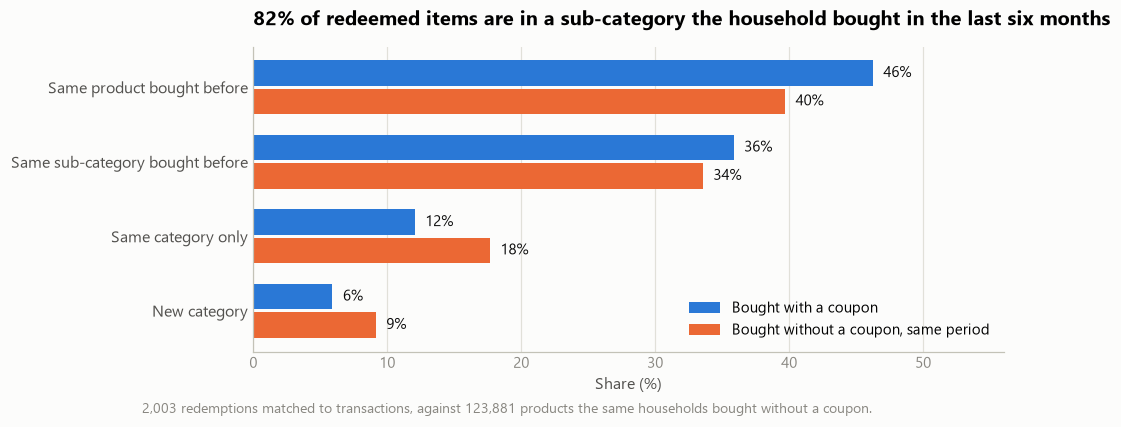

Share of redemptions matched to a transaction line: 86.4%
Most redeemed categories: Ice Cream/Milk/Sherbts, Cold Cereal, Frzn Meat/Meat Dinners, Cheese, Frozen Pizza, Fluid Milk Products


,redeemed_items,ordinary_purchases
habit,,
Same product bought before,0.462,0.397
Same sub-category bought before,0.358,0.335
Same category only,0.120,0.176
New category,0.059,0.091


In [28]:
LOOKBACK = 182          # look back 26 weeks

prod["cat"] = prod.commodity_desc.astype(str)                                                     # category
prod["subcat"] = prod.commodity_desc.astype(str) + " | " + prod.sub_commodity_desc.astype(str)    # sub-category
tx_all = read_raw("transaction_data").merge(prod[["product_id", "cat", "subcat"]], on="product_id", how="left")

# Step 1: match redemptions to transaction lines: same household, same day, product covered by that coupon
r = red.reset_index().rename(columns={"index": "red_id"})
cand = (r.merge(coup, on=["coupon_upc", "campaign"])
         .merge(tx_all[["household_key", "day", "product_id", "basket_id", "sales_value", "coupon_disc", "coupon_match_disc", "cat", "subcat"]],
                on=["household_key", "day", "product_id"]))
cand["has_disc"] = (cand.coupon_disc < 0) | (cand.coupon_match_disc < 0)
# A redemption can match several product lines: prefer the line that carries a coupon discount
matched = (cand.sort_values(["red_id", "has_disc", "sales_value"], ascending=[True, False, False])
               .groupby("red_id").head(1)
               .merge(camp[["campaign", "start_day", "end_day", "description"]], on="campaign"))
match_rate = matched.red_id.nunique() / len(r)

# Step 2: had the household bought it in the 26 weeks before the campaign started?
hist = tx_all[tx_all.household_key.isin(matched.household_key.unique())][["household_key", "day", "product_id", "cat", "subcat"]]


def bought_before(items, key):
    """For each row of items: did the household buy the same `key` in [start_day - 182, start_day)?"""
    h = hist[["household_key", "day", key]].drop_duplicates()
    m = items[["row", "household_key", "start_day", key]].merge(h, on=["household_key", key])
    ok = m[(m.day < m.start_day) & (m.day >= m.start_day - LOOKBACK)].row.unique()
    return items.row.isin(ok).values


ORDER = ["Same product bought before", "Same sub-category bought before", "Same category only", "New category"]


def classify(items):
    items = items.copy()
    items["row"] = np.arange(len(items))
    b_prod, b_sub, b_cat = (bought_before(items, k) for k in ["product_id", "subcat", "cat"])
    items["habit"] = np.select([b_prod, b_sub, b_cat], ORDER[:3], default=ORDER[3])
    return items


matched = classify(matched)

# Step 3: benchmark = products the same households bought without a campaign coupon in the same campaign period
pairs = matched[["household_key", "campaign", "start_day", "end_day"]].drop_duplicates()
ordinary = tx_all.merge(pairs, on="household_key")
ordinary = ordinary[(ordinary.day >= ordinary.start_day) & (ordinary.day <= ordinary.end_day) & (ordinary.sales_value > 0)]
used = set(zip(matched.household_key, matched.day, matched.product_id))
ordinary = ordinary[[k not in used for k in zip(ordinary.household_key, ordinary.day, ordinary.product_id)]]
ordinary = classify(ordinary.drop_duplicates(["household_key", "campaign", "product_id"]))

habit = pd.DataFrame({"redeemed_items": matched.habit.value_counts(normalize=True).reindex(ORDER),
                      "ordinary_purchases": ordinary.habit.value_counts(normalize=True).reindex(ORDER)})

fig, ax = plt.subplots(figsize=(8.8, 3.6))
y = np.arange(len(ORDER))
for j, (col, color, lab) in enumerate([("redeemed_items", C_BLUE, "Bought with a coupon"), ("ordinary_purchases", C_ORANGE, "Bought without a coupon, same period")]):
    bars = ax.barh(y + (j - 0.5) * 0.38, habit[col] * 100, height=0.34, color=color, label=lab)
    for b, v in zip(bars, habit[col]):
        ax.text(v * 100 + 0.8, b.get_y() + b.get_height() / 2, f"{v:.0%}", va="center", fontsize=10, color=C_INK)
ax.set_yticks(y)
ax.set_yticklabels(ORDER, fontsize=10.5, color=C_INK2)
ax.invert_yaxis()
ax.set_xlim(0, 56)
ax.set_xlabel("Share (%)")
ax.grid(axis="x", color=C_GRID)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
same_sub = habit.loc[ORDER[:2], "redeemed_items"].sum()
ax.set_title(f"{same_sub:.0%} of redeemed items are in a sub-category the household bought in the last six months")
finish(fig, "11_habit", f"{matched.red_id.nunique():,} redemptions matched to transactions, against {len(ordinary):,} products the same households bought without a coupon.")

RESULTS["habit"] = dict(match_rate=match_rate, n_matched=int(matched.red_id.nunique()), n_ordinary=int(len(ordinary)), order=ORDER,
                        redeemed=habit["redeemed_items"].to_dict(), ordinary=habit["ordinary_purchases"].to_dict(),
                        same_subcat_redeemed=float(same_sub), same_subcat_ordinary=float(habit.loc[ORDER[:2], "ordinary_purchases"].sum()),
                        top_categories=matched.cat.value_counts().head(10).to_dict())
print(f"Share of redemptions matched to a transaction line: {match_rate:.1%}")
print("Most redeemed categories:", ", ".join(matched.cat.value_counts().head(6).index.str.title()))
habit.round(3)

**Reading the chart.**

- 46% of redeemed items are the **identical product** the household had bought in the previous six months, and another 36% are in a sub-category it had bought. Together that is **82%**.
- Only 6% went on a category the household had not bought from in six months.
- **Compared with ordinary purchases, what people buy with coupons is more familiar, not less.** Among the same households' ordinary purchases in the same period, new categories make up 9% and bought-before sub-categories 73%. Coupons did not steer people toward new things. They were used on the most familiar products.

The most redeemed categories are ice cream, cold cereal, frozen meat, cheese, frozen pizza and milk: things households buy again and again.

### 9.4 How large are the discounts

In [29]:
matched["disc"] = -(matched.coupon_disc + matched.coupon_match_disc)       # discount per redemption
disc_recorded = matched[matched.has_disc]

# Total spending of recipient households inside their own campaign periods
# (a transaction can fall inside several campaign periods, so de-duplicate first)
spend_in = tx_all.reset_index().merge(mail[["household_key", "start_day", "end_day"]], on="household_key")
spend_in = spend_in[(spend_in.day >= spend_in.start_day) & (spend_in.day <= spend_in.end_day)]
recipient_spend = spend_in.drop_duplicates("index").sales_value.sum()

# Total discount: redemptions without a matched line or a recorded discount get the mean recorded
# discount, which gives an estimate on the high side
total_disc = len(red) * disc_recorded.disc.mean()
# Upper bound on directly generated spending: assume every redeemed item was purely incremental
max_direct = len(red) * matched.sales_value.mean()

# Basket value of trips with a redemption vs the same household's other trips in the campaign period
baskets = tx_all.groupby(["household_key", "basket_id", "day"]).sales_value.sum().reset_index()
baskets = baskets.merge(mail[["household_key", "start_day", "end_day"]], on="household_key")
baskets = baskets[(baskets.day >= baskets.start_day) & (baskets.day <= baskets.end_day)].drop_duplicates(["household_key", "basket_id"])
baskets["with_coupon"] = baskets.basket_id.isin(matched.basket_id.unique())
cmp = baskets[baskets.household_key.isin(matched.household_key.unique())].groupby(["household_key", "with_coupon"]).sales_value.mean().unstack().dropna()

RESULTS["discount"] = dict(mean_disc=float(disc_recorded.disc.mean()), mean_item_sales=float(matched.sales_value.mean()),
                           total_disc=float(total_disc), recipient_spend=float(recipient_spend),
                           disc_share=float(total_disc / recipient_spend),
                           max_direct=float(max_direct), max_direct_share=float(max_direct / recipient_spend),
                           basket_with=float(cmp[True].mean()), basket_without=float(cmp[False].mean()), basket_n=int(len(cmp)))
print(f"Mean discount per redemption: ${disc_recorded.disc.mean():.2f}; mean sales value of a redeemed item: ${matched.sales_value.mean():.2f}")
print(f"Total campaign-coupon discount over two years (high-side estimate): ${total_disc:,.0f}")
print(f"Total spending of recipient households during their campaign periods: ${recipient_spend:,.0f}")
print(f"Discount as a share of that spending: {total_disc / recipient_spend:.2%}")
print(f"Even if every redeemed item were purely incremental, that is only {max_direct / recipient_spend:.2%} of that spending")
print(f"Trips with a redemption average ${cmp[True].mean():.0f}; the same households' other trips average ${cmp[False].mean():.0f} ({len(cmp)} households)")

Mean discount per redemption: $1.14; mean sales value of a redeemed item: $4.02
Total campaign-coupon discount over two years (high-side estimate): $2,642
Total spending of recipient households during their campaign periods: $2,424,728
Discount as a share of that spending: 0.11%
Even if every redeemed item were purely incremental, that is only 0.38% of that spending
Trips with a redemption average $90; the same households' other trips average $38 (408 households)


**Reading the numbers.**

- A redemption takes a little over \$1 off, and the redeemed item sells for about \$4 on average.
- Total campaign-coupon discounts over two years come to two to three thousand dollars, about **0.1%** of what recipient households spent in the same periods.
- **An upper bound:** even assuming every redeemed item was a pure "would not have bought it without the coupon" purchase, the spending directly generated is only about **0.4%** of recipients' spending in the same periods. That is an order of magnitude below the smallest effect Section 7 could detect.
- A trip on which a coupon is used averages about \$90, more than twice the same household's other trips. Coupons get used up on the big stock-up trip.

**Summary.** Through the direct channel of redemption, the coupons can have moved total spending by a few tenths of a percent at most. For a campaign to produce a sizeable lift it would have to work indirectly: receiving the coupons reminds the customer to come in, even if no coupon is used in the end. Section 7 found no rise in visits or spending. Section 10 tests the idea again with a more sensitive measure.

## 10. Mechanism 2: did recipients buy more of the promoted products

### 10.1 The idea

If the coupons (even unredeemed ones) made people buy more of the promoted products, then **the share of recipients' spending that goes to promoted products** should rise.

This measure is far more sensitive than total spending. Whether a household buys more or less in a given week moves promoted and other products alike, and taking a share cancels that overall swing. The regression-to-the-mean problem that dogged Section 7 largely disappears here.

The comparison is a triple difference:

$$\underbrace{\big(s^{\text{recipients}}_{\text{campaign}} - s^{\text{recipients}}_{\text{before}}\big)}_{\text{change in recipients' share}} - \underbrace{\big(s^{\text{others}}_{\text{campaign}} - s^{\text{others}}_{\text{before}}\big)}_{\text{change in the share of households not sent this campaign}}$$

where $s$ is spending on promoted products as a share of total spending. Subtracting the change among other households removes the seasonality and in-store promotion of those products.

Here we can use **all recipients of all campaigns**, not just first-time recipients, so the sample is much larger. We keep campaigns with at least 40 recipient households.

In [30]:
# Products covered by each campaign ("promoted products"), and each household's weekly spending on them
coup_prod = coup[["product_id", "campaign"]].drop_duplicates()
tx_s = tx[tx.household_key.isin(IDS)][["household_key", "week_no", "product_id", "sales_value"]]
elig_long = tx_s.merge(coup_prod, on="product_id").groupby(["campaign", "household_key", "week_no"]).sales_value.sum()
ELIG = {c: elig_long.xs(c).unstack("week_no").reindex(index=IDS, columns=WEEKS).fillna(0.0).values for c in camp.campaign}
Y_ALL = SPEND.values                                    # household x week; column 0 is week 1
pos = pd.Series(np.arange(len(IDS)), index=IDS)

KS = np.arange(-16, 13)
PRE = (KS >= -8) & (KS <= -1)                           # the 8 weeks before the campaign are the baseline
DURING = (KS >= 0) & (KS <= 6)
AFTER = (KS >= 7) & (KS <= 12)


def usable(c, min_n=40):
    """The campaign's before/after windows lie inside the data and it has enough recipients in the sample."""
    r_ = camp[camp.campaign == c].iloc[0]
    n = len(members[c] & set(IDS))
    return r_.start_week - 16 >= 17 and r_.start_week + 12 <= 101 and n >= min_n


def share_ddd(camps, counts=None):
    """Triple difference in the promoted-product share for a set of campaigns, by event week."""
    w = np.ones(len(IDS)) if counts is None else counts
    num, den, levels = np.zeros(len(KS)), 0.0, []
    for c in camps:
        start = int(camp[camp.campaign == c].start_week.iloc[0])
        got = np.zeros(len(IDS), bool)
        got[pos[list(members[c] & set(IDS))].values] = True
        wr, wn = w * got, w * (~got)
        cols = start + KS - 1
        s_r = (wr @ ELIG[c][:, cols]) / (wr @ Y_ALL[:, cols])       # recipients: promoted share
        s_n = (wn @ ELIG[c][:, cols]) / (wn @ Y_ALL[:, cols])       # households not sent this campaign
        d = (s_r - s_r[PRE].mean()) - (s_n - s_n[PRE].mean())
        n = wr.sum()
        num += n * d
        den += n
        levels.append(dict(campaign=c, recipients=n, rec_before=s_r[PRE].mean(), rec_during=s_r[DURING].mean(),
                           oth_before=s_n[PRE].mean(), oth_during=s_n[DURING].mean(),
                           rec_weekly_spend=(wr @ Y_ALL[:, cols]).mean() / n))
    return num / den, levels


rng = np.random.default_rng(SEED)
groups = {"TypeA (personalized coupons)": [c for c in TYPE_A if usable(c)],
          "TypeB / TypeC (same coupons for all)": [c for c in camp.campaign if c not in TYPE_A and usable(c)]}
share_rows, share_out = [], {}
for name, cs in groups.items():
    d, lv = share_ddd(cs)
    draws = np.array([share_ddd(cs, rng.multinomial(len(IDS), np.ones(len(IDS)) / len(IDS)).astype(float))[0] for _ in range(500)])
    lv = pd.DataFrame(lv)
    wavg = lambda col: float(np.average(lv[col], weights=lv.recipients))
    spend_wk = wavg("rec_weekly_spend")
    for key, wn, m in [("check", "Weeks -16 to -9 (check)", (KS >= -16) & (KS <= -9)), ("during", "During campaign", DURING), ("after", "After campaign", AFTER)]:
        x = draws[:, m].mean(1)
        share_rows.append(dict(campaign_type=name, window=wn, window_key=key, change_pp=100 * d[m].mean(),
                               lo=100 * np.percentile(x, 2.5), hi=100 * np.percentile(x, 97.5),
                               usd_per_week=d[m].mean() * spend_wk, usd_hi=np.percentile(x, 97.5) * spend_wk))
    share_out[name] = dict(n_campaigns=len(cs), n_mailings=float(lv.recipients.sum()), spend_per_week=spend_wk,
                           recipients_pre=wavg("rec_before"), recipients_during=wavg("rec_during"),
                           others_pre=wavg("oth_before"), others_during=wavg("oth_during"),
                           ks=KS.tolist(), ddd=(100 * d).tolist(),
                           lo=(100 * np.percentile(draws, 2.5, axis=0)).tolist(), hi=(100 * np.percentile(draws, 97.5, axis=0)).tolist())
share_table = pd.DataFrame(share_rows)
share_table.to_csv(TAB / "product_share_ddd.csv", index=False)
RESULTS["product_share"] = dict(groups=share_out, windows=share_table.to_dict("records"))

for name, o in share_out.items():
    print(f"{name}: {o['n_campaigns']} campaigns, {o['n_mailings']:.0f} mailings. Promoted products as a share of spending: "
          f"recipients {o['recipients_pre']:.2%} -> {o['recipients_during']:.2%}; others {o['others_pre']:.2%} -> {o['others_during']:.2%}")
share_table.drop(columns="window_key").round(3)

TypeA (personalized coupons): 5 campaigns, 3675 mailings. Promoted products as a share of spending: recipients 35.63% -> 35.54%; others 36.99% -> 36.77%
TypeB / TypeC (same coupons for all): 15 campaigns, 2113 mailings. Promoted products as a share of spending: recipients 1.14% -> 1.19%; others 0.58% -> 0.60%


,campaign_type,window,change_pp,lo,hi,usd_per_week,usd_hi
0,TypeA (personalized coupons),Weeks -16 to -9 (check),0.085,-0.483,0.713,0.048,0.402
1,TypeA (personalized coupons),During campaign,0.124,-0.477,0.699,0.070,0.394
2,TypeA (personalized coupons),After campaign,-0.565,-1.103,0.025,-0.318,0.014
3,TypeB / TypeC (same coupons for all),Weeks -16 to -9 (check),0.172,0.095,0.256,0.135,0.201
4,TypeB / TypeC (same coupons for all),During campaign,0.031,-0.058,0.113,0.024,0.088
5,TypeB / TypeC (same coupons for all),After campaign,-0.112,-0.231,-0.008,-0.088,-0.006


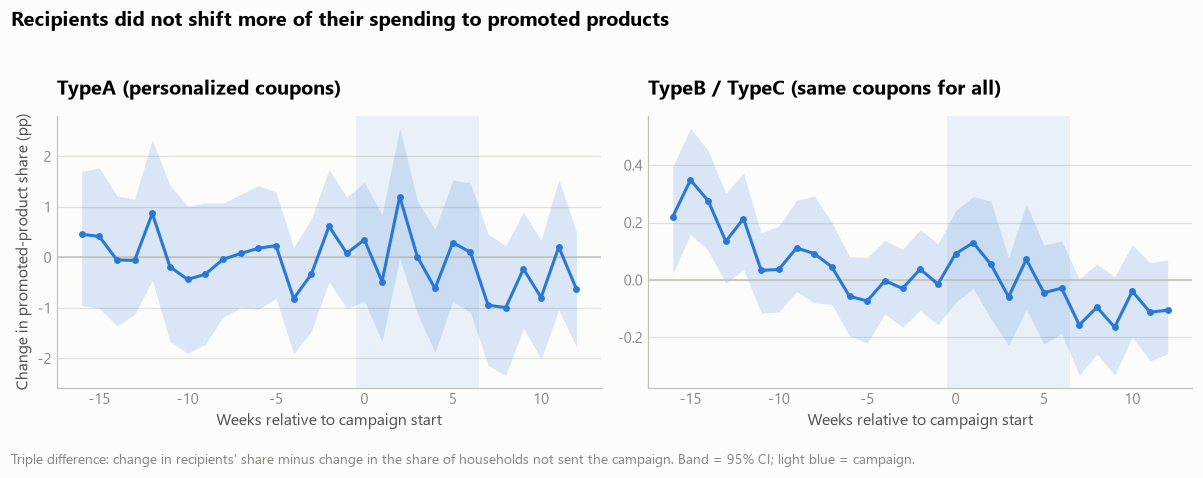

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, (name, o) in zip(axes, share_out.items()):
    ax.axvspan(-0.5, 6.5, color=C_BLUE, alpha=0.09, lw=0)
    ax.axhline(0, color=C_AXIS, lw=1)
    ax.fill_between(o["ks"], o["lo"], o["hi"], color=C_BLUE, alpha=0.16, lw=0)
    ax.plot(o["ks"], o["ddd"], color=C_BLUE, marker="o", ms=3.5)
    ax.set_xlabel("Weeks relative to campaign start")
    ax.set_title(name, fontsize=11.5)
axes[0].set_ylabel("Change in promoted-product share (pp)")
fig.suptitle("Recipients did not shift more of their spending to promoted products", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
finish(fig, "12_product_share", "Triple difference: change in recipients' share minus change in the share of households not sent the campaign. Band = 95% CI; light blue = campaign.")

**Reading the chart and table.**

- **TypeA campaigns:** promoted products make up about 36% of recipients' spending, and that barely moves during the campaign. The triple difference is about +0.1 percentage points, with a confidence interval whose upper end is below 1 point. In money, the upper end is about \$0.40 a week, under 1% of what these households spend.
- **TypeB / TypeC campaigns:** these coupons cover few products, only about 1% of spending, and the share does not move during the campaign either.
- **The TypeA comparison is clean:** the difference in weeks −16 to −9 is close to zero (the "check" row).
- **The TypeB / TypeC comparison is less clean:** in weeks −16 to −9, recipients' promoted-product share is about 0.17 points above its baseline level, and significantly so. These households were picked when they happened to be buying more of those products, and they then drifted back: regression to the mean once again. The difference during the campaign is still close to zero.
- **The share dips slightly after the campaign.** That looks like a continuation of regression to the mean, not stockpiling: the share did not rise first during the campaign.
- One more observation: before the campaign, TypeB/C recipients already spend twice as large a share on the promoted products as other households do. The retailer sends coupons for a product group to people who already like buying it.

**This section tightens the conclusion.** Section 7 could only say the effect on total spending lies between −8% and +11%. Here we can say: **the share of recipients' spending going to promoted products rose by less than 1 percentage point at most.** The coupons did not change what they buy.

## 11. Heterogeneity, and a tempting mistake

### 11.1 Do frequent and infrequent shoppers differ

Split each treated cohort at the median of its number of trips in the baseline window and estimate each half separately.

In [32]:
freq_ids, infreq_ids = [], []
for g in COHORTS:
    ids = cohort.index[cohort == g]
    trips_base = TRIPS.loc[ids, g - 16:g - 9].mean(axis=1)          # mean weekly trips in the baseline window
    med = trips_base.median()
    freq_ids += list(trips_base.index[trips_base > med])
    infreq_ids += list(trips_base.index[trips_base <= med])

het_rows = []


def add_het(key, label, subset, note=""):
    st = prepare(SPEND, cohort, COHORTS, treated_subset=pd.Index(subset))
    r_ = estimate(st, "dr", boot=BOOT)
    b0 = base_level(st)
    row = dict(key=key, group=label, households=int(sum(s["d"].sum() for s in st)), baseline_weekly_spend=b0, note=note)
    for wn, (a, b) in WINDOWS.items():
        e = window_effect(r_, a, b)
        row[wn] = e["est"]
        row[wn + "_lo"] = e["lo"]
        row[wn + "_hi"] = e["hi"]
    het_rows.append(row)


add_het("frequent", "Frequent shoppers (baseline trips above the median)", freq_ids)
add_het("infrequent", "Less frequent shoppers (at or below the median)", infreq_ids)
add_het("redeemers", "Households that later redeemed", S.index[S.ever_redeemed == 1], "split on post-campaign behavior; not a causal comparison")
add_het("non_redeemers", "Households that never redeemed", S.index[S.ever_redeemed == 0], "split on post-campaign behavior; not a causal comparison")
het = pd.DataFrame(het_rows)
het.to_csv(TAB / "heterogeneity.csv", index=False)
RESULTS["heterogeneity"] = het.to_dict("records")

print("Effects in $ per week, with 95% confidence intervals")
cols = ["group", "households", "baseline_weekly_spend"] + [c for wn in WINDOWS for c in (wn, wn + "_lo", wn + "_hi")]
het[cols].round(2)

Effects in $ per week, with 95% confidence intervals


,group,households,baseline_weekly_spend,holdout,holdout_lo,holdout_hi,during,during_lo,during_hi,after,after_lo,after_hi
0,Frequent shoppers (baseline trips above the me...,481,65.120,2.270,-12.380,14.710,3.220,-7.390,14.640,2.700,-9.780,14.510
1,Less frequent shoppers (at or below the median),552,29.820,-0.740,-4.330,3.350,-2.820,-6.650,2.280,-5.040,-8.840,0.610
2,Households that later redeemed,266,62.570,7.520,0.080,15.820,7.770,-0.170,17.480,5.620,-3.450,15.370
3,Households that never redeemed,767,40.600,-0.980,-4.300,3.370,-1.880,-5.760,2.840,-2.940,-6.800,1.630


**Reading the table (first two rows).**

- **Less frequent shoppers (552 households, about \$30 a week at baseline):** the effect during the campaign is about −\$2.8, with a confidence interval of roughly −\$6.7 to +\$2.3. It includes zero.
- **Frequent shoppers (481 households, about \$65 a week at baseline):** the effect is about +\$3.2, but the confidence interval runs from −\$7 to +\$15. That is too wide to be informative. The reason is the one from Section 7.1: by the time a campaign starts, nearly all of the most frequent shoppers have already been selected, and there are not enough equally active households without coupons to compare them with.

**Conclusion: there is no evidence that either kind of customer responds to the coupons.** For frequent shoppers, this data cannot give a meaningful estimate.

### 11.2 A tempting mistake: comparing people who used a coupon with people who did not

Many marketing analyses do this: split recipients into those who redeemed and those who did not, find that the redeemers spend more, and report that customers who used coupons spent more.

The last two rows of the table do exactly that. It looks as if households that redeemed spend about \$8 a week more than the controls during the campaign. **But look at the check-window column: in the 8 weeks before the campaign started, they were already spending about \$7.5 more.**

That is not an effect of the coupons. The households that go on to use a coupon are the ones whose buying was already on the way up at the time. Whether to redeem is a choice the household makes after the campaign starts; splitting on it treats an outcome as a cause.

This is why the treatment in this project is "received a campaign" and not "redeemed a coupon".

### 11.3 Heterogeneity with a causal forest (Week 7)

Splitting the sample in two, as in 11.1, is a blunt way to look for heterogeneous treatment effects. The causal forest fitted in Section 8.4 gives a conditional average treatment effect (CATE) for every treated household. We summarize those by how often the household shopped at baseline.

Section 8.1 gave a reason to look: the ANCOVA test rejected "no treatment × covariate interaction", so some variation with the covariates is present.

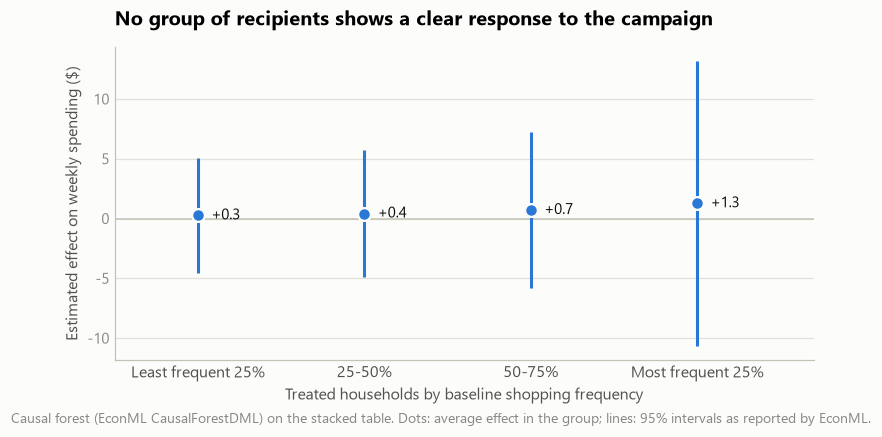

Household-level effects: mean +0.66, standard deviation 3.47 $/week; 66% are positive.


,tier,households,baseline_trips_per_week,baseline_spend,cate,lo,hi,cate_pct
0,Least frequent 25%,259,0.470,20.580,0.260,-4.530,5.050,1.260
1,25-50%,258,1.020,35.700,0.420,-4.890,5.720,1.160
2,50-75%,258,1.610,47.040,0.710,-5.790,7.200,1.500
3,Most frequent 25%,258,3.550,81.800,1.270,-10.640,13.180,1.550


In [33]:
forest = CF_MODELS["y_during"]
treated_rows = STK[Tv == 1].copy()
treated_rows["cate"] = forest.effect(Xs_all[Tv == 1])
treated_rows["tier"] = pd.qcut(treated_rows.trips_base.rank(method="first"), 4, labels=["Least frequent 25%", "25-50%", "50-75%", "Most frequent 25%"])

cate_rows = []
for tier, idx in treated_rows.groupby("tier", observed=True).groups.items():
    Xg = Xs_all[idx]
    lo, hi = forest.ate_interval(Xg)
    sub = treated_rows.loc[idx]
    cate_rows.append(dict(tier=str(tier), households=len(sub), baseline_trips_per_week=sub.trips_base.mean(), baseline_spend=sub.y_base.mean(),
                          cate=float(forest.ate(Xg)), lo=float(lo), hi=float(hi)))
cate = pd.DataFrame(cate_rows)
cate["cate_pct"] = 100 * cate.cate / cate.baseline_spend

fig, ax = plt.subplots(figsize=(8.2, 3.7))
x = np.arange(len(cate))
ax.axhline(0, color=C_AXIS, lw=1)
ax.vlines(x, cate.lo, cate.hi, color=C_BLUE, lw=2)
ax.scatter(x, cate.cate, s=70, color=C_BLUE, zorder=3, edgecolor=C_SURF, linewidth=1.5)
for i, r_ in cate.iterrows():
    ax.text(i + 0.08, r_.cate, f"{r_.cate:+.1f}", va="center", fontsize=10, color=C_INK)
ax.set_xticks(x)
ax.set_xticklabels(cate.tier, fontsize=10.5, color=C_INK2)
ax.set_xlim(-0.5, len(cate) - 0.3)
ax.set_xlabel("Treated households by baseline shopping frequency")
ax.set_ylabel("Estimated effect on weekly spending ($)")
ax.set_title("No group of recipients shows a clear response to the campaign")
finish(fig, "11b_cate", "Causal forest (EconML CausalForestDML) on the stacked table. Dots: average effect in the group; lines: 95% intervals as reported by EconML.")

RESULTS["cate"] = dict(table=cate.to_dict("records"), sd_of_household_effects=float(treated_rows.cate.std()),
                       share_positive=float((treated_rows.cate > 0).mean()))
print(f"Household-level effects: mean {treated_rows.cate.mean():+.2f}, standard deviation {treated_rows.cate.std():.2f} $/week; {100 * (treated_rows.cate > 0).mean():.0f}% are positive.")
cate.round(2)

**Reading the chart.** The forest's estimates differ a little from group to group, but every interval includes zero, and the intervals overlap one another. The differences the ANCOVA F-test picked up are too small, or too scattered, to single out a type of household that responds. This agrees with 11.1.

The same caution applies as in Week 7's slide on causal forests: the forest assumes no unmeasured confounding and enough overlap. Overlap is weakest for the most frequent shoppers, which is where its estimate is least reliable.

## 12. Robustness checks

The main conclusion is: "the effect during the campaign is about +1%, with a confidence interval that includes zero." Below we change the approach in several ways and see whether that conclusion moves.

| Check | What changes | Why |
|---|---|---|
| Other estimators | Regression adjustment, entropy balancing | Does the conclusion depend on the adjustment method? |
| Add cohorts whose first campaign is TypeB | Treatment group grows from 5 cohorts to 9 | Does it only hold for TypeA? |
| Exclude fuel | Outcome drops gasoline transactions | Fuel is large and volatile; does it distort the result? |
| Early cohorts only | Keep the week 33, 47 and 60 cohorts | The last two cohorts are small with few controls; same answer without them? |
| Controls: later recipients only | Controls exclude never-treated households | A different source of controls |
| Controls: never-treated only | Controls exclude later recipients | Same |
| Longer follow-up | Track to week 24 after the start (only two cohorts are long enough) | Could the effect show up later? |
| No check window | Adjust on every week up to the campaign, holding nothing out | Section 5.3 found the retailer's information reaches into the check window |

In [34]:
rob = []


def add_rob(label, setups, method="dr", H_=H):
    r_ = estimate(setups, method, boot=BOOT, H=H_)
    b0 = base_level(setups)
    ess = r_["info"].control_ess.sum() if method in ("eb", "dr") else np.nan
    row = dict(check=label, treated=int(sum(s["d"].sum() for s in setups)), control_ess=ess, baseline_weekly_spend=b0)
    for wn, (a, b) in WINDOWS.items():
        e = window_effect(r_, a, b)
        row[wn] = 100 * e["est"] / b0            # effects in % of baseline spending
        row[wn + "_lo"] = 100 * e["lo"] / b0
        row[wn + "_hi"] = 100 * e["hi"] / b0
    rob.append(row)
    return r_


add_rob("Main specification (doubly robust)", main_setups)
add_rob("Estimator: regression adjustment", main_setups, "ra")
add_rob("Estimator: entropy balancing", main_setups, "eb")
add_rob("Add TypeB-first cohorts (9 cohorts)", prepare(SPEND, cohort, [33, 41, 47, 54, 55, 58, 60, 73, 85]))

fuel_products = prod[prod.department.isin(["KIOSK-GAS", "MISC SALES TRAN", "MISC. TRANS."])].product_id
fuel = tx[tx.product_id.isin(fuel_products)].groupby(["household_key", "week_no"]).sales_value.sum()
SPEND_NOFUEL = SPEND - fuel.unstack("week_no").reindex(index=IDS, columns=WEEKS).fillna(0.0)
add_rob("Outcome: spending excluding fuel", prepare(SPEND_NOFUEL, cohort, COHORTS))

add_rob("Early cohorts only (weeks 33, 47, 60)", prepare(SPEND, cohort, [33, 47, 60]))
later_ids = S.index[S.cohort > 0]
never_ids_s = S.index[S.cohort == 0]
add_rob("Controls: later recipients only (early cohorts)", prepare(SPEND, cohort, [33, 47, 60], control_subset=later_ids))
add_rob("Controls: never-treated only", prepare(SPEND, cohort, COHORTS, control_subset=never_ids_s))

# No check window: use every pre-campaign week for the adjustment (the baseline window becomes weeks -8 to -1).
# This gives up the placebo check in exchange for adjusting on the most recent information.
_holdout, HOLDOUT = HOLDOUT, 0
add_rob("No check window: adjust on all pre-campaign weeks", prepare(SPEND, cohort, COHORTS))
HOLDOUT = _holdout

robust = pd.DataFrame(rob)
robust.to_csv(TAB / "robustness.csv", index=False)

# Longer follow-up: 24 weeks. Only the week 33 and week 60 cohorts still have enough untreated households by then.
long_setups = prepare(SPEND, cohort, [33, 60], H=24)
r_long = estimate(long_setups, "dr", boot=BOOT, H=24)
b_long = base_level(long_setups)
long_rows = []
for wn, (a, b) in {"Check window (8 weeks before)": (-8, -1), "Weeks 0-6": (0, 6), "Weeks 7-12": (7, 12), "Weeks 13-24": (13, 24)}.items():
    e = window_effect(r_long, a, b)
    long_rows.append(dict(window=wn, effect_pct=100 * e["est"] / b_long, lo=100 * e["lo"] / b_long, hi=100 * e["hi"] / b_long))
long_table = pd.DataFrame(long_rows)

RESULTS["robustness"] = dict(table=robust.to_dict("records"), long_horizon=long_table.to_dict("records"),
                             fuel_share=float(1 - SPEND_NOFUEL.values.sum() / SPEND.values.sum()))
print("Effects in % of baseline weekly spending")
robust[["check", "treated", "control_ess", "holdout", "during", "during_lo", "during_hi", "after", "after_lo", "after_hi"]].round(1)

Effects in % of baseline weekly spending


,check,treated,control_ess,holdout,during,during_lo,during_hi,after,after_lo,after_hi
0,Main specification (doubly robust),1033,474.600,2.700,1.300,-7.600,11.300,-1.300,-10.200,8.800
1,Estimator: regression adjustment,1033,NaN,1.000,1.800,-5.000,10.600,-2.300,-10.200,6.500
2,Estimator: entropy balancing,1033,474.600,2.400,1.300,-7.100,11.100,-1.400,-10.000,8.200
3,Add TypeB-first cohorts (9 cohorts),1301,"1,347.100",1.100,0.800,-7.100,9.500,-1.800,-9.800,7.400
4,Outcome: spending excluding fuel,1033,474.600,2.600,0.800,-8.200,10.700,-1.100,-10.200,9.000
5,"Early cohorts only (weeks 33, 47, 60)",865,382.400,3.800,2.400,-7.100,12.800,-2.800,-12.900,7.800
6,Controls: later recipients only (early cohorts),865,287.600,0.600,-0.500,-10.100,11.400,-10.600,-20.600,0.400
7,Controls: never-treated only,1033,146.900,-1.300,-10.700,-184.500,145.600,7.900,-161.900,209.700
8,No check window: adjust on all pre-campaign weeks,1033,521.400,0.000,-0.900,-7.600,7.500,-4.200,-12.300,5.000


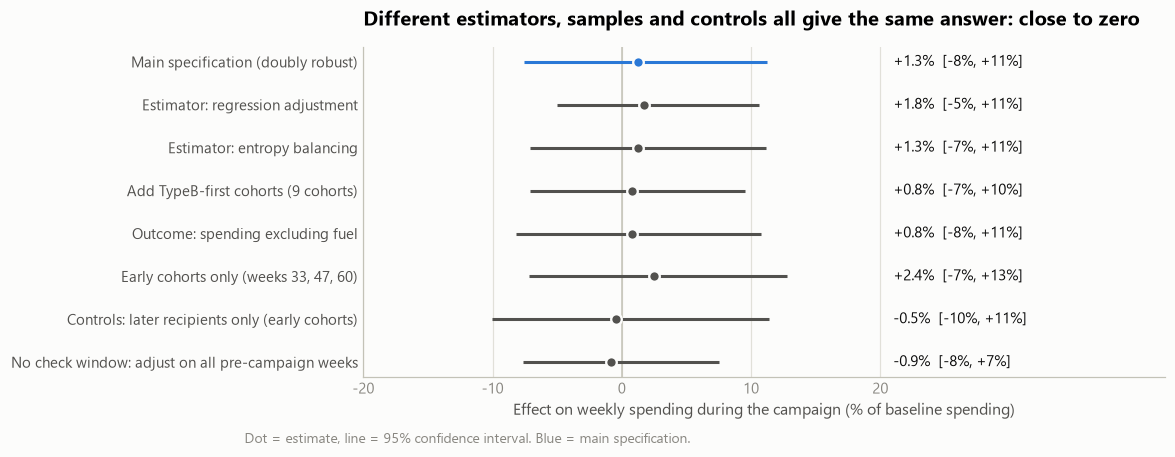

Longer follow-up (week 33 and week 60 cohorts), % of baseline weekly spending:


,window,effect_pct,lo,hi
0,Check window (8 weeks before),6.800,-4.800,16.600
1,Weeks 0-6,-2.400,-12.700,17.500
2,Weeks 7-12,2.000,-15.300,24.100
3,Weeks 13-24,-6.600,-21.800,12.300


In [35]:
# Forest plot: the effect during the campaign under each specification (% of baseline spending)
plot = robust[(robust.during_hi - robust.during_lo) < 60].reset_index(drop=True)   # specs with a meaninglessly wide interval are discussed in the text

fig, ax = plt.subplots(figsize=(9.4, 3.9))
y = np.arange(len(plot))
ax.axvline(0, color=C_AXIS, lw=1)
for i, r_ in plot.iterrows():
    color = C_BLUE if i == 0 else C_INK2
    ax.hlines(i, r_.during_lo, r_.during_hi, color=color, lw=2)
    ax.scatter(r_.during, i, color=color, s=48, zorder=3, edgecolor=C_SURF, linewidth=1.5)
    ax.text(21, i, f"{r_.during:+.1f}%  [{r_.during_lo:+.0f}%, {r_.during_hi:+.0f}%]", va="center", fontsize=9.5, color=C_INK)
ax.set_yticks(y)
ax.set_yticklabels(plot.check, fontsize=10, color=C_INK2)
ax.invert_yaxis()
ax.set_xlim(-20, 42)
ax.set_xticks([-20, -10, 0, 10, 20])
ax.set_xlabel("Effect on weekly spending during the campaign (% of baseline spending)")
ax.grid(axis="x", color=C_GRID)
ax.grid(axis="y", visible=False)
ax.set_title("Different estimators, samples and controls all give the same answer: close to zero")
finish(fig, "13_robustness", "Dot = estimate, line = 95% confidence interval. Blue = main specification.")

print("Longer follow-up (week 33 and week 60 cohorts), % of baseline weekly spending:")
long_table.round(1)

**Reading the chart and tables.**

- **Other estimators, adding TypeB-first cohorts, excluding fuel, early cohorts only:** the effect during the campaign is between 0 and +3% every time, and every confidence interval includes zero.
- **Controls drawn only from later recipients:** the effect during the campaign is again close to zero. But this specification gives about −11% after the campaign (the upper end of its interval is near zero). The reason is that these control households "get selected later" precisely because they buy a lot during this period, so the controls are being picked on a future outcome. That is why the main specification pools never-treated and later-treated households and only requires "no campaign by week $g+12$".
- **Controls drawn only from never-treated households: this does not work.** There are almost no heavy shoppers among them. After weighting, the effective sample size is only about 150 households and rests on a handful of them, and the confidence interval is too wide to mean anything. The forest plot leaves this row out; the table above keeps it. It shows that never-treated households cannot serve as the control group on their own.
- **No check window:** adjusting on every week up to the campaign, so that the information Section 5.3 found in the check window is used, gives an estimate at or slightly below the main one. The small upward bias flagged there does not hide an effect.
- **Longer follow-up:** tracking to week 24 after the start, no positive effect appears.

## 13. The experiment that would settle it

The confidence interval in Section 7 is −8% to +11%. Section 9 put the spending directly generated by redemptions at about 0.4% at most. **Even if coupons do have an effect of a few tenths of a percent, this data cannot show it.**

How large a sample would be needed? Suppose the retailer ran a standard randomized experiment: split the targeted households at random into two groups, send coupons to one and not to the other, and compare the change in spending during the campaign relative to baseline. We compute the households needed per group at a 5% significance level and 80% power.

In [36]:
# Standard deviation of each household's "7-week campaign mean - 8-week baseline mean", from the treated households
changes = pd.concat([SPEND.loc[cohort.index[cohort == g], g:g + 6].mean(axis=1) -
                     SPEND.loc[cohort.index[cohort == g], g - 16:g - 9].mean(axis=1) for g in COHORTS])
sd_change = changes.std()

power_rows = []
for pct in [0.5, 1, 2, 5, 10]:
    delta = BASE * pct / 100
    n_per_arm = 2 * ((1.96 + 0.84) * sd_change / delta) ** 2          # standard two-sample formula
    power_rows.append(dict(lift=f"{pct:g}%", usd_per_week=delta, households_per_group=int(round(n_per_arm))))
power = pd.DataFrame(power_rows)

se_main = RESULTS["main"]["windows"]["dr"]["during"]["se"]
mde = 2.8 * se_main
RESULTS["power"] = dict(sd_change=float(sd_change), table=power.to_dict("records"),
                        se_main=float(se_main), mde_dollars=float(mde), mde_pct=float(100 * mde / BASE))
print(f"Standard deviation of the household-level change in spending: ${sd_change:.1f} (baseline weekly spending ${BASE:.1f})")
print(f"Standard error of the main estimate ${se_main:.2f}; minimum detectable effect about ${mde:.1f}, i.e. {100 * mde / BASE:.0f}%")
power

Standard deviation of the household-level change in spending: $31.3 (baseline weekly spending $46.3)
Standard error of the main estimate $2.30; minimum detectable effect about $6.4, i.e. 14%


,lift,usd_per_week,households_per_group
0,0.5%,0.231,287221
1,1%,0.463,71805
2,2%,0.925,17951
3,5%,2.313,2872
4,10%,4.626,718


**Reading the table.**

- A household's weekly spending swings a lot: the change in the 7-week mean relative to baseline has a standard deviation of about \$31, against an average level of only \$46.
- Detecting a 1% lift needs about **72,000 households per group**; 5% needs about 3,000; 10% needs about 700.
- This study has 1,033 treated households, but the comparable controls have an effective sample size of only a few hundred, so the minimum detectable effect is about 14%.

**What this means for the retailer.** This chain certainly has far more than 2,500 loyalty members. If it randomly held out 5–10% of the targeted households each time it sent coupons, it could measure the lift of a campaign directly and without bias, with none of the adjustments used in this project. The cost is only that a small share of customers get their coupons one campaign later.

### 13.1 Designing that experiment (Week 2)

Two ideas from the experimentation weeks make the test cheaper than the table suggests.

**Use a covariate (ANCOVA).** The sample-size formula depends on the variance of the outcome. Comparing *changes* from baseline already removes a lot of it; regressing on the pre-campaign measures removes more. Week 2 calls this covariance analysis: control a source of variation you are not interested in.

**Block on shopping frequency (randomized block design).** Households differ enormously in how much they shop. Randomizing *within* frequency tiers guarantees that the coupon and no-coupon groups have the same mix of light and heavy shoppers, and the between-tier variation drops out of the comparison.

**Hold out a small control group.** The retailer will not want to withhold coupons from half its targets. With a share $q$ held out, the variance of the comparison is proportional to $1/q + 1/(1-q)$ in place of the $4$ of an even split.

In [37]:
tr_rows = STK[Tv == 1].copy()
resid_ancova = sm.OLS(tr_rows.y_during, sm.add_constant(tr_rows[XCOLS])).fit()
sd_level = tr_rows.y_during.std()
sd_chg = (tr_rows.y_during - tr_rows.y_base).std()
sd_ancova = resid_ancova.resid.std()

# Within-block variation: residual standard deviation after removing frequency-tier means (4 tiers)
tr_rows["tier"] = pd.qcut(tr_rows.trips_base.rank(method="first"), 4, labels=False)
sd_blocked = (tr_rows.y_during - tr_rows.groupby("tier").y_during.transform("mean")).std()


def n_per_group(sd, pct):
    """Households per group for an even split (5% significance, 80% power) - the Week 2 formula for means."""
    return 2 * ((1.96 + 0.84) * sd / (BASE * pct / 100)) ** 2


def n_total_holdout(sd, pct, q=0.10):
    """Total households when a share q is held out as control and the rest get coupons."""
    return ((1.96 + 0.84) * sd / (BASE * pct / 100)) ** 2 * (1 / q + 1 / (1 - q))


design = pd.DataFrame({
    "outcome analysed": ["Spending level", "Spending level, blocked on frequency tier", "Change from baseline", "ANCOVA on pre-campaign measures"],
    "sd ($/week)": [sd_level, sd_blocked, sd_chg, sd_ancova],
})
for pct in (1, 2, 5):
    design[f"per group, {pct}% lift"] = [int(round(n_per_group(s, pct))) for s in design["sd ($/week)"]]
design["total with 10% holdout, 2% lift"] = [int(round(n_total_holdout(s, 2))) for s in design["sd ($/week)"]]
RESULTS["design"] = dict(sd_level=float(sd_level), sd_blocked=float(sd_blocked), sd_change=float(sd_chg), sd_ancova=float(sd_ancova),
                         r2_ancova=float(resid_ancova.rsquared), table=design.to_dict("records"))
print(f"The pre-campaign measures explain {resid_ancova.rsquared:.0%} of the variation in recipients' spending during the campaign.")
design.round(1)

The pre-campaign measures explain 57% of the variation in recipients' spending during the campaign.


,outcome analysed,sd ($/week),"per group, 1% lift","per group, 2% lift","per group, 5% lift","total with 10% holdout, 2% lift"
0,Spending level,42.900,134784,33696,5391,187200
1,"Spending level, blocked on frequency tier",38.400,107886,26972,4315,149842
2,Change from baseline,31.300,71805,17951,2872,99729
3,ANCOVA on pre-campaign measures,28.200,58265,14566,2331,80923


**Reading the table.**

- Analysing raw spending levels would be wasteful: its standard deviation is about \$43. Blocking on four frequency tiers cuts that, comparing changes from baseline cuts it further, and ANCOVA on the pre-campaign measures brings it to about \$28. Because sample size goes with the *square* of the standard deviation, ANCOVA needs well under half the households that raw levels would.
- Even so, a 1% lift needs close to 60,000 households per group. A 2% lift, with coupons withheld from a random 10%, needs about 80,000 households in total. A chain with a loyalty programme has that many members; this data set does not.

**A concrete design the retailer could run.**

1. Take the list of households it would normally send the campaign to.
2. Sort them into four tiers by shopping frequency over the previous quarter (the blocks).
3. Within each tier, hold out a random 10% and send the campaign to the other 90%.
4. Compare spending over the campaign weeks with an ANCOVA on pre-campaign spending and tier.
5. Check randomization first: the held-out and treated groups should have the same pre-campaign spending (Week 4's randomization check).

Because assignment is random within tiers, there is no backdoor path to block and none of Sections 5 to 8 would be needed.

## 14. Two more readings from the course: instruments and attribution

### 14.1 An instrumental-variable view (Week 8)

Week 8's Google ad example separates being *assigned* to see an ad (Z) from actually *seeing* it (D), and uses the assignment as an instrument for exposure. The coupon problem has the same shape:

| Google ad test | Coupon campaign |
|---|---|
| Z: assigned to the ad group | Z: received the campaign mailing |
| D: actually saw the ad | D: actually redeemed a coupon |
| Y: engagement | Y: spending |

Non-compliance here is one-sided: a household cannot redeem a campaign coupon it never received, so there are no always-takers. Recipients who redeem are the compliers; those who do not are never-takers.

If the mailing were a valid instrument, the effect of *redeeming* on the households that redeem (the LATE) would be the effect of receiving the mailing divided by the share who redeem:

$$\text{LATE} = \frac{\text{effect of the mailing on spending}}{P(\text{redeem} \mid \text{mailing}) - P(\text{redeem} \mid \text{no mailing})}$$

In [38]:
# Redemption within 12 weeks of the cohort's campaign start, for each row of the stacked table
red_week = day_to_week(red.day)
red_flag = np.zeros(len(STK), dtype=int)
for g in COHORTS:
    redeemers_g = set(red[(red_week >= g) & (red_week <= g + FOLLOW)].household_key)
    m = (STK.cohort.values == g) & (Tv == 1)
    red_flag[m] = STK.household_key[m].isin(redeemers_g).astype(int).values
STK["redeemed"] = red_flag

compliance = pd.crosstab(STK["T"].map({1: "Received the mailing (Z=1)", 0: "No mailing (Z=0)"}), STK.redeemed.map({1: "Redeemed (D=1)", 0: "Did not redeem (D=0)"}))
first_stage = STK.loc[Tv == 1, "redeemed"].mean() - STK.loc[Tv == 0, "redeemed"].mean()

# Wald estimate from the Section 7 effect of the mailing (ITT) and the compliance rate
itt = RESULTS["main"]["windows"]["dr"]["during"]
late = {k: itt[k] / first_stage for k in ("est", "lo", "hi")}

# Two-stage least squares on the stacked table with the backdoor covariates (Week 8):
# stage 1 regresses redemption on the mailing and covariates; stage 2 regresses spending on predicted redemption.
A1 = np.column_stack([np.ones(len(STK)), Tv, Xs_all])
d_hat = A1 @ np.linalg.lstsq(A1, STK.redeemed.values, rcond=None)[0]
A2 = np.column_stack([np.ones(len(STK)), d_hat, Xs_all])
tsls = float(np.linalg.lstsq(A2, STK.y_during.values, rcond=None)[0][1])

RESULTS["iv"] = dict(first_stage=float(first_stage), n_compliers=int(STK.redeemed.sum()), late=late["est"], late_lo=late["lo"], late_hi=late["hi"], tsls=tsls,
                     itt=itt["est"])
print(f"Share of first-time recipients who redeem within 12 weeks: {first_stage:.1%} ({int(STK.redeemed.sum())} of {int(Tv.sum())} households).")
print(f"Effect of the mailing (Section 7): {itt['est']:+.2f} $/week [{itt['lo']:+.2f}, {itt['hi']:+.2f}]")
print(f"Wald / LATE for households that redeem: {late['est']:+.1f} $/week [{late['lo']:+.1f}, {late['hi']:+.1f}]")
print(f"Two-stage least squares with covariates: {tsls:+.1f} $/week")
compliance

Share of first-time recipients who redeem within 12 weeks: 11.5% (119 of 1033 households).
Effect of the mailing (Section 7): +0.59 $/week [-3.50, +5.21]
Wald / LATE for households that redeem: +5.1 $/week [-30.4, +45.2]
Two-stage least squares with covariates: +8.7 $/week


redeemed,Did not redeem (D=0),Redeemed (D=1)
T,,
No mailing (Z=0),6126,0
Received the mailing (Z=1),914,119


**Reading the output.** About one first-time recipient in nine redeems within 12 weeks. Dividing the effect of the mailing by that share gives a point estimate of a few dollars a week per redeeming household, with a confidence interval tens of dollars wide in both directions. Dividing by a small compliance rate multiplies the uncertainty by about nine, so the instrument tells us nothing we did not know.

**And the instrument is not valid anyway.** Week 8 lists three requirements:

| Requirement | Holds here? |
|---|---|
| **Relevance:** Z moves D | Yes. Only recipients can redeem. |
| **Independence:** Z is unrelated to unmeasured causes of Y | Only after adjusting for pre-campaign history, because the mailing was targeted, not randomized. This is the same assumption as in Section 5. |
| **Exclusion:** Z affects Y only through D | Doubtful. A mailing can remind a household to come in without any coupon being used (the direct T → Y arrow). |

So the instrumental-variable reading gives no new identification here. Its value is the contrast with the Google example: there the assignment is random, which is what makes it an instrument. A randomly held-out group (Section 13) would give this retailer the same thing.

### 14.2 Attribution: would it have happened anyway? (Week 6)

Week 6 defines attribution through a counterfactual: credit an action for an outcome only to the extent the outcome would not have happened without it. Last-touch rules get this wrong, because the customer might have bought anyway.

Two numbers from this project are attribution statements in that sense:

- **Redeemed purchases.** A redemption report credits every redeemed coupon to the campaign. Section 9.3 showed that 82% of redeemed items were in a sub-category the household had bought in the previous six months. Most of those purchases were not *necessary* consequences of the coupon: in the course's terms, the probability of necessity is low.
- **Store visits.** The cell below asks what share of recipients' visits during the campaign can be attributed to the campaign: the estimated effect on visiting, divided by how often recipients actually visited (the excess fraction, which equals the probability of necessity when the campaign never keeps anyone away).

In [39]:
visit = next(r for r in RESULTS["main"]["other_outcomes"] if r["outcome"].startswith("Shopped") and r["estimator"].startswith("Doubly") and r["window_key"] == "during")
visit_rate = STK.loc[Tv == 1, "visit_during"].mean()                # share of campaign weeks in which recipients shopped
excess = {k: visit[k] / visit_rate for k in ("effect", "lo", "hi")}
RESULTS["attribution"] = dict(visit_rate=float(visit_rate), effect=visit["effect"], excess_fraction=excess["effect"], excess_lo=excess["lo"], excess_hi=excess["hi"])
print(f"Recipients shop in {visit_rate:.0%} of campaign weeks.")
print(f"Estimated effect of the campaign on that share: {visit['effect']:+.3f} [{visit['lo']:+.3f}, {visit['hi']:+.3f}]")
print(f"Share of recipients' visits attributable to the campaign: {excess['effect']:.1%} [{excess['lo']:.1%}, {excess['hi']:.1%}]")

Recipients shop in 70% of campaign weeks.
Estimated effect of the campaign on that share: +0.022 [-0.011, +0.057]
Share of recipients' visits attributable to the campaign: 3.1% [-1.5%, 8.3%]


**Reading the output.** Recipients shop in about seven campaign weeks out of ten. About 3% of those visits can be attributed to the campaign, at most about 8%, and the interval includes zero. Almost all of them would have happened anyway.

## 15. Conclusions, limitations and recommendations

### 15.1 Conclusion

> **In this data, targeted coupon campaigns produced no detectable increase in spending. All the evidence we could find points the same way: the coupons mostly subsidized purchases that would have happened anyway.**

| Evidence | Finding |
|---|---|
| Total spending (Section 7) | After a first campaign, weekly spending changes by about +1%, 95% confidence interval −8% to +11% |
| Store visits (Section 7) | No rise in trips or in the share of weeks with a visit |
| Redemption rate (Section 9) | 73% of recipient households never redeemed; only 1 mailing in 8 was ever used |
| Who redeems (Section 9) | Redemption is concentrated among the highest spenders; 4% of households account for half of all redemptions |
| What it is used on (Section 9) | 82% goes on sub-categories bought in the previous six months; only 6% on a new category |
| Ceiling on the direct channel (Section 9) | Even if every redemption were purely incremental, only about 0.4% of spending |
| What they bought (Section 10) | The share of recipients' spending on promoted products did not change; the upper bound is under 1 percentage point |
| Course toolkit (Section 8) | ANCOVA, double ML, the doubly robust learner and the causal forest all pass the placebo test and put the effect within a few percent of zero |
| Learned network (Appendix A) | A Bayesian network learned from the data keeps no arrow from the campaign to spending |

### 15.2 Lessons on method

0. **Draw the graph before estimating anything.** The DAG said to adjust for pre-campaign history (a fork) and not to condition on redemption (a collider and a mediator). Both turned out to matter.
1. **Find out how the treatment was assigned first.** Discovering that the retailer selects on shopping frequency about four months before a campaign was the turning point of the analysis. It explains both traps and shows what the control group has to look like.
2. **Simple comparisons can mislead in both directions.** The cross-sectional comparison overstates (selection bias); plain DiD understates (regression to the mean).
3. **Hold out some pre-treatment time as a check.** Plain DiD is already non-zero in the check window, which exposes the problem immediately; the adjusted estimate passes.
4. **Do not split the sample on behavior that comes after the treatment.** "People who used coupons spend more" was already true before the campaign started.
5. **When no effect is detected, say how large an effect can be ruled out,** and look for a more sensitive measure (here, the promoted-product share).
6. **Judge every estimator by a placebo test.** Propensity-score matching, stratification and weighting looked reasonable and still reported an "effect" before the campaign began. Only the placebo outcome exposed that.

### 15.3 Limitations

- **This is not a randomized experiment.** The conclusion rests on one assumption: households with the same pre-campaign purchase records would have followed the same path afterwards without coupons. The check window supports that assumption but cannot prove it. If the retailer also used information we cannot see (older history, spending at other stores), the estimate could still be biased.
- **The retailer knows more than we adjust for.** Spending in the 8 weeks just before a campaign still predicts who receives it (Section 5.3). The remaining bias is small and pushes estimates up, so it cannot be hiding a positive effect, but it means exchangeability holds only approximately.
- **Limited precision.** Comparable control households are scarce, so the confidence interval for the effect on total spending is about ±10%.
- **Only the effect of a first campaign is estimated.** The cumulative effect of receiving campaigns again and again is not estimated separately.
- **For TypeA campaigns we do not know which 16 coupons each household received**, only the pool they were drawn from. The set of "promoted products" is therefore too broad, which could dilute the effect in Section 10. TypeB/C campaigns do not have this problem and give the same conclusion.
- **Only 12 weeks are followed.** Longer-run loyalty effects are outside the scope of this study (the 24-week check found none either).
- **One retailer, about two years of data.** The conclusion does not carry over automatically to other retailers or other kinds of promotion.

### 15.4 Recommendations for the retailer

1. **Hold out a random control group in every campaign.** This is the cheapest step with the highest return.
2. **Rethink who gets coupons.** The current rule is "send them to whoever buys most", and those customers use coupons on things they would buy anyway. Try sending some coupons to customers whose shopping frequency is middling or falling.
3. **Rethink which coupons to send.** Only coupons for categories the customer has not bought have a chance of creating a new purchase.
4. **Judge campaigns by incremental sales, not by redemption rate.** A high redemption rate only says the coupons were used. It does not say they brought in new spending.

### 15.5 How this project uses the course

| Week | Course topic | Where it appears |
|---|---|---|
| 1 | OLS, partial correlation, multicollinearity | Section 8.1: dummy regression, ANCOVA, residual-on-residual, variance inflation factors |
| 2 | Experiments, A/B tests, sample size, blocking | Section 13: sample size for the test this retailer should run, blocked holdout design |
| 3 | ANOVA / ANCOVA, covariates, propensity scores | Sections 7 and 8: regression adjustment, test of treatment × covariate interaction, propensity scores used four ways |
| 4 | Simpson's paradox, DAGs, chains, forks, colliders, d-separation | Sections 4.4 and 5: stratified view, the causal graph, the testable implication of the simple graph |
| 5 | Interventions, adjustment formula, backdoor and front-door criteria, IPW, DoWhy | Sections 4.4, 5 and 8: adjustment formula by hand, backdoor set, inverse probability weighting, DoWhy with refutation and graph falsification |
| 6 | Counterfactuals, effect of treatment on the treated, attribution | Sections 5.2, 9 and 14.2: the ATT as a counterfactual, "would have bought anyway", share of visits attributable |
| 7 | ATE vs ATT, S/T/X-learners, double ML, doubly robust learners, causal forests, temporal DAGs | Sections 7, 8 and 11.3 and Appendix B: the main doubly robust estimate, EconML learners, causal-forest CATE, g-formula for repeated campaigns |
| 8 | Instrumental variables, measurement models | Section 14.1 and Appendix C: LATE with one-sided non-compliance, indicators of a latent shopping habit |
| 9 | Bayesian networks, structure learning | Appendix A: network learned by hill climbing with BIC |

---

## Appendix A. Letting the data draw the graph: a Bayesian network (Week 9)

Section 5 drew the causal graph from what we know about the problem. Week 9 showed the other route: learn the structure of a Bayesian network from data with a greedy hill-climbing search that adds, removes or reverses one edge at a time and keeps the change that most improves a score (BIC, which rewards fit and penalizes extra parameters).

We discretize five variables from the stacked table and let the search run. The only knowledge we give it is the order in time: later variables cannot cause earlier ones.

| Variable | Levels |
|---|---|
| PreFreq: share of pre-campaign weeks with a trip | low / mid / high |
| PreSpend: baseline weekly spending | low / mid / high |
| Coupon: received the campaign | yes / no |
| Redeemed: redeemed within 12 weeks | yes / no |
| Spend: weekly spending during the campaign | low / mid / high |

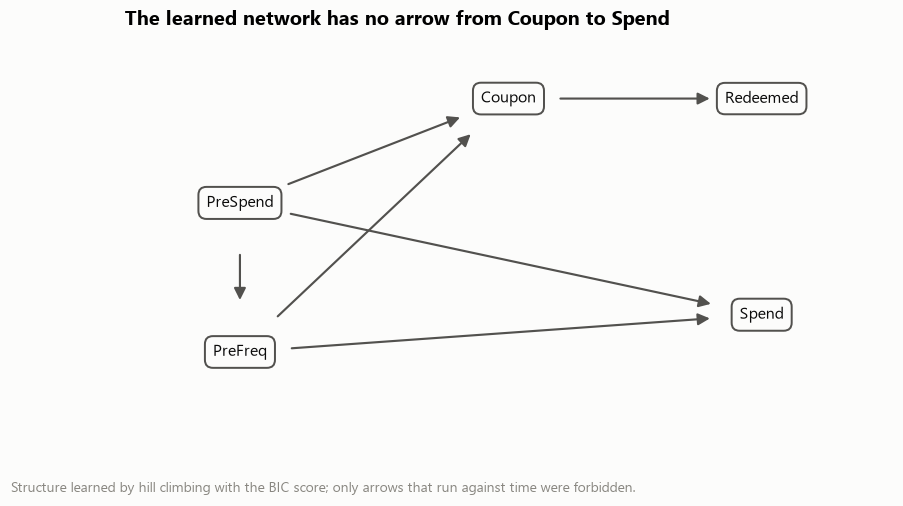

Learned edges: Coupon -> Redeemed, PreFreq -> Coupon, PreFreq -> Spend, PreSpend -> Coupon, PreSpend -> PreFreq, PreSpend -> Spend
BIC of the learned network: -22,815.  BIC of the Section 5 graph: -23,063 (higher is better).
Raw share with high spending:  no coupon 28%, coupon 66%
Network, for a household with high PreSpend and high PreFreq:  no coupon 75%, coupon 75%


In [40]:
from pgmpy.estimators import HillClimbSearch, ExpertKnowledge, BIC
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

logging.getLogger("pgmpy").setLevel(logging.ERROR)
three = lambda s: pd.qcut(s.rank(method="first"), 3, labels=["low", "mid", "high"]).astype(str)
BN = pd.DataFrame({
    "PreFreq": three(STK.active_b0 + STK.active_b1 + STK.active_b2),
    "PreSpend": three(STK.y_base),
    "Coupon": np.where(STK["T"] == 1, "yes", "no"),
    "Redeemed": np.where(STK.redeemed == 1, "yes", "no"),
    "Spend": three(STK.y_during),
})

# Time order: pre-campaign variables -> coupon -> redemption and spending. Arrows against time are forbidden.
tier = {"PreFreq": 0, "PreSpend": 0, "Coupon": 1, "Redeemed": 2, "Spend": 2}
forbidden = [(a, b) for a in tier for b in tier if a != b and tier[a] > tier[b]] + [("Spend", "Redeemed")]
learned = HillClimbSearch(BN).estimate(scoring_method="bic-d", expert_knowledge=ExpertKnowledge(forbidden_edges=forbidden), show_progress=False)
learned_edges = sorted(learned.edges())

# Compare with the graph of Section 5 written on the same five variables
assumed_edges = [("PreSpend", "PreFreq"), ("PreFreq", "Coupon"), ("PreSpend", "Coupon"), ("PreFreq", "Spend"), ("PreSpend", "Spend"),
                 ("Coupon", "Redeemed"), ("PreFreq", "Redeemed"), ("PreSpend", "Redeemed"), ("Coupon", "Spend"), ("Redeemed", "Spend")]
scorer = BIC(BN)
bic_learned = scorer.score(DiscreteBayesianNetwork(learned_edges))
bic_assumed = scorer.score(DiscreteBayesianNetwork(assumed_edges))

BN_NODES = {"PreSpend": (1.5, 2.9, "PreSpend", True), "PreFreq": (1.5, 0.9, "PreFreq", True), "Coupon": (5.0, 4.3, "Coupon", True),
            "Redeemed": (8.3, 4.3, "Redeemed", True), "Spend": (8.3, 1.4, "Spend", True)}
draw_dag(BN_NODES, learned_edges, "The learned network has no arrow from Coupon to Spend", "A1_bayes_net",
         "Structure learned by hill climbing with the BIC score; only arrows that run against time were forbidden.")

# Fit the conditional probability tables and query the network
bn_model = DiscreteBayesianNetwork(learned_edges)
bn_model.fit(BN)
infer = VariableElimination(bn_model)
query = {}
for coupon in ("no", "yes"):
    q = infer.query(["Spend"], evidence={"Coupon": coupon, "PreSpend": "high", "PreFreq": "high"}, show_progress=False)
    query[coupon] = dict(zip(q.state_names["Spend"], q.values))
raw_high = BN.groupby("Coupon").Spend.apply(lambda s: (s == "high").mean())

RESULTS["bayes_net"] = dict(learned_edges=[list(e) for e in learned_edges], bic_learned=float(bic_learned), bic_assumed=float(bic_assumed),
                            coupon_to_spend=("Coupon", "Spend") in learned_edges, redeemed_to_spend=("Redeemed", "Spend") in learned_edges,
                            p_high_given_coupon={k: float(v["high"]) for k, v in query.items()}, raw_p_high=raw_high.to_dict())
print("Learned edges:", ", ".join(f"{a} -> {b}" for a, b in learned_edges))
print(f"BIC of the learned network: {bic_learned:,.0f}.  BIC of the Section 5 graph: {bic_assumed:,.0f} (higher is better).")
print(f"Raw share with high spending:  no coupon {raw_high['no']:.0%}, coupon {raw_high['yes']:.0%}")
print(f"Network, for a household with high PreSpend and high PreFreq:  no coupon {query['no']['high']:.0%}, coupon {query['yes']['high']:.0%}")

**Reading the output.**

- The search keeps the arrows from pre-campaign habits to the coupon (the retailer's selection), from habits to spending (habits persist), and from the coupon to redemption.
- **It does not keep an arrow from Coupon to Spend, or from Redeemed to Spend.** Once pre-campaign habits are in the network, knowing whether a household got the campaign adds too little about its spending to be worth the extra parameters. BIC prefers this sparser network to the graph we drew in Section 5.
- The query shows the same thing as a number: in the raw data, households with a coupon are more than twice as likely to be high spenders (66% against 28%); in the network, a household with high pre-campaign spending and frequency has the same chance of being a high spender with or without the campaign.

This is corroboration, not proof. Three-level categories are coarse, and the absence of an edge means "too weak for BIC to keep at this sample size", which is the same statement as "no detectable effect".

## Appendix B. Repeated campaigns and the g-formula (Week 7, temporal DAGs)

The main analysis looks at each household's *first* campaign. One reason is the problem Week 7 raised with time-varying treatments. Households receive campaigns repeatedly, and the retailer re-selects them each time from their recent shopping:

> A1 (first campaign) → L (shopping in between) → A2 (second campaign) → Y, and also A1 → Y, L → Y

Shopping in between (L) is a **confounder** for the second campaign, because it drives both selection and later spending. It is also a **mediator** for the first campaign, because the first campaign may have changed it. Adjusting for L in one regression blocks part of the first campaign's effect; not adjusting leaves the second campaign confounded. The g-formula handles this by modelling L under each treatment history and averaging over it.

Here A1 is the campaign starting in week 60, A2 the campaign starting in week 85, L is spending and shopping frequency in weeks 61 to 76, and Y is spending in weeks 85 to 91. Households already treated before week 60, or first treated between the two campaigns, are left out.

In [41]:
got_c18 = members[18]
pool_g = cohort.index[(cohort == 60) | (cohort == 0) | (cohort >= 85)]
GF = pd.DataFrame(index=pool_g)
GF["A1"] = (cohort.loc[pool_g] == 60).astype(int)
GF["A2"] = [int(h in got_c18) for h in pool_g]
for j, (a, b) in enumerate([(44, 51), (36, 43), (28, 35), (17, 27)]):              # history before the first campaign
    GF[f"h_spend{j}"] = SPEND.loc[pool_g, a:b].mean(axis=1)
    GF[f"h_active{j}"] = ACTIVE.loc[pool_g, a:b].mean(axis=1)
GF["L_spend"] = SPEND.loc[pool_g, 61:76].mean(axis=1)                                 # between the two campaigns
GF["L_active"] = ACTIVE.loc[pool_g, 61:76].mean(axis=1)
GF["Y"] = SPEND.loc[pool_g, 85:91].mean(axis=1)
HIST = [c for c in GF.columns if c.startswith("h_")]


def g_formula(G):
    """Parametric g-formula with linear models. Returns contrasts against 'no campaign at all'."""
    m_L = {l: sm.OLS(G[l], sm.add_constant(G[["A1"] + HIST])).fit() for l in ("L_spend", "L_active")}       # L given A1 and history
    m_Y = sm.OLS(G.Y, sm.add_constant(G[["A1", "A2", "L_spend", "L_active"] + HIST])).fit()                  # Y given everything

    def expected_y(a1, a2):
        Z = sm.add_constant(G[HIST].assign(A1=a1)[["A1"] + HIST], has_constant="add")
        W = pd.DataFrame({"const": 1.0, "A1": a1, "A2": a2, "L_spend": m_L["L_spend"].predict(Z), "L_active": m_L["L_active"].predict(Z)})
        W = pd.concat([W, G[HIST]], axis=1)
        return float(m_Y.predict(W[m_Y.params.index]).mean())

    none = expected_y(0, 0)
    return dict(both_campaigns=expected_y(1, 1) - none, first_only=expected_y(1, 0) - none, second_only=expected_y(0, 1) - none,
                one_regression_adjusting_for_L=m_Y.params["A1"] + m_Y.params["A2"], first_campaign_on_L_spend=m_L["L_spend"].params["A1"],
                level_without_campaigns=none)


GFr = GF.reset_index(drop=True)
gf_point = g_formula(GFr)
rng = np.random.default_rng(SEED)
gf_draws = pd.DataFrame([g_formula(GFr.sample(len(GFr), replace=True, random_state=int(rng.integers(1e9))).reset_index(drop=True)) for _ in range(300)])
gf = pd.DataFrame({"estimate ($/week)": gf_point, "95% CI low": gf_draws.quantile(0.025), "95% CI high": gf_draws.quantile(0.975)})
RESULTS["g_formula"] = dict(counts=pd.crosstab(GF.A1, GF.A2).to_dict(), table=gf.reset_index().rename(columns={"index": "quantity"}).to_dict("records"))
print("Households by treatment history (rows: first campaign, columns: second campaign):")
print(pd.crosstab(GF.A1.map({0: "no first", 1: "first"}), GF.A2.map({0: "no second", 1: "second"})).to_string(), "\n")
gf.round(2)

Households by treatment history (rows: first campaign, columns: second campaign):
A2        no second  second
A1                         
first           129     291
no first        859      86 



,estimate ($/week),95% CI low,95% CI high
both_campaigns,1.010,-5.580,8.020
first_only,2.990,-2.120,9.490
second_only,-1.980,-5.870,2.470
one_regression_adjusting_for_L,-0.080,-5.210,5.270
first_campaign_on_L_spend,1.570,-3.190,6.680
level_without_campaigns,25.530,22.890,28.110


**Reading the table.** Receiving both campaigns, the first only, or the second only: none of the three contrasts with "no campaign" can be told apart from zero, and neither can the effect of the first campaign on shopping in between. The single regression that adjusts for L gives a similar, equally inconclusive number.

This is a sketch, not a second main result. It uses linear models, a population that includes many light shoppers (so it is closer to an ATE than to the ATT of Section 7), and it ignores the smaller campaigns in between. What it adds is the reasoning: with repeated, re-targeted campaigns, a naive regression on "number of campaigns received" would be biased in ways that are hard to sign, which is why the main analysis stays with the first campaign.

## Appendix C. Why twelve covariates and not one: measurement error in the confounder (Week 8)

The confounder in Section 5 is the household's shopping *habit*. We never observe a habit; we observe noisy indicators of it: spending, number of trips and active weeks over a few weeks. Week 8's measurement models describe exactly this situation: several observed indicators of one latent factor.

With three indicators and one factor, the loadings can be computed directly from the three correlations. The squared loading is the indicator's reliability: the share of its variance that reflects the latent habit and not week-to-week noise.

In [42]:
# One-factor model for three standardized indicators of baseline engagement (exactly identified, so it has a closed form):
# loading_1 = sqrt(r12 * r13 / r23), and so on.
ind = ["spend_b0", "trips_b0", "active_b0"]
Zc = STK[ind] - STK.groupby("cohort")[ind].transform("mean")           # remove cohort means
Rm = Zc.corr().values
load = np.sqrt([Rm[0, 1] * Rm[0, 2] / Rm[1, 2], Rm[0, 1] * Rm[1, 2] / Rm[0, 2], Rm[0, 2] * Rm[1, 2] / Rm[0, 1]])
measurement = pd.DataFrame({"loading": load, "reliability": load ** 2}, index=["Weekly spending", "Trips per week", "Share of weeks with a trip"])

# What happens to the coefficient on T as more indicators of the habit are adjusted for
dm = cohort_dummies.values
steps = [("No covariates", []), ("Baseline spending only", ["spend_b0"]), ("All three baseline indicators", ind),
         ("Baseline and the period before", [f"{m}_b{j}" for j in (0, 1) for m in ("spend", "trips", "active")]), ("All twelve measures", XCOLS)]
ladder = pd.DataFrame([dict(adjusting_for=lab, campaign=ols_coef(STK.y_during.values, Tv, np.column_stack([STK[cols].values, dm]) if cols else dm),
                            placebo=ols_coef(STK.y_check.values, Tv, np.column_stack([STK[cols].values, dm]) if cols else dm)) for lab, cols in steps])
RESULTS["measurement"] = dict(loadings=measurement.reset_index().rename(columns={"index": "indicator"}).to_dict("records"), ladder=ladder.to_dict("records"))
print(measurement.round(2).to_string(), "\n")
ladder.round(2)

                            loading  reliability
Weekly spending               0.810        0.660
Trips per week                0.870        0.760
Share of weeks with a trip    0.810        0.660 



,adjusting_for,campaign,placebo
0,No covariates,25.750,26.200
1,Baseline spending only,2.650,2.430
2,All three baseline indicators,3.760,3.220
3,Baseline and the period before,1.370,0.600
4,All twelve measures,0.900,0.210


**Reading the output.**

- No single indicator measures the habit cleanly. Roughly a quarter to a third of each indicator's variance is noise.
- Adjusting for a noisy proxy removes only part of the confounding. With baseline spending alone, the coefficient on the campaign is still about +\$2.6, and the placebo coefficient is about the same, which is how we know it is leftover confounding and not an effect. Adding the other two indicators from the same weeks does not help. Adding earlier periods does: with all twelve measures both coefficients are under \$1.
- That is the reason the analysis adjusts for twelve measures across four periods. It is also another reading of regression to the mean (Section 4.3): a household selected on one noisy measurement looks more extreme than its habit really is.

A full structural equation model with a latent habit was also tried (one and two factors, fitted by maximum likelihood). It fitted poorly: these indicators share period-specific shocks that a one- or two-factor model cannot represent, and its estimate failed the placebo test. We therefore keep the simpler statement above and do not report that model as a result.

In [43]:
# Write every externally quoted number to outputs/results.json for the HTML report and the slides
def clean(o):
    """Convert numpy types to plain Python types so the result can be written as JSON."""
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    return o


RESULTS["meta"] = dict(n_households_all=int(len(hh)), n_households_sample=int(len(S)), weeks=[17, 101],
                       n_campaigns=int(len(camp)), cohorts=COHORTS, seed=SEED, boot=BOOT)
(ROOT / "outputs" / "results.json").write_text(json.dumps(clean(RESULTS), ensure_ascii=False, indent=1), encoding="utf-8")

m = RESULTS["main"]["windows"]["dr"]["during"]
print("Key numbers")
print(f"  Effect during the campaign: {m['est']:+.2f} $/week ({100 * m['est'] / BASE:+.1f}%), 95% CI [{100 * m['lo'] / BASE:+.1f}%, {100 * m['hi'] / BASE:+.1f}%]")
print(f"  Recipients vs non-recipients, spending ratio: {RESULTS['naive']['ratio_after']:.1f}x ({RESULTS['naive']['ratio_before']:.1f}x before any coupon)")
print(f"  Recipient households that never redeemed: {RESULTS['funnel']['share_never_redeemed']:.0%}")
print(f"  Redeemed items in a sub-category bought in the last six months: {RESULTS['habit']['same_subcat_redeemed']:.0%}")
print(f"  Households per group needed to detect a 1% lift: {RESULTS['power']['table'][1]['households_per_group']:,}")

Key numbers
  Effect during the campaign: +0.59 $/week (+1.3%), 95% CI [-7.6%, +11.3%]
  Recipients vs non-recipients, spending ratio: 4.5x (4.5x before any coupon)
  Recipient households that never redeemed: 73%
  Redeemed items in a sub-category bought in the last six months: 82%
  Households per group needed to detect a 1% lift: 71,805
